# Offline Wikipedia hybrid RAG — shards 00000–00007

This notebook uses **existing embeddings and the validated cosine HNSW index** in PostgreSQL, plus a new **BM25 index of the exact same passages**. Coverage is **1,250,310 articles / 5,665,798 passages** from the first eight files of the `20231101.en` snapshot. It does not search the other 33 shards or the pilot collection.

Run the cells in order on this Mac using the Miniforge Python kernel. No embedding or HNSW reconstruction runs here. `RUN_INGEST=False` and `BUILD_INDEX=False` are intentional. The interface supports **Hybrid**, **Vector only**, and **BM25 only**, with 1/3/5 passages and both answer-fusion methods. The final section contains **150 source-verified practice questions** across 16 editorial topic groups.


## Portable project folder and database settings
Keep notebooks 01–05 together in the project folder. All data, models and results use paths relative to that folder through `pathlib`, on macOS, Windows or Linux. The code searches the kernel working directory and its parents for notebook 01. Jupyter does not reliably expose the open notebook's file path; if its working directory is elsewhere, set `RAG_PROJECT_DIR` to the project folder before running configuration. A relative override is resolved from the kernel working directory.

Optional override in a cell before configuration:
```python
import os
os.environ['RAG_PROJECT_DIR'] = 'path/to/your/project'  # Relative, or your native absolute path.
```

Database settings in 03–05 follow this precedence: `RAG_PG_DSN` / `RAG_PG_SCHEMA` environment overrides, then `data/rag_setup_connection.json` saved by 03, then the local defaults. On a new machine, run 03 to prepare the connection before 04/05. Supply the PostgreSQL role in the DSN when it differs from your operating-system username. Credentials remain in your environment or PostgreSQL password file; do not put passwords in notebook cells. A saved endpoint is machine-specific: override it when moving to another server. Notebook 03 saves the effective endpoint without its password.

The scope is intentional: notebook 01 downloads **all 41 English shards**, and notebook 04 embeds only **00000–00007** to limit computation. No download or embedding scope is changed by the portable paths.


In [1]:
from pathlib import Path
import os,sys,json,time,re,hashlib,importlib.util
# Paths are relative to the project folder, using native macOS/Windows separators.
def resolve_project_root():
    override = os.environ.get('RAG_PROJECT_DIR')
    if override:
        folder = Path(override).expanduser().resolve()
        if not folder.is_dir():
            raise FileNotFoundError('RAG_PROJECT_DIR must point to an existing project folder.')
        return folder
    current = Path.cwd().resolve()
    for folder in (current, *current.parents):
        if (folder/'01_download_english_wikipedia_dataset.ipynb').is_file():
            return folder
    raise RuntimeError('Open Jupyter from the folder containing notebooks 01–05, or set RAG_PROJECT_DIR to that folder.')

ROOT = resolve_project_root()
connection_file = ROOT/'data/rag_setup_connection.json'
saved = json.loads(connection_file.read_text(encoding='utf-8')) if connection_file.exists() else {}
DSN = os.environ.get('RAG_PG_DSN') or saved.get('dsn') or 'host=localhost dbname=rag_vectors'
SCHEMA = os.environ.get('RAG_PG_SCHEMA') or saved.get('schema') or 'rag_wiki_bge_full_v1'
PG_DSN = DSN
MODEL_ID='BAAI/bge-small-en-v1.5'
MODEL_REVISION='5c38ec7c405ec4b44b94cc5a9bb96e735b38267a'
EMBED_DIR=ROOT/'models/bge-small-en-v1.5'
MODEL_DIR=ROOT/'models/flan-t5-small'
LEXICAL_PATH=ROOT/'data/wikipedia_pgvector_8shards_bm25.sqlite'
INDEX_KIND='half'
RUN_INGEST=False
BUILD_INDEX=False
RUN_EVALUATION=False
RUN_ANSWER_ABLATIONS=False
QUERY_THREADS=1
CANDIDATES_PER_RETRIEVER=50
EF_SEARCH=200
RRF_CONSTANT=60
LEXICAL_TIMEOUT_SECONDS=3.0
os.environ['HF_HUB_OFFLINE']='1'
os.environ['TRANSFORMERS_OFFLINE']='1'
missing=[m for m in ['pyarrow','psycopg','pgvector','sentence_transformers','transformers','ipywidgets'] if importlib.util.find_spec(m) is None]
if missing:raise RuntimeError('Select the prepared Python kernel; missing: '+', '.join(missing))
if RUN_INGEST or BUILD_INDEX:raise RuntimeError('This notebook consumes existing indexes. Run 04_embed_wikipedia_shards_01_to_08.ipynb for embedding/index preparation.')
print('Python:',sys.executable)
print('Coverage: shards 00000–00007 only. Snapshot: November 2023.')

RERANK_DIR=ROOT/'models/ms-marco-MiniLM-L6-v2'
RERANK_CANDIDATES=30
MAX_GENERATION_TOKENS=160


Python: /opt/homebrew/Caskroom/miniforge/base/bin/python
Coverage: shards 00000–00007 only. Snapshot: November 2023.


## Readiness and storage

PostgreSQL is the source of truth for passage text, metadata, vectors and HNSW. The local SQLite FTS5 sidecar stores only its lexical index and uses PostgreSQL passage IDs as FTS row IDs. It is real BM25, not PostgreSQL `ts_rank` relabelled as BM25. The older `full_wikipedia_bm25.sqlite` is deliberately unused: it has different chunks and covers all 41 shards.

The lexical build is checkpointed, coverage-checked and atomically published only when complete. Startup compares its schema/configuration/coverage fingerprint with PostgreSQL. All queries fetch source text from PostgreSQL. Credentials remain in the environment or `.pgpass`, never saved notebook outputs.


In [2]:
print('Project folder:', ROOT)
print('Embedding/index preparation: 04_embed_wikipedia_shards_01_to_08.ipynb')
if not LEXICAL_PATH.is_file():
    raise RuntimeError('Aligned BM25 index is missing. Run 04_embed_wikipedia_shards_01_to_08.ipynb first.')
print('BM25 file found. PostgreSQL readiness and BM25 alignment are checked when HybridRetriever initializes below.')


Project folder: /Users/amolsingh/Documents/code/IITB-DL
Embedding/index preparation: 04_embed_wikipedia_shards_01_to_08.ipynb
BM25 file found. PostgreSQL readiness and BM25 alignment are checked when HybridRetriever initializes below.


## Retrieval design and rationale

1. Encode the question with the pinned BGE model, its retrieval query prefix and normalized 384-dimensional output. Use the existing `chunks_half_hnsw` cosine index (`m=16`, `ef_construction=128`). `ef_search=200` controls query-time search effort.
2. Run FTS5 BM25 over the **same 5,665,798 passage IDs**, with English stemming, a title weight of 2 and body weight of 1. Quote tokens so user text cannot inject FTS query operators. Query terms are OR-combined after stopword removal.
3. Retrieve up to 50 candidates from each branch. Combine by **reciprocal rank fusion**, `sum(1 / (60 + rank))`; raw cosine and BM25 scores are not numerically comparable. Neither RRF nor similarity scores are confidence probabilities.
4. Deduplicate heavily overlapping spans and cap final context at two passages per article. Fetch text by primary key. Keep source ranks and scores for inspection.
5. Add stored introductory passages from up to ten matched articles, then rerank exact source sentences across those and 30 fused candidates. Preserve original chunks and excerpt offsets. Pack the selected excerpts within 512 input tokens and generate with Flan-T5-small, using up to 160 output tokens. No question-bank answers enter inference.

BM25 runs concurrently with query embedding/vector retrieval. Explicit lexical timeouts degrade Hybrid mode to vector-only retrieval with a visible warning. The UI exposes candidate scores, reranking time, included context, omitted passages and exact model prompts. This is not a guarantee of perfect answers or sub-10-ms latency.

References: [SQLite FTS5](https://www.sqlite.org/fts5.html), [pgvector](https://github.com/pgvector/pgvector), [Sentence Transformers rerankers](https://www.sbert.net/docs/cross_encoder/pretrained_models.html), [Flan-T5-small](https://huggingface.co/google/flan-t5-small).


In [3]:
from pathlib import Path
from contextlib import contextmanager
from collections import OrderedDict
import os, re, json, time, hashlib, sqlite3, shutil, math, bisect
import numpy as np
import pyarrow.parquet as pq
import psycopg
from psycopg.rows import dict_row
from pgvector.psycopg import register_vector
from pgvector import HalfVector
from sentence_transformers import SentenceTransformer

QUERY_PREFIX = 'Represent this sentence for searching relevant passages: '
DIM = 384

def connect_pg(dsn):
    conn = psycopg.connect(dsn, autocommit=True, row_factory=dict_row, connect_timeout=5)
    register_vector(conn)
    return conn

def schema_name(name):
    if not re.fullmatch(r'rag_[a-z0-9_]{1,50}',name):
        raise ValueError('Schema must start rag_ and contain only lowercase letters, digits, underscores')
    return name

class Embedder:
    def __init__(self,path,model_id,revision,device='cpu',batch_size=64):
        import torch
        torch.set_num_threads(4)
        self.model=SentenceTransformer(str(path),device=device,local_files_only=True,trust_remote_code=False)
        self.model.max_seq_length=256
        self.tokenizer=self.model.tokenizer
        self.model_id,self.revision,self.batch_size=model_id,revision,batch_size
        self.prefix=QUERY_PREFIX if model_id=='BAAI/bge-small-en-v1.5' else ''
    def encode(self,texts,query=False):
        texts=[self.prefix+t if query else t for t in texts]
        lengths=[len(self.tokenizer.encode(t,add_special_tokens=True)) for t in texts]
        if any(n>256 for n in lengths):
            raise ValueError('Input exceeds 256 tokens; chunk or shorten it instead of silently truncating.')
        vectors=self.model.encode(texts,batch_size=self.batch_size,normalize_embeddings=True,
            convert_to_numpy=True,show_progress_bar=False).astype('float32')
        if vectors.shape!=(len(texts),DIM) or not np.isfinite(vectors).all():
            raise ValueError('Invalid embedding shape or nonfinite embedding')
        return vectors
    def chunk(self,article):
        # Prefer sentence endings within a 220-token body; retain exact source offsets.
        text=article['text']
        encoded=self.tokenizer(text,add_special_tokens=False,return_offsets_mapping=True,
                               truncation=False,verbose=False)
        offsets=encoded['offset_mapping'];n=len(offsets)
        title_ids=self.tokenizer.encode(article['title'],add_special_tokens=False)[:28]
        embed_title=self.tokenizer.decode(title_ids)
        sentence_ends=sorted(m.end() for m in re.finditer(r'[.!?](?:\s+|$)|\n\s*\n',text))
        start=0;ordinal=0
        while start<n:
            end=min(start+220,n)
            if end<n:
                choices=[j for j in range(start+110,end) if bisect.bisect_left(sentence_ends,offsets[j-1][1]) < bisect.bisect_right(sentence_ends,offsets[j][0])]
                if choices:end=choices[-1]
            char_start,char_end=offsets[start][0],offsets[end-1][1]
            body=text[char_start:char_end]
            embed_text=embed_title+'\n'+body
            # Re-tokenization at boundaries can differ from token slices.
            while len(self.tokenizer.encode(embed_text))>256 and end>start+1:
                end-=1;char_end=offsets[end-1][1];body=text[char_start:char_end];embed_text=embed_title+'\n'+body
            yield dict(chunk_id=f"{article['id']}:{char_start}:{char_end}",article_id=str(article['id']),
                title=article['title'],url=article['url'],text=body,char_start=char_start,char_end=char_end,
                embed_text=embed_text)
            if end==n:break
            start=max(start+1,end-32);ordinal+=1

W1028 07:47:33.141000 43467 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
W1028 07:47:33.516000 43467 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1028 07:47:33.538000 43467 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


In [4]:
from concurrent.futures import ThreadPoolExecutor
from collections import OrderedDict
import copy, sqlite3, json, re, time

LEXICAL_STOPWORDS=set('a an the is are was were be been being what which who whom whose when where why how do does did can could would should of in on at to for from with by as and or it its this that these those tell me about explain please'.split())

def lexical_query(question):
    # Quote individual tokens; never execute user-supplied FTS operators.
    terms=list(dict.fromkeys(t.casefold() for t in re.findall(r'\w+',question,re.UNICODE) if t.casefold() not in LEXICAL_STOPWORDS))
    if len(terms)>32: raise ValueError('Use at most 32 content words in a query.')
    return ' OR '.join('"'+t+'"' for t in terms)

def rrf_rank(vector_rows,lexical_rows,constant=60):
    merged={}
    for source,rows in [('vector',vector_rows),('bm25',lexical_rows)]:
        for rank,row in enumerate(rows,1):
            item=merged.setdefault(int(row['id']),dict(id=int(row['id']),rrf_score=0.0,vector_rank=None,bm25_rank=None,similarity=None,bm25_score=None))
            item['rrf_score']+=1.0/(constant+rank)
            item[source+'_rank']=rank
            if source=='vector': item['similarity']=1-float(row['distance'])
            else: item['bm25_score']=float(row['score'])
    return sorted(merged.values(),key=lambda x:(-x['rrf_score'],x['id']))

class HybridRetriever:
    """Read-only, same-passage BM25 + cosine HNSW with RRF and explicit degradation."""
    def __init__(self,dsn,schema,embedder,lexical_path,candidates=50,ef_search=200,rrf_constant=60,lexical_timeout=3.0):
        self.schema=schema_name(schema);self.embedder=embedder;self.path=Path(lexical_path)
        self.db=connect_pg(dsn);self.pool=ThreadPoolExecutor(max_workers=1,thread_name_prefix='bm25')
        self.candidates=int(candidates);self.ef_search=int(ef_search);self.rrf_constant=rrf_constant;self.lexical_timeout=lexical_timeout
        if not 1<=self.candidates<=self.ef_search<=1000:raise ValueError('Invalid candidate/ef_search budget')
        self.db.execute("SET statement_timeout='10s'")
        self.meta={r['key']:r['value'] for r in self.db.execute(f'SELECT * FROM {self.schema}.metadata')}
        if not self.meta.get('subset_ready') or not self.meta.get('index_half'):raise RuntimeError('Eight-shard cosine HNSW collection is not ready.')
        cfg=self.meta['config']
        if (cfg['model_id'],cfg['model_revision'])!=(embedder.model_id,embedder.revision):raise RuntimeError('Embedding model mismatch')
        self.audit=self.meta['subset_audit'];self.scope='eight-shard subset (00000–00007)'
        self._validate_lexical()
        self.cache=OrderedDict();self.last_timings={};self.last_warnings=[]
    def _validate_lexical(self):
        if not self.path.exists():raise RuntimeError('Aligned BM25 index not ready. Run 04_embed_wikipedia_shards_01_to_08.ipynb; do not use the older full-corpus BM25 index.')
        with sqlite3.connect(self.path.resolve().as_uri()+'?mode=ro',uri=True) as db:
            m={k:json.loads(v) for k,v in db.execute('SELECT key,value FROM metadata')}
        f=m.get('fingerprint',{})
        if not m.get('complete') or m.get('documents')!=self.audit['chunks'] or f.get('schema')!=self.schema or f.get('audit')!=self.audit or f.get('config')!=self.meta['config']:
            raise RuntimeError('BM25 corpus/model fingerprint does not match PostgreSQL.')
    def _lexical(self,question):
        start=time.perf_counter();q=lexical_query(question)
        if not q:return [],0.0,[]
        conn=sqlite3.connect(self.path.resolve().as_uri()+'?mode=ro',uri=True)
        conn.execute('PRAGMA query_only=ON')
        deadline=start+self.lexical_timeout
        conn.set_progress_handler(lambda:int(time.perf_counter()>deadline),1000)
        try:
            rows=conn.execute("SELECT rowid,rank FROM search WHERE search MATCH ? AND rank MATCH 'bm25(2.0,1.0)' ORDER BY rank LIMIT ?",(q,self.candidates)).fetchall()
            return [dict(id=r[0],score=r[1]) for r in rows],(time.perf_counter()-start)*1000,[]
        except sqlite3.OperationalError as exc:
            if 'interrupted' not in str(exc).lower():raise
            return [],(time.perf_counter()-start)*1000,['BM25 exceeded its time budget; hybrid results use vector retrieval only.']
        finally:conn.close()
    def search(self,question,k=3,use_cache=True,mode='hybrid',candidate_pool=False):
        if mode not in ('hybrid','vector','bm25'):raise ValueError('Unknown retrieval mode')
        if not question.strip() or not 1<=k<=100:raise ValueError('Enter a question; k must be 1–100.')
        if len(question)>2000:raise ValueError('Please shorten the question to 2,000 characters or fewer.')
        key=(question.strip(),k,mode,candidate_pool)
        if use_cache and key in self.cache:
            hits,warnings=self.cache[key];self.cache.move_to_end(key)
            self.last_warnings=list(warnings);self.last_timings=dict(cache_hit=True,total_ms=0,query_embedding_ms=0,ann_ms=0,bm25_ms=0,fusion_fetch_ms=0)
            return copy.deepcopy(hits)
        start=time.perf_counter();future=self.pool.submit(self._lexical,question) if mode=='hybrid' else None
        vector=[];lexical=[];warnings=[];embedding_ms=ann_ms=bm25_ms=0.0;v=None
        if mode in ('hybrid','vector'):
            t=time.perf_counter();v=HalfVector(self.embedder.encode([question],query=True)[0]);embedding_ms=(time.perf_counter()-t)*1000
            t=time.perf_counter()
            with self.db.transaction():
                self.db.execute('SET TRANSACTION READ ONLY')
                self.db.execute("SELECT set_config('hnsw.ef_search',%s,true)",(str(self.ef_search),))
                vector=self.db.execute(f'SELECT id,embedding <=> %s::halfvec(384) AS distance FROM {self.schema}.chunks ORDER BY embedding <=> %s::halfvec(384) LIMIT %s',(v,v,self.candidates)).fetchall()
            ann_ms=(time.perf_counter()-t)*1000
        if mode=='hybrid':lexical,bm25_ms,warnings=future.result()
        elif mode=='bm25':
            lexical,bm25_ms,warnings=self._lexical(question)
            if warnings:raise TimeoutError('BM25 exceeded its time budget. Use more specific terms or Hybrid mode.')
        t=time.perf_counter();ranked=rrf_rank(vector,lexical,self.rrf_constant)
        ids=[r['id'] for r in ranked]
        rows=self.db.execute(f'SELECT id,chunk_id AS passage_id,article_id,title,url,body AS text,char_start,char_end FROM {self.schema}.chunks WHERE id=ANY(%s)',(ids,)).fetchall() if ids else []
        byid={r['id']:r for r in rows}
        if set(ids)!=set(byid):raise RuntimeError('Lexical index contains stale passage IDs; rebuild it.')
        self.last_branch_candidates={
            'vector':[byid[r['id']] for r in vector],
            'bm25':[byid[r['id']] for r in lexical],
            'rrf':[byid[r['id']] for r in ranked]}
        selected=[];article_counts={}
        for rank,r in enumerate(ranked,1):
            hit=dict(byid[r['id']],**{key:value for key,value in r.items() if key!='id'},retrieval_rank=rank)
            if not candidate_pool and article_counts.get(hit['article_id'],0)>=2:continue
            duplicate=False
            for prev in selected:
                if hit['article_id']!=prev['article_id']:continue
                overlap=max(0,min(hit['char_end'],prev['char_end'])-max(hit['char_start'],prev['char_start']))
                if overlap/max(1,min(hit['char_end']-hit['char_start'],prev['char_end']-prev['char_start']))>.6:duplicate=True;break
            if duplicate and not candidate_pool:continue
            selected.append(hit);article_counts[hit['article_id']]=article_counts.get(hit['article_id'],0)+1
            if len(selected)==k:break
        self.last_warnings=warnings
        self.last_timings=dict(cache_hit=False,query_embedding_ms=embedding_ms,ann_ms=ann_ms,bm25_ms=bm25_ms,fusion_fetch_ms=(time.perf_counter()-t)*1000,total_ms=(time.perf_counter()-start)*1000,vector_candidates=len(vector),bm25_candidates=len(lexical))
        if use_cache:
            self.cache[key]=(copy.deepcopy(selected),list(warnings))
            while len(self.cache)>128:self.cache.popitem(last=False)
        return selected
    def close(self):
        self.pool.shutdown(wait=True,cancel_futures=True);self.db.close()


In [5]:
import torch
query_embedder=Embedder(EMBED_DIR,MODEL_ID,MODEL_REVISION,device='cpu',batch_size=32)
torch.set_num_threads(QUERY_THREADS)
if 'retriever' in globals():retriever.close()
retriever=HybridRetriever(PG_DSN,SCHEMA,query_embedder,LEXICAL_PATH,candidates=CANDIDATES_PER_RETRIEVER,ef_search=EF_SEARCH,rrf_constant=RRF_CONSTANT,lexical_timeout=LEXICAL_TIMEOUT_SECONDS)
idx=retriever.db.execute("SELECT i.indisvalid,pg_get_indexdef(i.indexrelid) AS definition FROM pg_index i WHERE i.indexrelid=to_regclass(%s)",(SCHEMA+'.chunks_half_hnsw',)).fetchone()
if not idx or not idx['indisvalid'] or 'halfvec_cosine_ops' not in idx['definition']:raise RuntimeError('Expected valid cosine HNSW index is missing.')
print('Ready:',retriever.scope, retriever.audit['articles'],'articles,',retriever.audit['chunks'],'passages')
print(idx['definition'])


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Ready: eight-shard subset (00000–00007) 1250310 articles, 5665798 passages
CREATE INDEX chunks_half_hnsw ON rag_wiki_bge_full_v1.chunks USING hnsw (embedding halfvec_cosine_ops) WITH (m='16', ef_construction='128')


## Flan-T5-small with focused source evidence

The Darwin regression exposed a mismatch: a relevant article could be retrieved while the correct sentence was excluded from the final context. The revised reranker scores source sentences across fused candidates and article introductions, then selects up to k distinct passages. Exact text and offsets are preserved, and the UI exposes both the selected excerpt and its original chunk. This is context compression, not generated evidence.

Concatenate supplies the selected excerpts together. Generate from evidence processes each separately before final synthesis from original source excerpts. The 512-token input limit and packing details remain explicit. Sentence splitting is heuristic and can lose neighboring context; this is measured rather than assumed correct.

Concise mode uses a direct context/question prompt. Prose prompting was tested but produced some fluent factual errors, so it is not enabled in the UI. The model may still return a noun phrase; a short factual answer is acceptable when correct. No canned answer or question-bank lookup is used.


In [6]:
def offline_mode() -> None:
    os.environ["HF_HUB_OFFLINE"] = "1"
    os.environ["HF_DATASETS_OFFLINE"] = "1"
    os.environ["TRANSFORMERS_OFFLINE"] = "1"
    os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
    os.environ["TOKENIZERS_PARALLELISM"] = "false"


In [7]:
UNKNOWN = "I don't know based on the provided evidence."
WORD = re.compile(r"\w+", re.UNICODE)
STOPWORDS = set(
    "a an the and or but of to in on at for from by with as is are was were be "
    "been being do does did has have had what which who whom whose when where "
    "why how can could would should will may might that this these those it its "
    "into about according many much name tell me give".split()
)


In [8]:
def span(text: str, candidate: str) -> str | None:
    """Return an original-text span, matching complete casefolded word tokens."""
    needles = [m.group().casefold() for m in WORD.finditer(candidate)]
    if not needles:
        return None
    matches = list(WORD.finditer(text))
    haystack = [m.group().casefold() for m in matches]
    for i in range(len(haystack) - len(needles) + 1):
        if haystack[i : i + len(needles)] == needles:
            return text[matches[i].start() : matches[i + len(needles) - 1].end()]
    return None

def is_unknown(text: str) -> bool:
    normalized = " ".join(WORD.findall(text.casefold()))
    return not normalized or normalized in {
        "unknown", "unanswerable", "not enough information", "not provided",
        "i don t know", "i do not know", "no answer", "not in the context",
        "i don t know based on the provided evidence",
    }

def passages(article: dict, chunk_words: int = 100, overlap: int = 25):
    if chunk_words < 1 or overlap < 0 or overlap >= chunk_words:
        raise ValueError("Require chunk_words > overlap >= 0.")
    text = article["text"]
    words = list(re.finditer(r"\S+", text))
    for ordinal, start in enumerate(range(0, len(words), chunk_words - overlap)):
        end = min(start + chunk_words, len(words))
        char_start, char_end = words[start].start(), words[end - 1].end()
        yield {
            "passage_id": f'{article["id"]}:{ordinal}',
            "article_id": str(article["id"]),
            "title": article["title"],
            "url": article["url"],
            "text": text[char_start:char_end],
            "char_start": char_start,
            "char_end": char_end,
        }
        if end == len(words):
            break


In [9]:
class Generator:
    """Flan-T5-small receives retrieved passage text, not a lookup-table answer."""
    def __init__(self,model_dir=None,device='cpu',threads=1,max_input_tokens=512,max_new_tokens=160):
        offline_mode()
        import torch
        from transformers import AutoModelForSeq2SeqLM,AutoTokenizer
        self.torch=torch;torch.set_num_threads(threads)
        self.tokenizer=AutoTokenizer.from_pretrained(model_dir or MODEL_DIR,local_files_only=True)
        self.model=AutoModelForSeq2SeqLM.from_pretrained(model_dir or MODEL_DIR,local_files_only=True,use_safetensors=True).to(device).eval()
        self.device=device;self.max_input_tokens=max_input_tokens;self.max_new_tokens=max_new_tokens
        if not 128<=max_input_tokens<=512:raise ValueError('Use a validated input budget of 128–512 tokens.')
    def count_tokens(self,text):return len(self.tokenizer.encode(text,verbose=False))
    def render(self,question,evidence,stage='answer',notes=None):
        context='\n\n'.join(f'{p["title"]}: {p["text"]}' for p in evidence)
        if stage=='closed_book':return f'Answer in complete sentences: {question}'
        if stage=='extract':
            return f'Answer using only this passage. If the answer is absent, say unknown.\nContext: {context}\nQuestion: {question}\nAnswer:'
        # No shortest-phrase instruction, sentence-length rejection, or forced minimum length.
        if getattr(self,'answer_style','concise')=='explanation':
            return f'Write a short explanation answering "{question}" using only this evidence. If it does not answer the question, say unknown.\n{context}\nAnswer:'
        return f'Context: {context}\nQuestion: {question}\nAnswer:'

    def pack(self,question,evidence,stage='answer',notes=None):
        """Pack complete chunks in reranked order; clip only an oversized first chunk."""
        if not question.strip():raise ValueError('Enter a question.')
        visible=[];omitted=[]
        if self.count_tokens(self.render(question,[],stage))>self.max_input_tokens-32:raise ValueError('Question leaves too little context space.')
        for p in evidence:
            item={key:p[key] for key in ['passage_id','title','url','text']}
            item['context_truncated']=False
            if self.count_tokens(self.render(question,visible+[item],stage))<=self.max_input_tokens:
                visible.append(item);continue
            if not visible:
                # Preserve an exact prefix and expose clipping; do not silently truncate tokens.
                lo,hi=0,len(item['text'])
                while lo<hi:
                    mid=(lo+hi+1)//2;trial=dict(item,text=item['text'][:mid])
                    if self.count_tokens(self.render(question,[trial],stage))<=self.max_input_tokens:lo=mid
                    else:hi=mid-1
                end=item['text'].rfind(' ',0,lo)
                item['text']=item['text'][:end if end>0 else lo];item['context_truncated']=True
                if item['text']:visible.append(item)
            else:omitted.append(p['passage_id'])
        self.last_pack=dict(requested=len(evidence),included=len(visible),omitted_passage_ids=omitted,truncated_passage_ids=[p['passage_id'] for p in visible if p['context_truncated']],budget=self.max_input_tokens)
        prompt=self.render(question,visible,stage)
        return prompt,visible,self.count_tokens(prompt)
    def generate(self,prompt):
        encoded=self.tokenizer(prompt,return_tensors='pt',truncation=False).to(self.device)
        size=int(encoded.input_ids.shape[1])
        if size>self.max_input_tokens:raise ValueError('Input exceeds the explicit context budget.')
        t=time.perf_counter()
        with self.torch.inference_mode():
            out=self.model.generate(**encoded,do_sample=False,num_beams=4,max_new_tokens=self.max_new_tokens,no_repeat_ngram_size=4,early_stopping=True)
        return dict(text=self.tokenizer.decode(out[0],skip_special_tokens=True).strip(),input_tokens=size,output_tokens=int(out.shape[1]-1),generation_seconds=time.perf_counter()-t)

def source_attribution(visible,originals):
    byid={p['passage_id']:p for p in originals}
    return [dict(passage_id=p['passage_id'],title=p['title'],url=p['url'],visible_excerpt=p['text'],char_start=byid[p['passage_id']]['char_start'],char_end=byid[p['passage_id']]['char_start']+len(p['text']),attribution='supplied_context_not_entailment_verified') for p in visible]

def answer_question(generator,question,retrieved,method='concatenate'):
    if method not in ['concatenate','generate_from_evidence','closed_book']:raise ValueError('Invalid answer-fusion method')
    started=time.perf_counter();trace=[];map_steps=[];visible=[];sources=[];pack_info={};raw=''
    def call(items,stage):
        prompt,shown,_=generator.pack(question,items,stage)
        packing=dict(generator.last_pack)
        result=generator.generate(prompt)
        trace.append(dict(stage=stage,prompt=prompt,visible_evidence=shown,packing=packing,**result))
        return result['text'],shown,packing
    if method=='closed_book':raw,visible,pack_info=call([],'closed_book')
    elif retrieved:
        evidence=retrieved
        if method=='generate_from_evidence':
            # Every selected original passage is separately supplied to Flan-T5-small.
            evidence=[]
            for passage in retrieved:
                draft,shown,packing=call([passage],'extract')
                accepted=not is_unknown(draft)
                map_steps.append(dict(passage_id=passage['passage_id'],candidate=draft,accepted=accepted,visible_evidence=shown))
                if accepted:evidence.append(passage)
            # Summarize original text, not unverified draft claims. No copied-span requirement.
        if evidence:raw,visible,pack_info=call(evidence,'answer')
        sources=source_attribution(visible,retrieved)
    invalid_label=bool(re.fullmatch(r'(?:\[\d+\][\s,.]*)+',raw.strip()))
    answer=UNKNOWN if not raw or is_unknown(raw) or invalid_label else raw
    return dict(question=question,method=method,answer=answer,raw_answer=raw,abstained=answer==UNKNOWN,
        citations=sources if answer!=UNKNOWN else [],retrieved=retrieved,visible_evidence=visible,map_steps=map_steps,trace=trace,
        requested_passages_used=len(retrieved),context_passages_used=len(visible),context_packing=pack_info,
        generation_calls=len(trace),total_input_tokens=sum(t['input_tokens'] for t in trace),total_output_tokens=sum(t['output_tokens'] for t in trace),
        latency_seconds=time.perf_counter()-started,grounding_policy='generation conditioned on cited original passages; semantic support not automatically verified')

class EvidenceReranker:
    def __init__(self,path):
        from sentence_transformers import CrossEncoder
        self.model=CrossEncoder(str(path),device='cpu',max_length=512,local_files_only=True)
        self.cache=OrderedDict();self.last_ms=0;self.cache_hit=False
    def rank(self,question,hits,k=3,use_cache=True):
        key=(question,tuple(h['id'] for h in hits),k)
        if use_cache and key in self.cache:
            self.cache.move_to_end(key);self.last_ms=0;self.cache_hit=True;return copy.deepcopy(self.cache[key])
        t=time.perf_counter();self.cache_hit=False
        if not hits:self.last_ms=0;return []
        scores=self.model.predict([(question,h['title']+'\n'+h['text']) for h in hits],batch_size=8,show_progress_bar=False)
        ordered=sorted([dict(h,rerank_score=float(s)) for h,s in zip(hits,scores)],key=lambda h:(-h['rerank_score'],-h['rrf_score'],h['id']))
        selected=[];counts={}
        for h in ordered:
            if counts.get(h['article_id'],0)>=2:continue
            if any(h['article_id']==p['article_id'] and max(0,min(h['char_end'],p['char_end'])-max(h['char_start'],p['char_start']))/max(1,min(h['char_end']-h['char_start'],p['char_end']-p['char_start']))>.6 for p in selected):continue
            selected.append(h);counts[h['article_id']]=counts.get(h['article_id'],0)+1
            if len(selected)==k:break
        self.last_ms=(time.perf_counter()-t)*1000
        if use_cache:
            self.cache[key]=copy.deepcopy(selected)
            while len(self.cache)>128:self.cache.popitem(last=False)
        return selected


def expand_article_leads(retriever,hits,limit=10):
    """Fetch stored first passages from matched articles, within the same schema."""
    article_ids=list(dict.fromkeys(h['article_id'] for h in hits))[:limit]
    if not article_ids:return hits
    rows=retriever.db.execute(f"""
        SELECT c.id,c.chunk_id AS passage_id,c.article_id,c.title,c.url,
               c.body AS text,c.char_start,c.char_end
        FROM unnest(%s::text[]) AS a(article_id)
        CROSS JOIN LATERAL (
            SELECT * FROM {retriever.schema}.chunks
            WHERE article_id=a.article_id ORDER BY char_start LIMIT 1
        ) c""",(article_ids,)).fetchall()
    seen={h['id'] for h in hits};expanded=list(hits)
    for row in rows:
        if row['id'] not in seen:
            expanded.append(dict(row,rrf_score=0.0,vector_rank=None,bm25_rank=None,
                similarity=None,bm25_score=None,retrieval_rank=None,candidate_origin='article_lead'))
    return expanded

class FocusedEvidenceReranker(EvidenceReranker):
    """Rank exact source spans; preserve the full original chunk for inspection."""
    def rank(self,question,hits,k=3,use_cache=True):
        key=('focused_v1',question,tuple(h['id'] for h in hits),k)
        if use_cache and key in self.cache:
            self.cache.move_to_end(key);self.last_ms=0;self.cache_hit=True
            return copy.deepcopy(self.cache[key])
        start=time.perf_counter();self.cache_hit=False;windows=[]
        for hit in hits:
            for match in re.finditer(r'[^\n.!?]+(?:[.!?](?=\s|$)|$)',hit['text']):
                text=match.group().strip()
                if len(text.split())<5:continue
                # Offsets refer to an exact contiguous substring of the stored passage.
                offset=match.start()+len(match.group())-len(match.group().lstrip())
                windows.append(dict(hit,text=text,original_text=hit['text'],
                    original_char_start=hit['char_start'],original_char_end=hit['char_end'],
                    char_start=hit['char_start']+offset,char_end=hit['char_start']+offset+len(text)))
        if not windows:
            self.last_ms=(time.perf_counter()-start)*1000;return []
        scores=self.model.predict([(question,h['title']+'\n'+h['text']) for h in windows],batch_size=16,show_progress_bar=False)
        ranked=sorted([dict(h,rerank_score=float(s)) for h,s in zip(windows,scores)],key=lambda h:(-h['rerank_score'],-h['rrf_score'],h['id'],h['char_start']))
        selected=[];passages=set();counts={}
        for h in ranked:
            if h['passage_id'] in passages or counts.get(h['article_id'],0)>=2:continue
            if any(h['text']==p['text'] for p in selected):continue
            selected.append(h);passages.add(h['passage_id']);counts[h['article_id']]=counts.get(h['article_id'],0)+1
            if len(selected)==k:break
        self.last_ms=(time.perf_counter()-start)*1000
        if use_cache:
            self.cache[key]=copy.deepcopy(selected)
            while len(self.cache)>128:self.cache.popitem(last=False)
        return selected


## Inspect the evidence, not just the answer

Open **Exact Flan-T5-small prompts and outputs** to inspect the actual evidence. The sources are supplied context, not a claim-level fact-check. The full original chunks remain visible under **Retrieved original passages**. A source match, an answer alias match and a correct answer are three different measurements.

The 500-question suite separates the original 150 factual development questions from 350 sampled retrieval diagnostics across all eight shards. Named-article lookups and verbatim-description lookups are easier than independently authored factual questions; their scores are reported separately. See `docs/hybrid_rag/RAG_500_VALIDATION.md` for results and reproducibility.


In [10]:
# Generation, attribution and reranking are defined together above.


In [11]:
# Focused evidence spans are exact excerpts from original retrieved chunks.
def focus_context(question,hits,k=3):return hits[:k]

generator=Generator(MODEL_DIR,device='cpu',threads=QUERY_THREADS,max_new_tokens=MAX_GENERATION_TOKENS)
reranker=FocusedEvidenceReranker(RERANK_DIR)
def ask_pg(question,k=3,method='concatenate',use_cache=True,retrieval_mode='hybrid',answer_style='concise'):
    if k not in [1,3,5]:raise ValueError('Choose k=1, 3 or 5.')
    if answer_style not in ['concise','explanation']:raise ValueError('Unknown answer style')
    generator.answer_style=answer_style
    start=time.perf_counter()
    candidates=retriever.search(question,RERANK_CANDIDATES,use_cache=use_cache,mode=retrieval_mode,candidate_pool=True)
    timings=dict(retriever.last_timings);warnings=list(retriever.last_warnings)
    lead_start=time.perf_counter()
    candidates=expand_article_leads(retriever,candidates)
    timings['article_leads_ms']=(time.perf_counter()-lead_start)*1000
    hits=reranker.rank(question,candidates,k,use_cache=use_cache)
    timings['rerank_ms']=reranker.last_ms;timings['reranker_cache_hit']=reranker.cache_hit
    result=answer_question(generator,question,hits,method)
    result.update(context_passages=hits,retrieved=hits,candidate_count=len(candidates),timings=timings,scope=retriever.scope,schema=SCHEMA,retrieval_mode=retrieval_mode,warnings=warnings)
    result['timings']['answer_ms']=result['latency_seconds']*1000
    result['timings']['end_to_end_ms']=(time.perf_counter()-start)*1000
    return result

import ipywidgets as widgets
from IPython.display import display,HTML
import html
from urllib.parse import urlparse
if 'pg_panel' in globals():pg_panel.close()
pg_question=widgets.Textarea(description='Question:',placeholder='Who was the sixteenth president of the United States?',layout=widgets.Layout(width='95%',height='80px'))
pg_k=widgets.Dropdown(options=[1,3,5],value=3,description='Passages:')
pg_mode=widgets.Dropdown(options=[('Hybrid: BM25 + vector','hybrid'),('Vector only','vector'),('BM25 only','bm25')],value='hybrid',description='Retrieval:')
pg_method=widgets.Dropdown(options=[('Concatenate','concatenate'),('Generate from evidence','generate_from_evidence')],description='Answer fusion:')
pg_ask=widgets.Button(description='Ask Wikipedia',button_style='primary')
pg_status=widgets.HTML(value=f'Ready — <b>shards 00000–00007 only</b>; {retriever.audit["articles"]:,} articles, {retriever.audit["chunks"]:,} passages.')
pg_output=widgets.Output();last_pg_result=None

def submit_pg(_):
    global last_pg_result
    if not pg_question.value.strip():pg_status.value='Enter a question.';return
    controls=[pg_question,pg_k,pg_mode,pg_method,pg_ask]
    for control in controls:control.disabled=True
    pg_output.clear_output(wait=True);pg_status.value='Retrieving evidence and generating…'
    try:
        r=ask_pg(pg_question.value,pg_k.value,pg_method.value,retrieval_mode=pg_mode.value);last_pg_result=r
        with pg_output:
            display(HTML('<h3>Answer</h3><p>'+html.escape(r['answer'])+'</p>'))
            print('Coverage:',r['scope'],'| Retrieval:',r['retrieval_mode'],'| Cache hit:',r['timings']['cache_hit'])
            for warning in r['warnings']: print('Retrieval notice:',warning)
            for key,value in r['timings'].items():
                if key.endswith('_ms'):print(key+':',round(value,2),'ms')
            print('Context:',r['context_passages_used'],'of',len(r['retrieved']),'selected passages fit the final prompt. Budget: 512 tokens.')
            print('Packing details:',r['context_packing'])
            print('Sources show supplied context; generated claims are not automatically verified.')
            for source in r['citations']:
                url=source['url'] if urlparse(source['url']).scheme in {'http','https'} else '#'
                display(HTML('<h4>Source supplied to Flan-T5-small</h4><a href="'+html.escape(url,quote=True)+'" target="_blank" rel="noopener noreferrer">'+html.escape(source['title'])+'</a><blockquote>'+html.escape(source['visible_excerpt'])+'</blockquote>'))
            details=widgets.Output()
            with details:
                for hit in r['retrieved']:
                    print('Reranker score:',hit.get('rerank_score'))
                    print(hit['title'],'| ID:',hit['passage_id'],'| Vector rank:',hit['vector_rank'],'| BM25 rank:',hit['bm25_rank'],'| RRF:',round(hit['rrf_score'],6))
                    print('Cosine similarity:',hit['similarity'],'| BM25 score (lower is better):',hit['bm25_score'])
                    print('Selected source excerpt:',hit['text'])
                    print('Original chunk:',hit.get('original_text',hit['text']),'\n')
            prompts=widgets.Output()
            with prompts:
                for step in r['trace']:
                    print('STAGE:',step['stage'],'INPUT TOKENS:',step['input_tokens'],'OUTPUT TOKENS:',step['output_tokens'])
                    print(step['prompt']);print('MODEL OUTPUT:',step['text']);print('\n'+'-'*60)
            accordion=widgets.Accordion(children=[details,prompts]);accordion.set_title(0,'Retrieved original passages');accordion.set_title(1,'Exact Flan-T5-small prompts and outputs');accordion.selected_index=None;display(accordion)
        pg_status.value='Complete — eight-shard subset. Generated from supplied evidence; review sources for correctness.'
    except Exception as exc:
        last_pg_result=None;pg_status.value='Request failed.'
        with pg_output:print(type(exc).__name__+': '+str(exc))
    finally:
        for control in controls:control.disabled=False
pg_ask.on_click(submit_pg)
pg_panel=widgets.VBox([widgets.HTML('<h2>Wikipedia · Hybrid RAG</h2>'),pg_question,pg_mode,widgets.HBox([pg_k,pg_method]),pg_ask,pg_status,pg_output])
display(pg_panel)


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

## Evaluation and reproducibility

The following 150-question bank is grounded in actual stored passages from 50 articles, spanning 16 human-assigned subject groups. These groups are not Wikipedia's dataset labels or estimates of topic balance. Every answer string was checked in a PostgreSQL passage that matches the pinned snapshot chunk; the bank includes source IDs, shard names, quotes and hashes. It is a development/demo set, not an unbiased benchmark or a guarantee that Flan-T5-small answers all 150 correctly.

Evaluate **Vector**, **BM25**, and **Hybrid** with query caching disabled. Report expected-article hit@5 and expected-passage hit@5 separately: an alternate passage may also contain valid evidence. Retrieval metrics are not answer accuracy. Warm/cold state, timeouts and end-to-end latency must be reported separately. The optional answer ablation compares k=1/3/5 and both answer-fusion methods; it is off by default because it makes many model calls.


## Reproducible 500-question test

The latest suite contains the original 150 factual questions and 350 additional sampled retrieval diagnostics from all eight shards. The groups are evaluated separately because title and verbatim-description lookups are easier than independently authored factual questions. Results, source IDs, failures, actual prompts and timings are saved under `docs/hybrid_rag/rag_500_run`. See `docs/hybrid_rag/RAG_500_VALIDATION.md`.

To rerun, use the same Python environment from the project directory:

```bash
python docs/hybrid_rag/evaluate_rag_500.py --notebook 05_offline_wikipedia_hybrid_rag.ipynb --questions docs/hybrid_rag/rag_test_questions_500.json --output results/rag_500_new_run
```

This is optional and may take many minutes. Normal UI use reuses existing embeddings/indexes.


In [12]:
QUESTION_BANK = [{'id': 'Q001', 'domain': 'Geography and places', 'question': 'In which part of Europe is France primarily located?', 'answers': ['Western Europe'], 'article_id': '5843419', 'title': 'France', 'url': 'https://en.wikipedia.org/wiki/France', 'shard': 'train-00001-of-00041.parquet', 'passage_id': '5843419:0:1008', 'pg_id': 1307383, 'evidence_quote': 'France (), officially the French Republic ( ), is a country located primarily in Western Europe. It also includes overseas regions and territories in the Americas and the Atlantic, Pacific and Indian oceans, giving it one of the largest discontiguous excl', 'evidence_sha256': '7d4118c81c292b7c5cb8a5218b8847d7b03d457773b1225ba5ad7e29d6994254', 'answerable': True}, {'id': 'Q002', 'domain': 'Geography and places', 'question': 'What is the official name of France?', 'answers': ['French Republic'], 'article_id': '5843419', 'title': 'France', 'url': 'https://en.wikipedia.org/wiki/France', 'shard': 'train-00001-of-00041.parquet', 'passage_id': '5843419:0:1008', 'pg_id': 1307383, 'evidence_quote': 'France (), officially the French Republic ( ), is a country located primarily in Western Europe. It also includes overseas regions and territories in the Americas and the Atlantic, Pacific and Indian o', 'evidence_sha256': '7d4118c81c292b7c5cb8a5218b8847d7b03d457773b1225ba5ad7e29d6994254', 'answerable': True}, {'id': 'Q003', 'domain': 'Geography and places', 'question': 'Which country borders metropolitan France to the northeast?', 'answers': ['Germany'], 'article_id': '5843419', 'title': 'France', 'url': 'https://en.wikipedia.org/wiki/France', 'shard': 'train-00001-of-00041.parquet', 'passage_id': '5843419:0:1008', 'pg_id': 1307383, 'evidence_quote': 'ic zones in the world. Metropolitan France shares borders with Belgium and Luxembourg to the north, Germany to the north east, Switzerland to the east, Italy and Monaco to the south east, Andorra and Spain to the south, and a maritime border with the United Kingdom t', 'evidence_sha256': '7d4118c81c292b7c5cb8a5218b8847d7b03d457773b1225ba5ad7e29d6994254', 'answerable': True}, {'id': 'Q004', 'domain': 'Geography and places', 'question': "What is Brazil's capital?", 'answers': ['Brasília'], 'article_id': '3383', 'title': 'Brazil', 'url': 'https://en.wikipedia.org/wiki/Brazil', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3383:0:1032', 'pg_id': 39112, 'evidence_quote': ". Brazil is the world's fifth-largest country by area and the seventh most populous. Its capital is Brasília, and its most populous city is São Paulo. The federation is composed of the union of the 26 states and the Federal District. It is the only country in the Amer", 'evidence_sha256': '8ffb79ac042fb2d7f0a69f1cfc1cd6180eb901ed3c1f1c8fb3b7bc4e1eb22ff3', 'answerable': True}, {'id': 'Q005', 'domain': 'Geography and places', 'question': 'Which language is official in Brazil?', 'answers': ['Portuguese'], 'article_id': '3383', 'title': 'Brazil', 'url': 'https://en.wikipedia.org/wiki/Brazil', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3383:0:1032', 'pg_id': 39112, 'evidence_quote': "Brazil (; ), officially the Federative Republic of Brazil (Portuguese: ), is the largest country in South America and in Latin America. Brazil is the world's fifth-largest country by area and the seventh most populous. Its capita", 'evidence_sha256': '8ffb79ac042fb2d7f0a69f1cfc1cd6180eb901ed3c1f1c8fb3b7bc4e1eb22ff3', 'answerable': True}, {'id': 'Q006', 'domain': 'Geography and places', 'question': "What is Brazil's most populous city?", 'answers': ['São Paulo'], 'article_id': '3383', 'title': 'Brazil', 'url': 'https://en.wikipedia.org/wiki/Brazil', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3383:0:1032', 'pg_id': 39112, 'evidence_quote': 'untry by area and the seventh most populous. Its capital is Brasília, and its most populous city is São Paulo. The federation is composed of the union of the 26 states and the Federal District. It is the only country in the Americas to have Portuguese as an official la', 'evidence_sha256': '8ffb79ac042fb2d7f0a69f1cfc1cd6180eb901ed3c1f1c8fb3b7bc4e1eb22ff3', 'answerable': True}, {'id': 'Q007', 'domain': 'Geography and places', 'question': "What is Australia's official name?", 'answers': ['Commonwealth of Australia'], 'article_id': '4689264', 'title': 'Australia', 'url': 'https://en.wikipedia.org/wiki/Australia', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4689264:0:1060', 'pg_id': 557247, 'evidence_quote': 'Australia, officially the Commonwealth of Australia, is a sovereign country comprising the mainland of the Australian continent, the island of Tasmania, and numerous smaller islands. Australia is the largest cou', 'evidence_sha256': '70b1228e413599328dd3754aab8cd921402fe033ebd766ce6707276b0da997fc', 'answerable': True}, {'id': 'Q008', 'domain': 'Geography and places', 'question': "Which island state is named in Australia's geographical definition?", 'answers': ['Tasmania'], 'article_id': '4689264', 'title': 'Australia', 'url': 'https://en.wikipedia.org/wiki/Australia', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4689264:0:1060', 'pg_id': 557247, 'evidence_quote': "ustralia, is a sovereign country comprising the mainland of the Australian continent, the island of Tasmania, and numerous smaller islands. Australia is the largest country by area in Oceania and the world's sixth-largest country. Australia is the oldest, flattest, an", 'evidence_sha256': '70b1228e413599328dd3754aab8cd921402fe033ebd766ce6707276b0da997fc', 'answerable': True}, {'id': 'Q009', 'domain': 'Geography and places', 'question': 'Which country is the largest by area in Oceania?', 'answers': ['Australia'], 'article_id': '4689264', 'title': 'Australia', 'url': 'https://en.wikipedia.org/wiki/Australia', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4689264:0:1060', 'pg_id': 557247, 'evidence_quote': 'Australia, officially the Commonwealth of Australia, is a sovereign country comprising the mainland of the Australian continent, the island of Tasmania, and numerous sma', 'evidence_sha256': '70b1228e413599328dd3754aab8cd921402fe033ebd766ce6707276b0da997fc', 'answerable': True}, {'id': 'Q010', 'domain': 'Geography and places', 'question': "Which ocean is the world's second largest?", 'answers': ['Atlantic Ocean'], 'article_id': '698', 'title': 'Atlantic Ocean', 'url': 'https://en.wikipedia.org/wiki/Atlantic%20Ocean', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '698:0:1030', 'pg_id': 2975, 'evidence_quote': "The Atlantic Ocean is the second-largest of the world's five oceans, with an area of about . It covers approximately 17% of Earth's surface and about 24% of its water surface are", 'evidence_sha256': '1d9629d29af80b0472c613d6e2e846733ec310510b985e85d4a94b7f0c32486c', 'answerable': True}, {'id': 'Q011', 'domain': 'Geography and places', 'question': "Approximately what percentage of Earth's surface does the Atlantic cover?", 'answers': ['17%'], 'article_id': '698', 'title': 'Atlantic Ocean', 'url': 'https://en.wikipedia.org/wiki/Atlantic%20Ocean', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '698:0:1030', 'pg_id': 2975, 'evidence_quote': 'n is the second-largest of the world\'s five oceans, with an area of about . It covers approximately 17% of Earth\'s surface and about 24% of its water surface area. It is known to separate the "Old World" of Africa, Europe, and Asia from the "New World" of the Ame', 'evidence_sha256': '1d9629d29af80b0472c613d6e2e846733ec310510b985e85d4a94b7f0c32486c', 'answerable': True}, {'id': 'Q012', 'domain': 'Geography and places', 'question': 'Which ocean separates Europe and Africa from the Americas?', 'answers': ['Atlantic Ocean'], 'article_id': '698', 'title': 'Atlantic Ocean', 'url': 'https://en.wikipedia.org/wiki/Atlantic%20Ocean', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '698:0:1030', 'pg_id': 2975, 'evidence_quote': "The Atlantic Ocean is the second-largest of the world's five oceans, with an area of about . It covers approximately 17% of Earth's surface and about 24% of its water surface are", 'evidence_sha256': '1d9629d29af80b0472c613d6e2e846733ec310510b985e85d4a94b7f0c32486c', 'answerable': True}, {'id': 'Q013', 'domain': 'History', 'question': 'Which two coalitions fought in World War I?', 'answers': ['Allied Powers and the Central Powers'], 'article_id': '4764461', 'title': 'World War I', 'url': 'https://en.wikipedia.org/wiki/World%20War%20I', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4764461:0:1036', 'pg_id': 608204, 'evidence_quote': ' (WWI), also known as the First World War, was a global conflict fought between two coalitions, the Allied Powers and the Central Powers. Fighting took place throughout Europe, the Middle East, Africa, the Pacific, and parts of Asia. One of the deadliest wars in history, it resulted in an estima', 'evidence_sha256': 'e749794bb497ba92e7f37a66d4fc28e06f01940cd260d042a29ff9ebdc896b99', 'answerable': True}, {'id': 'Q014', 'domain': 'History', 'question': 'What is another name for World War I?', 'answers': ['First World War'], 'article_id': '4764461', 'title': 'World War I', 'url': 'https://en.wikipedia.org/wiki/World%20War%20I', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4764461:0:1036', 'pg_id': 608204, 'evidence_quote': 'World War I (WWI), also known as the First World War, was a global conflict fought between two coalitions, the Allied Powers and the Central Powers. Fighting took place throughout Europe, the Middle East, Africa,', 'evidence_sha256': 'e749794bb497ba92e7f37a66d4fc28e06f01940cd260d042a29ff9ebdc896b99', 'answerable': True}, {'id': 'Q015', 'domain': 'History', 'question': 'Approximately how many soldiers died in World War I?', 'answers': ['9 million'], 'article_id': '4764461', 'title': 'World War I', 'url': 'https://en.wikipedia.org/wiki/World%20War%20I', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4764461:0:1036', 'pg_id': 608204, 'evidence_quote': ', the Pacific, and parts of Asia. One of the deadliest wars in history, it resulted in an estimated 9 million soldiers dead and 23 million wounded, plus another 5 million civilian deaths from various causes. Millions more died as a result of genocide, and the war was a', 'evidence_sha256': 'e749794bb497ba92e7f37a66d4fc28e06f01940cd260d042a29ff9ebdc896b99', 'answerable': True}, {'id': 'Q016', 'domain': 'History', 'question': 'In which river valley was Ancient Egypt situated?', 'answers': ['Nile Valley'], 'article_id': '874', 'title': 'Ancient Egypt', 'url': 'https://en.wikipedia.org/wiki/Ancient%20Egypt', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '874:0:975', 'pg_id': 6126, 'evidence_quote': 'Ancient Egypt was a civilization in Northeast Africa situated in the Nile Valley. Ancient Egyptian civilization followed prehistoric Egypt and coalesced around 3100BC (according to conventional Egyptian chronology) with the political unific', 'evidence_sha256': '932ad26cf6755104b445e62b82ca24789ef1d9930a344f44d54d3fad46874862', 'answerable': True}, {'id': 'Q017', 'domain': 'History', 'question': 'In which region of Africa was Ancient Egypt located?', 'answers': ['Northeast Africa'], 'article_id': '874', 'title': 'Ancient Egypt', 'url': 'https://en.wikipedia.org/wiki/Ancient%20Egypt', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '874:0:975', 'pg_id': 6126, 'evidence_quote': 'Ancient Egypt was a civilization in Northeast Africa situated in the Nile Valley. Ancient Egyptian civilization followed prehistoric Egypt and coalesced around 3100BC (according to conventional Egyptian chronolog', 'evidence_sha256': '932ad26cf6755104b445e62b82ca24789ef1d9930a344f44d54d3fad46874862', 'answerable': True}, {'id': 'Q018', 'domain': 'History', 'question': 'Who is traditionally associated with unifying Upper and Lower Egypt?', 'answers': ['Menes'], 'article_id': '874', 'title': 'Ancient Egypt', 'url': 'https://en.wikipedia.org/wiki/Ancient%20Egypt', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '874:0:975', 'pg_id': 6126, 'evidence_quote': ' to conventional Egyptian chronology) with the political unification of Upper and Lower Egypt under Menes (often identified with Narmer). The history of ancient Egypt occurred as a series of stable kingdoms, separated by periods of relative instability known as Int', 'evidence_sha256': '932ad26cf6755104b445e62b82ca24789ef1d9930a344f44d54d3fad46874862', 'answerable': True}, {'id': 'Q019', 'domain': 'History', 'question': 'What was the northern side in the American Civil War called?', 'answers': ['Union'], 'article_id': '863', 'title': 'American Civil War', 'url': 'https://en.wikipedia.org/wiki/American%20Civil%20War', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '863:0:1068', 'pg_id': 5785, 'evidence_quote': '2, 1861\xa0– May 26, 1865; also known by other names) was a civil war in the United States between the Union ("the North") and the Confederacy ("the South"), formed by states that had seceded from the Union. The cause of the war was the dispute over whether slavery wo', 'evidence_sha256': '319f6c9c375f7b83f2e5e624565c7307b77fa7e52870d5d6910e65582a86acf4', 'answerable': True}, {'id': 'Q020', 'domain': 'History', 'question': 'In which year did the American Civil War begin?', 'answers': ['1861'], 'article_id': '863', 'title': 'American Civil War', 'url': 'https://en.wikipedia.org/wiki/American%20Civil%20War', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '863:0:1068', 'pg_id': 5785, 'evidence_quote': 'The American Civil War (April 12, 1861\xa0– May 26, 1865; also known by other names) was a civil war in the United States between the Union ("the North") and the Confederacy ("the South"), formed by st', 'evidence_sha256': '319f6c9c375f7b83f2e5e624565c7307b77fa7e52870d5d6910e65582a86acf4', 'answerable': True}, {'id': 'Q021', 'domain': 'History', 'question': 'In which year did the American Civil War end?', 'answers': ['1865'], 'article_id': '863', 'title': 'American Civil War', 'url': 'https://en.wikipedia.org/wiki/American%20Civil%20War', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '863:0:1068', 'pg_id': 5785, 'evidence_quote': 'The American Civil War (April 12, 1861\xa0– May 26, 1865; also known by other names) was a civil war in the United States between the Union ("the North") and the Confederacy ("the South"), formed by states that had s', 'evidence_sha256': '319f6c9c375f7b83f2e5e624565c7307b77fa7e52870d5d6910e65582a86acf4', 'answerable': True}, {'id': 'Q022', 'domain': 'People and biographies', 'question': 'Who was the sixteenth president of the United States?', 'answers': ['Abraham Lincoln'], 'article_id': '307', 'title': 'Abraham Lincoln', 'url': 'https://en.wikipedia.org/wiki/Abraham%20Lincoln', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '307:0:1046', 'pg_id': 255, 'evidence_quote': 'Abraham Lincoln ( ; February 12, 1809\xa0– April 15, 1865) was an American lawyer, politician, and statesman who served as the 16th president of the United States from 1861 until', 'evidence_sha256': '5303c7aecf49f491e76935e6af1513f86a950e45efe125046b7a5a11a8b4e3ac', 'answerable': True}, {'id': 'Q023', 'domain': 'People and biographies', 'question': 'Which president led the Union during the American Civil War?', 'answers': ['Lincoln'], 'article_id': '307', 'title': 'Abraham Lincoln', 'url': 'https://en.wikipedia.org/wiki/Abraham%20Lincoln', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '307:0:1046', 'pg_id': 255, 'evidence_quote': 'Abraham Lincoln ( ; February 12, 1809\xa0– April 15, 1865) was an American lawyer, politician, and statesman who served as the 16th president of the United States from 1861 until', 'evidence_sha256': '5303c7aecf49f491e76935e6af1513f86a950e45efe125046b7a5a11a8b4e3ac', 'answerable': True}, {'id': 'Q024', 'domain': 'People and biographies', 'question': 'In which year was Abraham Lincoln assassinated?', 'answers': ['1865'], 'article_id': '307', 'title': 'Abraham Lincoln', 'url': 'https://en.wikipedia.org/wiki/Abraham%20Lincoln', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '307:0:1046', 'pg_id': 255, 'evidence_quote': 'Abraham Lincoln ( ; February 12, 1809\xa0– April 15, 1865) was an American lawyer, politician, and statesman who served as the 16th president of the United States from 1861 until his assassination in 1865. Lincoln led', 'evidence_sha256': '5303c7aecf49f491e76935e6af1513f86a950e45efe125046b7a5a11a8b4e3ac', 'answerable': True}, {'id': 'Q025', 'domain': 'People and biographies', 'question': 'Which scientist is best known for developing the theory of relativity?', 'answers': ['Einstein'], 'article_id': '736', 'title': 'Albert Einstein', 'url': 'https://en.wikipedia.org/wiki/Albert%20Einstein', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '736:0:1144', 'pg_id': 3470, 'evidence_quote': 'Albert Einstein ( ; ; 14 March 1879\xa0– 18 April 1955) was a German-born theoretical physicist who is widely held to be one of the greatest and most influential scientists of al', 'evidence_sha256': 'b2866d6d14c1cddf4d1921b221321ce9c4445f92937b4d7e9fe1c55b16902786', 'answerable': True}, {'id': 'Q026', 'domain': 'People and biographies', 'question': 'What kind of physicist was Albert Einstein?', 'answers': ['theoretical physicist'], 'article_id': '736', 'title': 'Albert Einstein', 'url': 'https://en.wikipedia.org/wiki/Albert%20Einstein', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '736:0:1144', 'pg_id': 3470, 'evidence_quote': 'Albert Einstein ( ; ; 14 March 1879\xa0– 18 April 1955) was a German-born theoretical physicist who is widely held to be one of the greatest and most influential scientists of all time. Best known for developing the theory of relativity, Einstein also mad', 'evidence_sha256': 'b2866d6d14c1cddf4d1921b221321ce9c4445f92937b4d7e9fe1c55b16902786', 'answerable': True}, {'id': 'Q027', 'domain': 'People and biographies', 'question': 'In which year was Albert Einstein born?', 'answers': ['1879'], 'article_id': '736', 'title': 'Albert Einstein', 'url': 'https://en.wikipedia.org/wiki/Albert%20Einstein', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '736:0:1144', 'pg_id': 3470, 'evidence_quote': 'Albert Einstein ( ; ; 14 March 1879\xa0– 18 April 1955) was a German-born theoretical physicist who is widely held to be one of the greatest and most influential scientists of all time. Best known f', 'evidence_sha256': 'b2866d6d14c1cddf4d1921b221321ce9c4445f92937b4d7e9fe1c55b16902786', 'answerable': True}, {'id': 'Q028', 'domain': 'People and biographies', 'question': 'Who founded the Peripatetic school of philosophy?', 'answers': ['Aristotle'], 'article_id': '308', 'title': 'Aristotle', 'url': 'https://en.wikipedia.org/wiki/Aristotle', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '308:0:893', 'pg_id': 359, 'evidence_quote': 'Aristotle (;  Aristotélēs, ; 384–322\xa0BC) was an Ancient Greek philosopher and polymath. His writings cover a broad range of subjects spanning the natural sciences, philo', 'evidence_sha256': '349f3fefce78d2172a202e566f168d662c40cbfae6e909174be70f1ed5b104d3', 'answerable': True}, {'id': 'Q029', 'domain': 'People and biographies', 'question': "In which city was Aristotle's Lyceum located?", 'answers': ['Athens'], 'article_id': '308', 'title': 'Aristotle', 'url': 'https://en.wikipedia.org/wiki/Aristotle', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '308:0:893', 'pg_id': 359, 'evidence_quote': "s, psychology and the arts. As the founder of the Peripatetic school of philosophy in the Lyceum in Athens, he began the wider Aristotelian tradition that followed, which set the groundwork for the development of modern science.\n\nLittle is known about Aristotle's li", 'evidence_sha256': '349f3fefce78d2172a202e566f168d662c40cbfae6e909174be70f1ed5b104d3', 'answerable': True}, {'id': 'Q030', 'domain': 'People and biographies', 'question': 'Was Aristotle an Ancient Greek philosopher?', 'answers': ['Ancient Greek philosopher'], 'article_id': '308', 'title': 'Aristotle', 'url': 'https://en.wikipedia.org/wiki/Aristotle', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '308:0:893', 'pg_id': 359, 'evidence_quote': 'Aristotle (;  Aristotélēs, ; 384–322\xa0BC) was an Ancient Greek philosopher and polymath. His writings cover a broad range of subjects spanning the natural sciences, philosophy, linguistics, economics, politics, psychology and the arts', 'evidence_sha256': '349f3fefce78d2172a202e566f168d662c40cbfae6e909174be70f1ed5b104d3', 'answerable': True}, {'id': 'Q031', 'domain': 'People and biographies', 'question': 'With whom did Darwin jointly publish his theory of evolution?', 'answers': ['Alfred Russel Wallace'], 'article_id': '8145410', 'title': 'Charles Darwin', 'url': 'https://en.wikipedia.org/wiki/Charles%20Darwin', 'shard': 'train-00003-of-00041.parquet', 'passage_id': '8145410:0:1227', 'pg_id': 2472573, 'evidence_quote': 'now generally accepted and considered a fundamental concept in science. In a joint publication with Alfred Russel Wallace, he introduced his scientific theory that this branching pattern of evolution resulted from a process he called natural selection, in which the struggle for ex', 'evidence_sha256': 'caf2d6374347c5453b63894e2c2af4a19d6e2ff94b5c7386c2443ee08865d56a', 'answerable': True}, {'id': 'Q032', 'domain': 'People and biographies', 'question': 'Which branch of biology is Charles Darwin widely associated with?', 'answers': ['evolutionary biology'], 'article_id': '8145410', 'title': 'Charles Darwin', 'url': 'https://en.wikipedia.org/wiki/Charles%20Darwin', 'shard': 'train-00003-of-00041.parquet', 'passage_id': '8145410:0:1227', 'pg_id': 2472573, 'evidence_quote': 'il 1882) was an English naturalist, geologist, and biologist, widely known for his contributions to evolutionary biology. His proposition that all species of life have descended from a common ancestor is now generally accepted and considered a fundamental concept in science. In a', 'evidence_sha256': 'caf2d6374347c5453b63894e2c2af4a19d6e2ff94b5c7386c2443ee08865d56a', 'answerable': True}, {'id': 'Q033', 'domain': 'People and biographies', 'question': 'What common origin did Darwin propose for all species of life?', 'answers': ['common ancestor'], 'article_id': '8145410', 'title': 'Charles Darwin', 'url': 'https://en.wikipedia.org/wiki/Charles%20Darwin', 'shard': 'train-00003-of-00041.parquet', 'passage_id': '8145410:0:1227', 'pg_id': 2472573, 'evidence_quote': 'ntributions to evolutionary biology. His proposition that all species of life have descended from a common ancestor is now generally accepted and considered a fundamental concept in science. In a joint publication with Alfred Russel Wallace, he introduced his scientific theo', 'evidence_sha256': 'caf2d6374347c5453b63894e2c2af4a19d6e2ff94b5c7386c2443ee08865d56a', 'answerable': True}, {'id': 'Q034', 'domain': 'People and biographies', 'question': 'Which proposed computer did Ada Lovelace work on?', 'answers': ['Analytical Engine'], 'article_id': '974', 'title': 'Ada Lovelace', 'url': 'https://en.wikipedia.org/wiki/Ada%20Lovelace', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '974:0:1050', 'pg_id': 7444, 'evidence_quote': ", chiefly known for her work on Charles Babbage's proposed mechanical general-purpose computer, the Analytical Engine. She was the first to recognise that the machine had applications beyond pure calculation.\n\nAda Byron was the only legitimate child of poet Lord Byron and refo", 'evidence_sha256': '3b21b78ea1b51e4030fbc21e8eeb7725760fea14f4866e557dde55cfd47705b0', 'answerable': True}, {'id': 'Q035', 'domain': 'People and biographies', 'question': 'Who designed the proposed computer associated with Ada Lovelace?', 'answers': ['Charles Babbage'], 'article_id': '974', 'title': 'Ada Lovelace', 'url': 'https://en.wikipedia.org/wiki/Ada%20Lovelace', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '974:0:1050', 'pg_id': 7444, 'evidence_quote': "ber 1815\xa0– 27 November 1852) was an English mathematician and writer, chiefly known for her work on Charles Babbage's proposed mechanical general-purpose computer, the Analytical Engine. She was the first to recognise that the machine had applications beyond pure calculation", 'evidence_sha256': '3b21b78ea1b51e4030fbc21e8eeb7725760fea14f4866e557dde55cfd47705b0', 'answerable': True}, {'id': 'Q036', 'domain': 'People and biographies', 'question': "Which poet was Ada Lovelace's father?", 'answers': ['Lord Byron'], 'article_id': '974', 'title': 'Ada Lovelace', 'url': 'https://en.wikipedia.org/wiki/Ada%20Lovelace', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '974:0:1050', 'pg_id': 7444, 'evidence_quote': " machine had applications beyond pure calculation.\n\nAda Byron was the only legitimate child of poet Lord Byron and reformer Lady Byron. All Lovelace's half-siblings, Lord Byron's other children, were born out of wedlock to other women. Byron separated from his wife a mo", 'evidence_sha256': '3b21b78ea1b51e4030fbc21e8eeb7725760fea14f4866e557dde55cfd47705b0', 'answerable': True}, {'id': 'Q037', 'domain': 'Science', 'question': 'Which particles in an atom distinguish one chemical element from another?', 'answers': ['protons'], 'article_id': '902', 'title': 'Atom', 'url': 'https://en.wikipedia.org/wiki/Atom', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '902:0:1047', 'pg_id': 6775, 'evidence_quote': 'An atom is a particle that consists of a nucleus of protons and neutrons surrounded by an electromagnetically-bound cloud of electrons. The atom is the basic particle of the chemical elements, and the chemical elements ', 'evidence_sha256': 'ee21c5be67b04b1b264c142fc85f21c79fc80288fa52a0199d0563ae4a8d921a', 'answerable': True}, {'id': 'Q038', 'domain': 'Science', 'question': 'An atom with 11 protons belongs to which element?', 'answers': ['sodium'], 'article_id': '902', 'title': 'Atom', 'url': 'https://en.wikipedia.org/wiki/Atom', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '902:0:1047', 'pg_id': 6775, 'evidence_quote': 'by the number of protons that are in their atoms. For example, any atom that contains 11 protons is sodium, and any atom that contains 29 protons is copper. The number of neutrons defines the isotope of the element.\n\nAtoms are extremely small, typically around 100\xa0p', 'evidence_sha256': 'ee21c5be67b04b1b264c142fc85f21c79fc80288fa52a0199d0563ae4a8d921a', 'answerable': True}, {'id': 'Q039', 'domain': 'Science', 'question': 'An atom with 29 protons belongs to which element?', 'answers': ['copper'], 'article_id': '902', 'title': 'Atom', 'url': 'https://en.wikipedia.org/wiki/Atom', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '902:0:1047', 'pg_id': 6775, 'evidence_quote': ' For example, any atom that contains 11 protons is sodium, and any atom that contains 29 protons is copper. The number of neutrons defines the isotope of the element.\n\nAtoms are extremely small, typically around 100\xa0picometers across. A human hair is about a million', 'evidence_sha256': 'ee21c5be67b04b1b264c142fc85f21c79fc80288fa52a0199d0563ae4a8d921a', 'answerable': True}, {'id': 'Q040', 'domain': 'Science', 'question': 'What is the boundary of no escape around a black hole called?', 'answers': ['event horizon'], 'article_id': '4650', 'title': 'Black hole', 'url': 'https://en.wikipedia.org/wiki/Black%20hole', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4650:0:1062', 'pg_id': 57345, 'evidence_quote': 'tly compact mass can deform spacetime to form a black hole. The boundary of no escape is called the event horizon. Although it has a great effect on the fate and circumstances of an object crossing it, it has no locally detectable features according to general relativity. ', 'evidence_sha256': '39695c336649be72761512c45d215edd021977a144b44ef6a4089287d1b8c832', 'answerable': True}, {'id': 'Q041', 'domain': 'Science', 'question': 'Which theory predicts that a compact mass can form a black hole?', 'answers': ['general relativity'], 'article_id': '4650', 'title': 'Black hole', 'url': 'https://en.wikipedia.org/wiki/Black%20hole', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4650:0:1062', 'pg_id': 57345, 'evidence_quote': 'ing, including light and other electromagnetic waves, has enough energy to escape it. The theory of general relativity predicts that a sufficiently compact mass can deform spacetime to form a black hole. The boundary of no escape is called the event horizon. Although it has a g', 'evidence_sha256': '39695c336649be72761512c45d215edd021977a144b44ef6a4089287d1b8c832', 'answerable': True}, {'id': 'Q042', 'domain': 'Science', 'question': 'What object has gravity so strong that even light cannot escape?', 'answers': ['black hole'], 'article_id': '4650', 'title': 'Black hole', 'url': 'https://en.wikipedia.org/wiki/Black%20hole', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4650:0:1062', 'pg_id': 57345, 'evidence_quote': 'A black hole is a region of spacetime where gravity is so strong that nothing, including light and other electromagnetic waves, has enough energy to escape it. The theory o', 'evidence_sha256': '39695c336649be72761512c45d215edd021977a144b44ef6a4089287d1b8c832', 'answerable': True}, {'id': 'Q043', 'domain': 'Computing and technology', 'question': 'What is a machine that automatically performs programmed arithmetic or logical operations called?', 'answers': ['computer'], 'article_id': '7878457', 'title': 'Computer', 'url': 'https://en.wikipedia.org/wiki/Computer', 'shard': 'train-00002-of-00041.parquet', 'passage_id': '7878457:0:1190', 'pg_id': 2350727, 'evidence_quote': 'A computer is a machine that can be programmed to carry out sequences of arithmetic or logical operations (computation) automatically. Modern digital electronic computers', 'evidence_sha256': '25d4b295134085bb204ab1431228c6e709390d459cfa24e7dc34d879ba94c632', 'answerable': True}, {'id': 'Q044', 'domain': 'Computing and technology', 'question': 'What are the sets of operations executed by digital computers called?', 'answers': ['programs'], 'article_id': '7878457', 'title': 'Computer', 'url': 'https://en.wikipedia.org/wiki/Computer', 'shard': 'train-00002-of-00041.parquet', 'passage_id': '7878457:0:1190', 'pg_id': 2350727, 'evidence_quote': ' automatically. Modern digital electronic computers can perform generic sets of operations known as programs. These programs enable computers to perform a wide range of tasks. A computer system is a nominally complete computer that includes the hardware, operating sys', 'evidence_sha256': '25d4b295134085bb204ab1431228c6e709390d459cfa24e7dc34d879ba94c632', 'answerable': True}, {'id': 'Q045', 'domain': 'Computing and technology', 'question': 'What is described as the main software of a computer system?', 'answers': ['operating system'], 'article_id': '7878457', 'title': 'Computer', 'url': 'https://en.wikipedia.org/wiki/Computer', 'shard': 'train-00002-of-00041.parquet', 'passage_id': '7878457:0:1190', 'pg_id': 2350727, 'evidence_quote': 'wide range of tasks. A computer system is a nominally complete computer that includes the hardware, operating system (main software), and peripheral equipment needed and used for full operation. This term may also refer to a group of computers that are linked and function tog', 'evidence_sha256': '25d4b295134085bb204ab1431228c6e709390d459cfa24e7dc34d879ba94c632', 'answerable': True}, {'id': 'Q046', 'domain': 'Computing and technology', 'question': 'What does AI stand for?', 'answers': ['Artificial intelligence'], 'article_id': '1164', 'title': 'Artificial intelligence', 'url': 'https://en.wikipedia.org/wiki/Artificial%20intelligence', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '1164:0:1007', 'pg_id': 10034, 'evidence_quote': 'Artificial intelligence (AI) is the intelligence of machines or software, as opposed to the intelligence of humans or animals. It is also the field of study in computer science that d', 'evidence_sha256': '3af8adb350bcbc852ccc76608d83fe6f92b80a3c9a340017ff54888a34d2c5bf', 'answerable': True}, {'id': 'Q047', 'domain': 'Computing and technology', 'question': 'In which field are intelligent machines studied and developed?', 'answers': ['computer science'], 'article_id': '1164', 'title': 'Artificial intelligence', 'url': 'https://en.wikipedia.org/wiki/Artificial%20intelligence', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '1164:0:1007', 'pg_id': 10034, 'evidence_quote': ' or software, as opposed to the intelligence of humans or animals. It is also the field of study in computer science that develops and studies intelligent machines. "AI" may also refer to the machines themselves.\n\nAI technology is widely used throughout industry, government a', 'evidence_sha256': '3af8adb350bcbc852ccc76608d83fe6f92b80a3c9a340017ff54888a34d2c5bf', 'answerable': True}, {'id': 'Q048', 'domain': 'Computing and technology', 'question': 'What is intelligence exhibited by machines or software called?', 'answers': ['Artificial intelligence'], 'article_id': '1164', 'title': 'Artificial intelligence', 'url': 'https://en.wikipedia.org/wiki/Artificial%20intelligence', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '1164:0:1007', 'pg_id': 10034, 'evidence_quote': 'Artificial intelligence (AI) is the intelligence of machines or software, as opposed to the intelligence of humans or animals. It is also the field of study in computer science that d', 'evidence_sha256': '3af8adb350bcbc852ccc76608d83fe6f92b80a3c9a340017ff54888a34d2c5bf', 'answerable': True}, {'id': 'Q049', 'domain': 'Computing and technology', 'question': 'What is a finite sequence of rigorous instructions for solving a problem called?', 'answers': ['algorithm'], 'article_id': '775', 'title': 'Algorithm', 'url': 'https://en.wikipedia.org/wiki/Algorithm', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '775:0:1066', 'pg_id': 4236, 'evidence_quote': 'In mathematics and computer science, an algorithm () is a finite sequence of rigorous instructions, typically used to solve a class of specific problems or to perform a computation. Algorithms are used as spec', 'evidence_sha256': '7c7b77732727fd9e7d13f370a67be377f0a4c9eedddb88031858b58f313ef1f5', 'answerable': True}, {'id': 'Q050', 'domain': 'Computing and technology', 'question': 'What can algorithms use to divert execution through different routes?', 'answers': ['conditionals'], 'article_id': '775', 'title': 'Algorithm', 'url': 'https://en.wikipedia.org/wiki/Algorithm', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '775:0:1066', 'pg_id': 4236, 'evidence_quote': 'as specifications for performing calculations and data processing. More advanced algorithms can use conditionals to divert the code execution through various routes (referred to as automated decision-making) and deduce valid inferences (referred to as automated reasoning)', 'evidence_sha256': '7c7b77732727fd9e7d13f370a67be377f0a4c9eedddb88031858b58f313ef1f5', 'answerable': True}, {'id': 'Q051', 'domain': 'Computing and technology', 'question': 'What term describes algorithms deducing valid inferences?', 'answers': ['automated reasoning'], 'article_id': '775', 'title': 'Algorithm', 'url': 'https://en.wikipedia.org/wiki/Algorithm', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '775:0:1066', 'pg_id': 4236, 'evidence_quote': 'rious routes (referred to as automated decision-making) and deduce valid inferences (referred to as automated reasoning), achieving automation eventually. Using human characteristics as descriptors of machines in metaphorical ways was already practiced by Alan Turing with terms ', 'evidence_sha256': '7c7b77732727fd9e7d13f370a67be377f0a4c9eedddb88031858b58f313ef1f5', 'answerable': True}, {'id': 'Q052', 'domain': 'Computing and technology', 'question': 'What is another name for computer programming?', 'answers': ['coding'], 'article_id': '5311', 'title': 'Computer programming', 'url': 'https://en.wikipedia.org/wiki/Computer%20programming', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5311:0:1341', 'pg_id': 66087, 'evidence_quote': 'Computer programming or coding is the composition of sequences of instructions, called programs, that computers can follow to perform tasks. It involves designing and implementing algorithms', 'evidence_sha256': '406f668ad5c988750bc73f049e8813c8537580894bec772a6e9ebc6dcc62c56b', 'answerable': True}, {'id': 'Q053', 'domain': 'Computing and technology', 'question': 'What are the instruction sequences written by programmers called?', 'answers': ['programs'], 'article_id': '5311', 'title': 'Computer programming', 'url': 'https://en.wikipedia.org/wiki/Computer%20programming', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5311:0:1341', 'pg_id': 66087, 'evidence_quote': 'Computer programming or coding is the composition of sequences of instructions, called programs, that computers can follow to perform tasks. It involves designing and implementing algorithms, step-by-step specifications of procedures, by writing code in o', 'evidence_sha256': '406f668ad5c988750bc73f049e8813c8537580894bec772a6e9ebc6dcc62c56b', 'answerable': True}, {'id': 'Q054', 'domain': 'Computing and technology', 'question': "Which code is directly executed by a computer's central processing unit?", 'answers': ['machine code'], 'article_id': '5311', 'title': 'Computer programming', 'url': 'https://en.wikipedia.org/wiki/Computer%20programming', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5311:0:1341', 'pg_id': 66087, 'evidence_quote': 'ers typically use high-level programming languages that are more easily intelligible to humans than machine code, which is directly executed by the central processing unit. Proficient programming usually requires expertise in several different subjects, including knowledg', 'evidence_sha256': '406f668ad5c988750bc73f049e8813c8537580894bec772a6e9ebc6dcc62c56b', 'answerable': True}, {'id': 'Q055', 'domain': 'Mathematics', 'question': 'Which branch of mathematics studies continuous change?', 'answers': ['Calculus'], 'article_id': '5176', 'title': 'Calculus', 'url': 'https://en.wikipedia.org/wiki/Calculus', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5176:0:1109', 'pg_id': 63979, 'evidence_quote': 'Calculus is the mathematical study of continuous change, in the same way that geometry is the study of shape, and algebra is the study of generalizations of arithmetic ', 'evidence_sha256': '933d825410806aad8e45205f31273cdbc1d489866a3be01d53683e8b7d0f4428', 'answerable': True}, {'id': 'Q056', 'domain': 'Mathematics', 'question': 'Which branch of calculus concerns instantaneous rates of change?', 'answers': ['differential calculus'], 'article_id': '5176', 'title': 'Calculus', 'url': 'https://en.wikipedia.org/wiki/Calculus', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5176:0:1109', 'pg_id': 63979, 'evidence_quote': ', and algebra is the study of generalizations of arithmetic operations.\n\nIt has two major branches, differential calculus and integral calculus; the former concerns instantaneous rates of change, and the slopes of curves, while the latter concerns accumulation of quantities, and a', 'evidence_sha256': '933d825410806aad8e45205f31273cdbc1d489866a3be01d53683e8b7d0f4428', 'answerable': True}, {'id': 'Q057', 'domain': 'Mathematics', 'question': 'Which branch of calculus concerns accumulation and areas under curves?', 'answers': ['integral calculus'], 'article_id': '5176', 'title': 'Calculus', 'url': 'https://en.wikipedia.org/wiki/Calculus', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5176:0:1109', 'pg_id': 63979, 'evidence_quote': ' of generalizations of arithmetic operations.\n\nIt has two major branches, differential calculus and integral calculus; the former concerns instantaneous rates of change, and the slopes of curves, while the latter concerns accumulation of quantities, and areas under or between ', 'evidence_sha256': '933d825410806aad8e45205f31273cdbc1d489866a3be01d53683e8b7d0f4428', 'answerable': True}, {'id': 'Q058', 'domain': 'Mathematics', 'question': 'Who formalized arithmetic with axioms in the nineteenth century?', 'answers': ['Giuseppe Peano'], 'article_id': '3118', 'title': 'Arithmetic', 'url': 'https://en.wikipedia.org/wiki/Arithmetic', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3118:0:1072', 'pg_id': 36579, 'evidence_quote': 'tion, division, exponentiation, and extraction of roots. In the 19th century, Italian mathematician Giuseppe Peano formalized arithmetic with his Peano axioms, which are highly important to the field of mathematical logic today.\n\nHistory\n\nThe prehistory of arithmetic is lim', 'evidence_sha256': '4fcd6b97fc80dbcf805de390105663a3783433a48b11268010eedff34ce52810', 'answerable': True}, {'id': 'Q059', 'domain': 'Mathematics', 'question': 'What ancient bone is discussed as possible evidence of early arithmetic?', 'answers': ['Ishango bone'], 'article_id': '3118', 'title': 'Arithmetic', 'url': 'https://en.wikipedia.org/wiki/Arithmetic', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3118:0:1072', 'pg_id': 36579, 'evidence_quote': 'er of artifacts that may indicate the conception of addition and subtraction; the best-known is the Ishango bone from central Africa, dating from somewhere between 20,000 and 18,000\xa0BC, although its interpretation is disputed.\n\nThe earliest written records indicate the Eg', 'evidence_sha256': '4fcd6b97fc80dbcf805de390105663a3783433a48b11268010eedff34ce52810', 'answerable': True}, {'id': 'Q060', 'domain': 'Mathematics', 'question': 'Which two civilizations used elementary arithmetic operations around 2000 BC?', 'answers': ['Egyptians and Babylonians'], 'article_id': '3118', 'title': 'Arithmetic', 'url': 'https://en.wikipedia.org/wiki/Arithmetic', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3118:0:1072', 'pg_id': 36579, 'evidence_quote': ' and 18,000\xa0BC, although its interpretation is disputed.\n\nThe earliest written records indicate the Egyptians and Babylonians used all the elementary arithmetic operations: addition, subtraction, multiplication, and division, as early as 2000\xa0BC. These artifacts do not always reveal t', 'evidence_sha256': '4fcd6b97fc80dbcf805de390105663a3783433a48b11268010eedff34ce52810', 'answerable': True}, {'id': 'Q061', 'domain': 'Medicine and health', 'question': 'Antibiotics are primarily active against which microorganisms?', 'answers': ['bacteria'], 'article_id': '1805', 'title': 'Antibiotic', 'url': 'https://en.wikipedia.org/wiki/Antibiotic', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '1805:0:679', 'pg_id': 19004, 'evidence_quote': 'An antibiotic is a type of antimicrobial substance active against bacteria. It is the most important type of antibacterial agent for fighting bacterial infections, and antibiotic medications are widely used in the treatment and preven', 'evidence_sha256': 'd06ec6337f73ba5411266c82316e52671db8ccd33069c2c3394ba0217194237e', 'answerable': True}, {'id': 'Q062', 'domain': 'Medicine and health', 'question': 'Are antibiotics effective against viruses?', 'answers': ['not effective against viruses'], 'article_id': '1805', 'title': 'Antibiotic', 'url': 'https://en.wikipedia.org/wiki/Antibiotic', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '1805:0:679', 'pg_id': 19004, 'evidence_quote': 'h of bacteria. A limited number of antibiotics also possess antiprotozoal activity. Antibiotics are not effective against viruses such as the common cold or influenza; drugs which inhibit growth of viruses are termed antiviral drugs or antivirals rather than antibiotics. They are also not', 'evidence_sha256': 'd06ec6337f73ba5411266c82316e52671db8ccd33069c2c3394ba0217194237e', 'answerable': True}, {'id': 'Q063', 'domain': 'Medicine and health', 'question': 'Besides killing bacteria, what can antibiotics inhibit?', 'answers': ['growth'], 'article_id': '1805', 'title': 'Antibiotic', 'url': 'https://en.wikipedia.org/wiki/Antibiotic', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '1805:0:679', 'pg_id': 19004, 'evidence_quote': 'widely used in the treatment and prevention of such infections. They may either kill or inhibit the growth of bacteria. A limited number of antibiotics also possess antiprotozoal activity. Antibiotics are not effective against viruses such as the common cold or infl', 'evidence_sha256': 'd06ec6337f73ba5411266c82316e52671db8ccd33069c2c3394ba0217194237e', 'answerable': True}, {'id': 'Q064', 'domain': 'Medicine and health', 'question': 'Which fluid delivers oxygen and nutrients to cells?', 'answers': ['Blood'], 'article_id': '3997', 'title': 'Blood', 'url': 'https://en.wikipedia.org/wiki/Blood', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3997:0:1014', 'pg_id': 46363, 'evidence_quote': 'Blood is a body fluid in the circulatory system of humans and other vertebrates that delivers necessary substances such as nutrients and oxygen to the cells, and tra', 'evidence_sha256': '385e4099bb164d9824eb97f5100315b6306b5751e95fde9e05db2beb58b2750f', 'answerable': True}, {'id': 'Q065', 'domain': 'Medicine and health', 'question': 'What liquid are blood cells suspended in?', 'answers': ['blood plasma'], 'article_id': '3997', 'title': 'Blood', 'url': 'https://en.wikipedia.org/wiki/Blood', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3997:0:1014', 'pg_id': 46363, 'evidence_quote': ' the blood cells it carries, peripheral blood cells.\n\nBlood is composed of blood cells suspended in blood plasma. Plasma, which constitutes 55% of blood fluid, is mostly water (92% by volume), and contains proteins, glucose, mineral ions, hormones, carbon dioxide (plasma ', 'evidence_sha256': '385e4099bb164d9824eb97f5100315b6306b5751e95fde9e05db2beb58b2750f', 'answerable': True}, {'id': 'Q066', 'domain': 'Medicine and health', 'question': 'Approximately what percentage of blood fluid is plasma?', 'answers': ['55%'], 'article_id': '3997', 'title': 'Blood', 'url': 'https://en.wikipedia.org/wiki/Blood', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3997:0:1014', 'pg_id': 46363, 'evidence_quote': 'blood cells.\n\nBlood is composed of blood cells suspended in blood plasma. Plasma, which constitutes 55% of blood fluid, is mostly water (92% by volume), and contains proteins, glucose, mineral ions, hormones, carbon dioxide (plasma being the main medium for excre', 'evidence_sha256': '385e4099bb164d9824eb97f5100315b6306b5751e95fde9e05db2beb58b2750f', 'answerable': True}, {'id': 'Q067', 'domain': 'Medicine and health', 'question': 'What field studies the structure of organisms and their parts?', 'answers': ['Anatomy'], 'article_id': '674', 'title': 'Anatomy', 'url': 'https://en.wikipedia.org/wiki/Anatomy', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '674:0:1149', 'pg_id': 2576, 'evidence_quote': 'Anatomy () is the branch of biology concerned with the study of the structure of organisms and their parts. Anatomy is a branch of natural science that deals with the ', 'evidence_sha256': 'f39b48315a0fb8fcbc727b63c9ae621fab17ab30bc13386c6e81aec195fb0c4d', 'answerable': True}, {'id': 'Q068', 'domain': 'Medicine and health', 'question': 'Anatomy is a branch of which science?', 'answers': ['biology'], 'article_id': '674', 'title': 'Anatomy', 'url': 'https://en.wikipedia.org/wiki/Anatomy', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '674:0:1149', 'pg_id': 2576, 'evidence_quote': 'Anatomy () is the branch of biology concerned with the study of the structure of organisms and their parts. Anatomy is a branch of natural science that deals with the structural organization of l', 'evidence_sha256': 'f39b48315a0fb8fcbc727b63c9ae621fab17ab30bc13386c6e81aec195fb0c4d', 'answerable': True}, {'id': 'Q069', 'domain': 'Medicine and health', 'question': 'What field studies the functions of organisms and their parts alongside anatomy?', 'answers': ['Physiology'], 'article_id': '674', 'title': 'Anatomy', 'url': 'https://en.wikipedia.org/wiki/Anatomy', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '674:0:1149', 'pg_id': 2576, 'evidence_quote': ' processes by which anatomy is generated, both over immediate and long-term timescales. Anatomy and physiology, which study the structure and function of organisms and their parts respectively, make a natural pair of related disciplines, and are often studied together. ', 'evidence_sha256': 'f39b48315a0fb8fcbc727b63c9ae621fab17ab30bc13386c6e81aec195fb0c4d', 'answerable': True}, {'id': 'Q070', 'domain': 'Medicine and health', 'question': 'What is the chemical name commonly abbreviated ASA?', 'answers': ['acetylsalicylic acid'], 'article_id': '1525', 'title': 'Aspirin', 'url': 'https://en.wikipedia.org/wiki/Aspirin', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '1525:0:906', 'pg_id': 15089, 'evidence_quote': 'Aspirin, also known as acetylsalicylic acid (ASA), is a nonsteroidal anti-inflammatory drug (NSAID) used to reduce pain, fever, and/or inflammation, and as an antithrombotic. Specific inflammatory condit', 'evidence_sha256': 'a7c19702e941ad2bce5d57a09ae58ef8e7e20998d766994aa6e882014ad5d328', 'answerable': True}, {'id': 'Q071', 'domain': 'Medicine and health', 'question': 'Which medication is abbreviated ASA?', 'answers': ['Aspirin'], 'article_id': '1525', 'title': 'Aspirin', 'url': 'https://en.wikipedia.org/wiki/Aspirin', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '1525:0:906', 'pg_id': 15089, 'evidence_quote': 'Aspirin, also known as acetylsalicylic acid (ASA), is a nonsteroidal anti-inflammatory drug (NSAID) used to reduce pain, fever, and/or inflammation, and as an antithro', 'evidence_sha256': 'a7c19702e941ad2bce5d57a09ae58ef8e7e20998d766994aa6e882014ad5d328', 'answerable': True}, {'id': 'Q072', 'domain': 'Medicine and health', 'question': 'Which class of anti-inflammatory drugs includes aspirin?', 'answers': ['nonsteroidal anti-inflammatory drug'], 'article_id': '1525', 'title': 'Aspirin', 'url': 'https://en.wikipedia.org/wiki/Aspirin', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '1525:0:906', 'pg_id': 15089, 'evidence_quote': 'Aspirin, also known as acetylsalicylic acid (ASA), is a nonsteroidal anti-inflammatory drug (NSAID) used to reduce pain, fever, and/or inflammation, and as an antithrombotic. Specific inflammatory conditions which aspirin is used to treat include Kawa', 'evidence_sha256': 'a7c19702e941ad2bce5d57a09ae58ef8e7e20998d766994aa6e882014ad5d328', 'answerable': True}, {'id': 'Q073', 'domain': 'Biology and nature', 'question': 'What taxonomic class do birds constitute?', 'answers': ['Aves'], 'article_id': '3410', 'title': 'Bird', 'url': 'https://en.wikipedia.org/wiki/Bird', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3410:0:1028', 'pg_id': 39841, 'evidence_quote': 'Birds are a group of warm-blooded vertebrates constituting the class Aves (), characterised by feathers, toothless beaked jaws, the laying of hard-shelled eggs, a high metabolic rate, a four-chambered heart, and a strong yet lightwei', 'evidence_sha256': 'c1da43cf26093a25cb3c250c6f11ee7ddbb72a3f001839c912b196fe89736c27', 'answerable': True}, {'id': 'Q074', 'domain': 'Biology and nature', 'question': "What structures cover birds' bodies?", 'answers': ['feathers'], 'article_id': '3410', 'title': 'Bird', 'url': 'https://en.wikipedia.org/wiki/Bird', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3410:0:1028', 'pg_id': 39841, 'evidence_quote': 'Birds are a group of warm-blooded vertebrates constituting the class Aves (), characterised by feathers, toothless beaked jaws, the laying of hard-shelled eggs, a high metabolic rate, a four-chambered heart, and a strong yet lightweight skeleton. Birds live world', 'evidence_sha256': 'c1da43cf26093a25cb3c250c6f11ee7ddbb72a3f001839c912b196fe89736c27', 'answerable': True}, {'id': 'Q075', 'domain': 'Biology and nature', 'question': "How many chambers does a bird's heart have?", 'answers': ['four-chambered', 'four', '4'], 'article_id': '3410', 'title': 'Bird', 'url': 'https://en.wikipedia.org/wiki/Bird', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3410:0:1028', 'pg_id': 39841, 'evidence_quote': 'rised by feathers, toothless beaked jaws, the laying of hard-shelled eggs, a high metabolic rate, a four-chambered heart, and a strong yet lightweight skeleton. Birds live worldwide and range in size from the  bee hummingbird to the  common ostrich. There are about ten thou', 'evidence_sha256': 'c1da43cf26093a25cb3c250c6f11ee7ddbb72a3f001839c912b196fe89736c27', 'answerable': True}, {'id': 'Q076', 'domain': 'Biology and nature', 'question': 'What is the basic structural and functional unit of life?', 'answers': ['cell'], 'article_id': '4230', 'title': 'Cell (biology)', 'url': 'https://en.wikipedia.org/wiki/Cell%20%28biology%29', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4230:0:942', 'pg_id': 49602, 'evidence_quote': 'The cell is the basic structural and functional unit of all forms of life. Every cell consists of cytoplasm enclosed within a membrane, and contains many macromolecules', 'evidence_sha256': 'e78634cfb5dde0254335fdb376990ee48011953c172b39aef37fc50c01e31cb3', 'answerable': True}, {'id': 'Q077', 'domain': 'Biology and nature', 'question': 'What surrounds the cytoplasm of a cell?', 'answers': ['membrane'], 'article_id': '4230', 'title': 'Cell (biology)', 'url': 'https://en.wikipedia.org/wiki/Cell%20%28biology%29', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4230:0:942', 'pg_id': 49602, 'evidence_quote': 'ctural and functional unit of all forms of life. Every cell consists of cytoplasm enclosed within a membrane, and contains many macromolecules such as proteins, DNA and RNA, as well as many small molecules of nutrients and metabolites. The term comes from the Latin wo', 'evidence_sha256': 'e78634cfb5dde0254335fdb376990ee48011953c172b39aef37fc50c01e31cb3', 'answerable': True}, {'id': 'Q078', 'domain': 'Biology and nature', 'question': 'What does the Latin word underlying the term cell mean?', 'answers': ['small room'], 'article_id': '4230', 'title': 'Cell (biology)', 'url': 'https://en.wikipedia.org/wiki/Cell%20%28biology%29', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4230:0:942', 'pg_id': 49602, 'evidence_quote': " as many small molecules of nutrients and metabolites. The term comes from the Latin word  meaning 'small room'.\n\nCells can acquire specified function and carry out various tasks within the cell such as replication, DNA repair, protein synthesis, and motility. Cells are", 'evidence_sha256': 'e78634cfb5dde0254335fdb376990ee48011953c172b39aef37fc50c01e31cb3', 'answerable': True}, {'id': 'Q079', 'domain': 'Biology and nature', 'question': 'What is the study of bacteria called?', 'answers': ['bacteriology'], 'article_id': '9028799', 'title': 'Bacteria', 'url': 'https://en.wikipedia.org/wiki/Bacteria', 'shard': 'train-00003-of-00041.parquet', 'passage_id': '9028799:940:1878', 'pg_id': 2863463, 'evidence_quote': 'nd there are many species that cannot be grown in the laboratory. The study of bacteria is known as bacteriology, a branch of microbiology.\n\nHumans and most other animals carry vast numbers (approximately 1013 to 1014) of bacteria. Most are in the gut, and there are many ', 'evidence_sha256': 'f6ebc870fa5b68b41c79805a428967cf643712deff28b0e159a3fee993c27962', 'answerable': True}, {'id': 'Q080', 'domain': 'Biology and nature', 'question': 'Bacteria belong to a large domain of what kind of microorganisms?', 'answers': ['prokaryotic'], 'article_id': '9028799', 'title': 'Bacteria', 'url': 'https://en.wikipedia.org/wiki/Bacteria', 'shard': 'train-00003-of-00041.parquet', 'passage_id': '9028799:0:1114', 'pg_id': 2863462, 'evidence_quote': 'ly free-living organisms often consisting of one biological cell. They constitute a large domain of prokaryotic microorganisms. Typically a few micrometres in length, bacteria were among the first life forms to appear on Earth, and are present in most of its habitats. Ba', 'evidence_sha256': 'cd7d94d3103872ed86afe11a6f59b06611f04af1f9bb8becdda9428be8c9af85', 'answerable': True}, {'id': 'Q081', 'domain': 'Biology and nature', 'question': 'Which atmospheric element do bacteria help fix in nutrient cycles?', 'answers': ['nitrogen'], 'article_id': '9028799', 'title': 'Bacteria', 'url': 'https://en.wikipedia.org/wiki/Bacteria', 'shard': 'train-00003-of-00041.parquet', 'passage_id': '9028799:0:1114', 'pg_id': 2863462, 'evidence_quote': 'a play a vital role in many stages of the nutrient cycle by recycling nutrients and the fixation of nitrogen from the atmosphere. The nutrient cycle includes the decomposition of dead bodies; bacteria are responsible for the putrefaction stage in this process. In the ', 'evidence_sha256': 'cd7d94d3103872ed86afe11a6f59b06611f04af1f9bb8becdda9428be8c9af85', 'answerable': True}, {'id': 'Q082', 'domain': 'Politics and government', 'question': 'What establishes the fundamental legal basis of a polity?', 'answers': ['constitution'], 'article_id': '5253', 'title': 'Constitution', 'url': 'https://en.wikipedia.org/wiki/Constitution', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5253:0:1076', 'pg_id': 65384, 'evidence_quote': 'A constitution is the aggregate of fundamental principles or established precedents that constitute the legal basis of a polity, organization or other type of entity, and com', 'evidence_sha256': 'e6aa8f5fe4cec413b4596383ea5ea35127e8a87cb906c9cf8fda9b907c5120ea', 'answerable': True}, {'id': 'Q083', 'domain': 'Politics and government', 'question': 'What is a constitution written in a single comprehensive document called?', 'answers': ['codified constitution'], 'article_id': '5253', 'title': 'Constitution', 'url': 'https://en.wikipedia.org/wiki/Constitution', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5253:0:1076', 'pg_id': 65384, 'evidence_quote': 'en constitution; if they are encompassed in a single comprehensive document, it is said to embody a codified constitution. The Constitution of the United Kingdom is a notable example of an uncodified constitution; it is instead written in numerous fundamental Acts of a legislature', 'evidence_sha256': 'e6aa8f5fe4cec413b4596383ea5ea35127e8a87cb906c9cf8fda9b907c5120ea', 'answerable': True}, {'id': 'Q084', 'domain': 'Politics and government', 'question': 'What does a constitution commonly determine about an entity?', 'answers': ['how that entity is to be governed'], 'article_id': '5253', 'title': 'Constitution', 'url': 'https://en.wikipedia.org/wiki/Constitution', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5253:0:1076', 'pg_id': 65384, 'evidence_quote': 'nstitute the legal basis of a polity, organization or other type of entity, and commonly determines how that entity is to be governed.\n\nWhen these principles are written down into a single document or set of legal documents, those documents may be said to embody a written constitution; if the', 'evidence_sha256': 'e6aa8f5fe4cec413b4596383ea5ea35127e8a87cb906c9cf8fda9b907c5120ea', 'answerable': True}, {'id': 'Q085', 'domain': 'Politics and government', 'question': 'Which political philosophy advocates stateless societies and voluntary association?', 'answers': ['Anarchism'], 'article_id': '12', 'title': 'Anarchism', 'url': 'https://en.wikipedia.org/wiki/Anarchism', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '12:0:1167', 'pg_id': 1, 'evidence_quote': 'Anarchism is a political philosophy and movement that is skeptical of all justifications for authority and seeks to abolish the institutions it claims maintain unnecessa', 'evidence_sha256': '01f4354ca9a2c119ff9508c2a0dd63b43c8f8306e92fecdca377d569a281f8f4', 'answerable': True}, {'id': 'Q086', 'domain': 'Politics and government', 'question': 'What kind of societies does anarchism propose in place of the state?', 'answers': ['stateless societies'], 'article_id': '12', 'title': 'Anarchism', 'url': 'https://en.wikipedia.org/wiki/Anarchism', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '12:0:1167', 'pg_id': 1, 'evidence_quote': ' including nation-states, and capitalism. Anarchism advocates for the replacement of the state with stateless societies and voluntary free associations. As a historically left-wing movement, this reading of anarchism is placed on the farthest left of the political spectrum, usua', 'evidence_sha256': '01f4354ca9a2c119ff9508c2a0dd63b43c8f8306e92fecdca377d569a281f8f4', 'answerable': True}, {'id': 'Q087', 'domain': 'Politics and government', 'question': 'Which institutions does anarchism typically seek to abolish alongside capitalism?', 'answers': ['nation-states'], 'article_id': '12', 'title': 'Anarchism', 'url': 'https://en.wikipedia.org/wiki/Anarchism', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '12:0:1167', 'pg_id': 1, 'evidence_quote': 'abolish the institutions it claims maintain unnecessary coercion and hierarchy, typically including nation-states, and capitalism. Anarchism advocates for the replacement of the state with stateless societies and voluntary free associations. As a historically left-wing mov', 'evidence_sha256': '01f4354ca9a2c119ff9508c2a0dd63b43c8f8306e92fecdca377d569a281f8f4', 'answerable': True}, {'id': 'Q088', 'domain': 'Business and economics', 'question': 'Which economic system is based on private ownership of the means of production?', 'answers': ['Capitalism'], 'article_id': '5416', 'title': 'Capitalism', 'url': 'https://en.wikipedia.org/wiki/Capitalism', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5416:0:1247', 'pg_id': 68000, 'evidence_quote': 'Capitalism is an economic system based on the private ownership of the means of production and their operation for profit. Central characteristics of capitalism include c', 'evidence_sha256': 'b78b55041dcd0f797121d0ee22e1cdcd545a3dc0b6e6474d0845339a18338a04', 'answerable': True}, {'id': 'Q089', 'domain': 'Business and economics', 'question': 'For what purpose are the means of production operated under capitalism?', 'answers': ['profit'], 'article_id': '5416', 'title': 'Capitalism', 'url': 'https://en.wikipedia.org/wiki/Capitalism', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5416:0:1247', 'pg_id': 68000, 'evidence_quote': 'n economic system based on the private ownership of the means of production and their operation for profit. Central characteristics of capitalism include capital accumulation, competitive markets, price systems, private property, property rights recognition, volunta', 'evidence_sha256': 'b78b55041dcd0f797121d0ee22e1cdcd545a3dc0b6e6474d0845339a18338a04', 'answerable': True}, {'id': 'Q090', 'domain': 'Business and economics', 'question': 'What type of markets are a central characteristic of capitalism?', 'answers': ['competitive markets'], 'article_id': '5416', 'title': 'Capitalism', 'url': 'https://en.wikipedia.org/wiki/Capitalism', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5416:0:1247', 'pg_id': 68000, 'evidence_quote': 'and their operation for profit. Central characteristics of capitalism include capital accumulation, competitive markets, price systems, private property, property rights recognition, voluntary exchange, and wage labor. In a market economy, decision-making and investments are det', 'evidence_sha256': 'b78b55041dcd0f797121d0ee22e1cdcd545a3dc0b6e6474d0845339a18338a04', 'answerable': True}, {'id': 'Q091', 'domain': 'Business and economics', 'question': "Which institution manages a country's currency and monetary policy?", 'answers': ['central bank'], 'article_id': '5666', 'title': 'Central bank', 'url': 'https://en.wikipedia.org/wiki/Central%20bank', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5666:0:1228', 'pg_id': 71600, 'evidence_quote': 'A central bank, reserve bank, or monetary authority is an institution that manages the currency and monetary policy of a country or monetary union. In contrast to a commercia', 'evidence_sha256': 'cf6be060136825056210c0a5af5bfaf076763964a6cf2e6710fd2d09ede32fae', 'answerable': True}, {'id': 'Q092', 'domain': 'Business and economics', 'question': 'What is another name for a central bank besides reserve bank?', 'answers': ['monetary authority'], 'article_id': '5666', 'title': 'Central bank', 'url': 'https://en.wikipedia.org/wiki/Central%20bank', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5666:0:1228', 'pg_id': 71600, 'evidence_quote': 'A central bank, reserve bank, or monetary authority is an institution that manages the currency and monetary policy of a country or monetary union. In contrast to a commercial bank, a central bank possesses a mo', 'evidence_sha256': 'cf6be060136825056210c0a5af5bfaf076763964a6cf2e6710fd2d09ede32fae', 'answerable': True}, {'id': 'Q093', 'domain': 'Business and economics', 'question': 'On increasing what does a central bank possess a monopoly?', 'answers': ['monetary base'], 'article_id': '5666', 'title': 'Central bank', 'url': 'https://en.wikipedia.org/wiki/Central%20bank', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5666:0:1228', 'pg_id': 71600, 'evidence_quote': 'tary union. In contrast to a commercial bank, a central bank possesses a monopoly on increasing the monetary base. Many central banks also have supervisory or regulatory powers to ensure the stability of commercial banks in their jurisdiction, to prevent bank runs, and in ', 'evidence_sha256': 'cf6be060136825056210c0a5af5bfaf076763964a6cf2e6710fd2d09ede32fae', 'answerable': True}, {'id': 'Q094', 'domain': 'Business and economics', 'question': 'Who wrote The Wealth of Nations?', 'answers': ['Adam Smith'], 'article_id': '1814', 'title': 'Adam Smith', 'url': 'https://en.wikipedia.org/wiki/Adam%20Smith', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '1814:0:1083', 'pg_id': 19214, 'evidence_quote': 'Adam Smith  (baptised  1723 – 17 July 1790) was a Scottish economist and philosopher who was a pioneer in the thinking of political economy and key figure during the Scot', 'evidence_sha256': '9081c0fa28ec9f6b3fbec2b07305be418862a2015c6ca2d7c38e1eeb2b307419', 'answerable': True}, {'id': 'Q095', 'domain': 'Business and economics', 'question': 'In which year was The Wealth of Nations published?', 'answers': ['1776'], 'article_id': '1814', 'title': 'Adam Smith', 'url': 'https://en.wikipedia.org/wiki/Adam%20Smith', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '1814:0:1083', 'pg_id': 19214, 'evidence_quote': 'eory of Moral Sentiments (1759) and An Inquiry into the Nature and Causes of the Wealth of Nations (1776). The latter, often abbreviated as The Wealth of Nations, is considered his magnum opus and the first modern work that treats economics as a comprehensive syst', 'evidence_sha256': '9081c0fa28ec9f6b3fbec2b07305be418862a2015c6ca2d7c38e1eeb2b307419', 'answerable': True}, {'id': 'Q096', 'domain': 'Business and economics', 'question': 'Which Enlightenment movement was Adam Smith a key figure in?', 'answers': ['Scottish Enlightenment'], 'article_id': '1814', 'title': 'Adam Smith', 'url': 'https://en.wikipedia.org/wiki/Adam%20Smith', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '1814:0:1083', 'pg_id': 19214, 'evidence_quote': 'st and philosopher who was a pioneer in the thinking of political economy and key figure during the Scottish Enlightenment. Seen by some as "The Father of Economics" or "The Father of Capitalism", he wrote two classic works, The Theory of Moral Sentiments (1759) and An Inquiry into', 'evidence_sha256': '9081c0fa28ec9f6b3fbec2b07305be418862a2015c6ca2d7c38e1eeb2b307419', 'answerable': True}, {'id': 'Q097', 'domain': 'Sports', 'question': 'How many players are most commonly on each basketball team on court?', 'answers': ['five', '5'], 'article_id': '3921', 'title': 'Basketball', 'url': 'https://en.wikipedia.org/wiki/Basketball', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3921:0:959', 'pg_id': 44999, 'evidence_quote': 'Basketball is a team sport in which two teams, most commonly of five players each, opposing one another on a rectangular court, compete with the primary objective of shooting a basketball (approximately  in diameter) through the', 'evidence_sha256': 'f1c9606e584be6fdb928aa481f5d4fc46300e5119697f06c33c595dc749f0059', 'answerable': True}, {'id': 'Q098', 'domain': 'Sports', 'question': 'How many points is an ordinary basketball field goal worth?', 'answers': ['two', '2'], 'article_id': '3921', 'title': 'Basketball', 'url': 'https://en.wikipedia.org/wiki/Basketball', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3921:0:959', 'pg_id': 44999, 'evidence_quote': 'Basketball is a team sport in which two teams, most commonly of five players each, opposing one another on a rectangular court, compete with the primary objective of shooting a basketball (approximat', 'evidence_sha256': 'f1c9606e584be6fdb928aa481f5d4fc46300e5119697f06c33c595dc749f0059', 'answerable': True}, {'id': 'Q099', 'domain': 'Sports', 'question': 'What must a basketball be shot through to score?', 'answers': ['hoop'], 'article_id': '3921', 'title': 'Basketball', 'url': 'https://en.wikipedia.org/wiki/Basketball', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3921:0:959', 'pg_id': 44999, 'evidence_quote': " the primary objective of shooting a basketball (approximately  in diameter) through the defender's hoop (a basket  in diameter mounted  high to a backboard at each end of the court), while preventing the opposing team from shooting through their own hoop. A field", 'evidence_sha256': 'f1c9606e584be6fdb928aa481f5d4fc46300e5119697f06c33c595dc749f0059', 'answerable': True}, {'id': 'Q100', 'domain': 'Sports', 'question': 'How many players take part in chess?', 'answers': ['two', '2'], 'article_id': '5134', 'title': 'Chess', 'url': 'https://en.wikipedia.org/wiki/Chess', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5134:0:1023', 'pg_id': 63637, 'evidence_quote': "Chess is a board game for two players, called White and Black, each controlling an army of chess pieces, with the objective to checkmate the opponent's king. It is sometimes called internat", 'evidence_sha256': 'a931e8c920a19c4523985f8dabec457b2cfccdab0cb67ec35945947e8f4c1392', 'answerable': True}, {'id': 'Q101', 'domain': 'Sports', 'question': 'What is the objective of chess?', 'answers': ['checkmate'], 'article_id': '5134', 'title': 'Chess', 'url': 'https://en.wikipedia.org/wiki/Chess', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5134:0:1023', 'pg_id': 63637, 'evidence_quote': "wo players, called White and Black, each controlling an army of chess pieces, with the objective to checkmate the opponent's king. It is sometimes called international chess or Western chess to distinguish it from related games such as  (Chinese chess) and  (Japanese c", 'evidence_sha256': 'a931e8c920a19c4523985f8dabec457b2cfccdab0cb67ec35945947e8f4c1392', 'answerable': True}, {'id': 'Q102', 'domain': 'Sports', 'question': 'What are the two players in chess called?', 'answers': ['White and Black'], 'article_id': '5134', 'title': 'Chess', 'url': 'https://en.wikipedia.org/wiki/Chess', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5134:0:1023', 'pg_id': 63637, 'evidence_quote': "Chess is a board game for two players, called White and Black, each controlling an army of chess pieces, with the objective to checkmate the opponent's king. It is sometimes called international chess or Western chess to ", 'evidence_sha256': 'a931e8c920a19c4523985f8dabec457b2cfccdab0cb67ec35945947e8f4c1392', 'answerable': True}, {'id': 'Q103', 'domain': 'Sports', 'question': 'Which sport uses a shuttlecock and racquets?', 'answers': ['Badminton'], 'article_id': '3956', 'title': 'Badminton', 'url': 'https://en.wikipedia.org/wiki/Badminton', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3956:0:993', 'pg_id': 45339, 'evidence_quote': 'Badminton is a racquet sport played using racquets to hit a shuttlecock across a net. Although it may be played with larger teams, the most common forms of the game are ', 'evidence_sha256': '9db01186b587733045c6f299551208481022c532412a4bda2646c7ec0a84ba25', 'answerable': True}, {'id': 'Q104', 'domain': 'Sports', 'question': 'How many players per side are there in badminton doubles?', 'answers': ['two', '2'], 'article_id': '3956', 'title': 'Badminton', 'url': 'https://en.wikipedia.org/wiki/Badminton', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3956:0:993', 'pg_id': 45339, 'evidence_quote': 'ams, the most common forms of the game are "singles" (with one player per side) and "doubles" (with two players per side). Badminton is often played as a casual outdoor activity in a yard or on a beach; formal games are played on a rectangular indoor court. Point', 'evidence_sha256': '9db01186b587733045c6f299551208481022c532412a4bda2646c7ec0a84ba25', 'answerable': True}, {'id': 'Q105', 'domain': 'Sports', 'question': 'Where are formal badminton games played?', 'answers': ['rectangular indoor court'], 'article_id': '3956', 'title': 'Badminton', 'url': 'https://en.wikipedia.org/wiki/Badminton', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3956:0:993', 'pg_id': 45339, 'evidence_quote': " is often played as a casual outdoor activity in a yard or on a beach; formal games are played on a rectangular indoor court. Points are scored by striking the shuttlecock with the racquet and landing it within the other team's half of the court.\n\nEach side may only strike the shuttl", 'evidence_sha256': '9db01186b587733045c6f299551208481022c532412a4bda2646c7ec0a84ba25', 'answerable': True}, {'id': 'Q106', 'domain': 'Arts and entertainment', 'question': 'What are the Academy Awards commonly called?', 'answers': ['Oscars'], 'article_id': '324', 'title': 'Academy Awards', 'url': 'https://en.wikipedia.org/wiki/Academy%20Awards', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '324:0:1144', 'pg_id': 456, 'evidence_quote': 'The Academy Awards, mainly known as the Oscars, are awards for artistic and technical merit for the film industry. They are presented annually by the Academy of Motion Picture Arts and Sciences located in B', 'evidence_sha256': '2cafd5eb145026d174c4d679b6b3059f7bbbeefbe83b56a3d7716af22e78c24c', 'answerable': True}, {'id': 'Q107', 'domain': 'Arts and entertainment', 'question': 'Which industry do the Academy Awards recognize?', 'answers': ['film industry'], 'article_id': '324', 'title': 'Academy Awards', 'url': 'https://en.wikipedia.org/wiki/Academy%20Awards', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '324:0:1144', 'pg_id': 456, 'evidence_quote': 'The Academy Awards, mainly known as the Oscars, are awards for artistic and technical merit for the film industry. They are presented annually by the Academy of Motion Picture Arts and Sciences located in Beverly Hills, California, United States, in recognition of excellen', 'evidence_sha256': '2cafd5eb145026d174c4d679b6b3059f7bbbeefbe83b56a3d7716af22e78c24c', 'answerable': True}, {'id': 'Q108', 'domain': 'Arts and entertainment', 'question': 'Which organization presents the Oscars?', 'answers': ['Academy of Motion Picture Arts and Sciences'], 'article_id': '324', 'title': 'Academy Awards', 'url': 'https://en.wikipedia.org/wiki/Academy%20Awards', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '324:0:1144', 'pg_id': 456, 'evidence_quote': "e awards for artistic and technical merit for the film industry. They are presented annually by the Academy of Motion Picture Arts and Sciences located in Beverly Hills, California, United States, in recognition of excellence in cinematic achievements as assessed by the Academy's voting membership. The", 'evidence_sha256': '2cafd5eb145026d174c4d679b6b3059f7bbbeefbe83b56a3d7716af22e78c24c', 'answerable': True}, {'id': 'Q109', 'domain': 'Arts and entertainment', 'question': 'Who composed An American in Paris?', 'answers': ['George Gershwin'], 'article_id': '309', 'title': 'An American in Paris', 'url': 'https://en.wikipedia.org/wiki/An%20American%20in%20Paris', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '309:0:921', 'pg_id': 438, 'evidence_quote': 'ican in Paris is a jazz-influenced symphonic poem (or tone poem) for orchestra by American composer George Gershwin first performed in 1928. It was inspired by the time that Gershwin had spent in Paris and evokes the sights and energy of the French capital during the .\n\nGers', 'evidence_sha256': '71e435ade1c4033729ff1548a5a428b61f02315b87316a72a7a40356c2268aaa', 'answerable': True}, {'id': 'Q110', 'domain': 'Arts and entertainment', 'question': 'In which year was An American in Paris first performed?', 'answers': ['1928'], 'article_id': '309', 'title': 'An American in Paris', 'url': 'https://en.wikipedia.org/wiki/An%20American%20in%20Paris', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '309:0:921', 'pg_id': 438, 'evidence_quote': 'symphonic poem (or tone poem) for orchestra by American composer George Gershwin first performed in 1928. It was inspired by the time that Gershwin had spent in Paris and evokes the sights and energy of the French capital during the .\n\nGershwin scored the piece fo', 'evidence_sha256': '71e435ade1c4033729ff1548a5a428b61f02315b87316a72a7a40356c2268aaa', 'answerable': True}, {'id': 'Q111', 'domain': 'Arts and entertainment', 'question': "Which city inspired Gershwin's An American in Paris?", 'answers': ['Paris'], 'article_id': '309', 'title': 'An American in Paris', 'url': 'https://en.wikipedia.org/wiki/An%20American%20in%20Paris', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '309:0:921', 'pg_id': 438, 'evidence_quote': 'An American in Paris is a jazz-influenced symphonic poem (or tone poem) for orchestra by American composer George Gershwin first performed in 1928. It was inspired by the time that', 'evidence_sha256': '71e435ade1c4033729ff1548a5a428b61f02315b87316a72a7a40356c2268aaa', 'answerable': True}, {'id': 'Q112', 'domain': 'Religion and philosophy', 'question': 'Whose life and teachings form the basis of Christianity?', 'answers': ['Jesus of Nazareth'], 'article_id': '5211', 'title': 'Christianity', 'url': 'https://en.wikipedia.org/wiki/Christianity', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5211:0:1029', 'pg_id': 64497, 'evidence_quote': "Christianity () is an Abrahamic monotheistic religion based on the life and teachings of Jesus of Nazareth. It is the world's largest and most widespread religion with roughly 2.4\xa0billion followers representing one-third of the global population. Its adherents, know", 'evidence_sha256': 'c8f79df064c0b4be3c5332612949f60c89de57820cba8016897fa78d3af0e1bc', 'answerable': True}, {'id': 'Q113', 'domain': 'Religion and philosophy', 'question': 'What are adherents of Christianity called?', 'answers': ['Christians'], 'article_id': '5211', 'title': 'Christianity', 'url': 'https://en.wikipedia.org/wiki/Christianity', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5211:0:1029', 'pg_id': 64497, 'evidence_quote': 'ghly 2.4\xa0billion followers representing one-third of the global population. Its adherents, known as Christians, are estimated to make up a majority of the population in 157 countries and territories. They believe that Jesus is the Son of God, whose coming as the Messiah', 'evidence_sha256': 'c8f79df064c0b4be3c5332612949f60c89de57820cba8016897fa78d3af0e1bc', 'answerable': True}, {'id': 'Q114', 'domain': 'Religion and philosophy', 'question': 'According to the snapshot, approximately how many followers does Christianity have?', 'answers': ['2.4'], 'article_id': '5211', 'title': 'Christianity', 'url': 'https://en.wikipedia.org/wiki/Christianity', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5211:0:1029', 'pg_id': 64497, 'evidence_quote': "teachings of Jesus of Nazareth. It is the world's largest and most widespread religion with roughly 2.4\xa0billion followers representing one-third of the global population. Its adherents, known as Christians, are estimated to make up a majority of the population in", 'evidence_sha256': 'c8f79df064c0b4be3c5332612949f60c89de57820cba8016897fa78d3af0e1bc', 'answerable': True}, {'id': 'Q115', 'domain': 'Religion and philosophy', 'question': 'Which scripture is central to Islam?', 'answers': ['Quran'], 'article_id': '6037917', 'title': 'Islam', 'url': 'https://en.wikipedia.org/wiki/Islam', 'shard': 'train-00001-of-00041.parquet', 'passage_id': '6037917:0:933', 'pg_id': 1437377, 'evidence_quote': "Islam (; ,  , ) is an Abrahamic, monotheistic religion centered on the Quran and the teachings of Muhammad, the religion's founder. Adherents of Islam, called Muslims, number approximately 1.9 billion globally and are the world's second", 'evidence_sha256': 'f7d079ea8b605be75f1583115dcb6f79a7abef1dba81ef2dc4bc6e73fd379dc8', 'answerable': True}, {'id': 'Q116', 'domain': 'Religion and philosophy', 'question': 'What are followers of Islam called?', 'answers': ['Muslims'], 'article_id': '6037917', 'title': 'Islam', 'url': 'https://en.wikipedia.org/wiki/Islam', 'shard': 'train-00001-of-00041.parquet', 'passage_id': '6037917:0:933', 'pg_id': 1437377, 'evidence_quote': "ered on the Quran and the teachings of Muhammad, the religion's founder. Adherents of Islam, called Muslims, number approximately 1.9 billion globally and are the world's second-largest religious population after Christians.\n\nMuslims believe that Islam is the complet", 'evidence_sha256': 'f7d079ea8b605be75f1583115dcb6f79a7abef1dba81ef2dc4bc6e73fd379dc8', 'answerable': True}, {'id': 'Q117', 'domain': 'Religion and philosophy', 'question': 'Who is named as the founder of Islam in the article?', 'answers': ['Muhammad'], 'article_id': '6037917', 'title': 'Islam', 'url': 'https://en.wikipedia.org/wiki/Islam', 'shard': 'train-00001-of-00041.parquet', 'passage_id': '6037917:0:933', 'pg_id': 1437377, 'evidence_quote': "Islam (; ,  , ) is an Abrahamic, monotheistic religion centered on the Quran and the teachings of Muhammad, the religion's founder. Adherents of Islam, called Muslims, number approximately 1.9 billion globally and are the world's second-largest religious population ", 'evidence_sha256': 'f7d079ea8b605be75f1583115dcb6f79a7abef1dba81ef2dc4bc6e73fd379dc8', 'answerable': True}, {'id': 'Q118', 'domain': 'Religion and philosophy', 'question': 'In which ancient civilization did Confucianism originate?', 'answers': ['China'], 'article_id': '5820', 'title': 'Confucianism', 'url': 'https://en.wikipedia.org/wiki/Confucianism', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5820:0:882', 'pg_id': 74221, 'evidence_quote': 'm, also known as Ruism or Ru classicism, is a system of thought and behavior originating in ancient China, and is variously described as a tradition, philosophy, (humanistic or rationalistic) religion, theory of government, or way of life. Confucianism developed fr', 'evidence_sha256': '4fe7cfe52a9d17d329274c21da4347b79c5aed97668e61ae10ceff2110f6d91a', 'answerable': True}, {'id': 'Q119', 'domain': 'Religion and philosophy', 'question': 'Whose teachings underpin Confucianism?', 'answers': ['Confucius'], 'article_id': '5820', 'title': 'Confucianism', 'url': 'https://en.wikipedia.org/wiki/Confucianism', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5820:0:882', 'pg_id': 74221, 'evidence_quote': ' what was later called the Hundred Schools of Thought from the teachings of the Chinese philosopher Confucius (551–479\xa0BCE). Confucius considered himself a transmitter of cultural values inherited from the Xia (c.\xa02070–1600\xa0BCE), Shang (c.\xa01600–1046\xa0BCE) and Western Zh', 'evidence_sha256': '4fe7cfe52a9d17d329274c21da4347b79c5aed97668e61ae10ceff2110f6d91a', 'answerable': True}, {'id': 'Q120', 'domain': 'Religion and philosophy', 'question': 'What alternative name for Confucianism begins with Ru?', 'answers': ['Ruism'], 'article_id': '5820', 'title': 'Confucianism', 'url': 'https://en.wikipedia.org/wiki/Confucianism', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5820:0:882', 'pg_id': 74221, 'evidence_quote': 'Confucianism, also known as Ruism or Ru classicism, is a system of thought and behavior originating in ancient China, and is variously described as a tradition, philosophy, (humanistic or ratio', 'evidence_sha256': '4fe7cfe52a9d17d329274c21da4347b79c5aed97668e61ae10ceff2110f6d91a', 'answerable': True}, {'id': 'Q121', 'domain': 'Religion and philosophy', 'question': "What is concern for others' well-being without selfishness called?", 'answers': ['Altruism'], 'article_id': '336', 'title': 'Altruism', 'url': 'https://en.wikipedia.org/wiki/Altruism', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '336:0:980', 'pg_id': 532, 'evidence_quote': 'Altruism is the principle and practice of concern for the well-being and/or happiness of other humans or animals. While objects of altruistic concern vary, it is an imp', 'evidence_sha256': '5630ef49cf1ff29152d2c9bb85cfcdb88949c8a6f595acde2c8a42ce5286d00d', 'answerable': True}, {'id': 'Q122', 'domain': 'Religion and philosophy', 'question': 'Which French philosopher popularized the word altruism?', 'answers': ['Auguste Comte'], 'article_id': '336', 'title': 'Altruism', 'url': 'https://en.wikipedia.org/wiki/Altruism', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '336:0:980', 'pg_id': 532, 'evidence_quote': ' of selfishness.\n\nThe word altruism was popularized (and possibly coined) by the French philosopher Auguste Comte in French, as , for an antonym of egoism. He derived it from the Italian , which in turn was derived from Latin , meaning "other people" or "somebody else".\n\nA', 'evidence_sha256': '5630ef49cf1ff29152d2c9bb85cfcdb88949c8a6f595acde2c8a42ce5286d00d', 'answerable': True}, {'id': 'Q123', 'domain': 'Religion and philosophy', 'question': 'What word is given as a synonym of altruism?', 'answers': ['selflessness'], 'article_id': '336', 'title': 'Altruism', 'url': 'https://en.wikipedia.org/wiki/Altruism', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '336:0:980', 'pg_id': 532, 'evidence_quote': 'y, it is an important moral value in many cultures and religions. It may be considered a synonym of selflessness, the opposite of selfishness.\n\nThe word altruism was popularized (and possibly coined) by the French philosopher Auguste Comte in French, as , for an antonym o', 'evidence_sha256': '5630ef49cf1ff29152d2c9bb85cfcdb88949c8a6f595acde2c8a42ce5286d00d', 'answerable': True}, {'id': 'Q124', 'domain': 'Religion and philosophy', 'question': 'Which philosophy did Ayn Rand develop?', 'answers': ['Objectivism'], 'article_id': '339', 'title': 'Ayn Rand', 'url': 'https://en.wikipedia.org/wiki/Ayn%20Rand', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '339:0:1043', 'pg_id': 573, 'evidence_quote': 'ublic philosopher. She is known for her fiction and for developing a philosophical system she named Objectivism. Born and educated in Russia, she moved to the United States in 1926. After two early novels that were initially unsuccessful and two Broadway plays, she achie', 'evidence_sha256': '27a3b081f9d8badbe19857db46a0eac9dbc3cdf7f21ad0d97ae8671cac61fe86', 'answerable': True}, {'id': 'Q125', 'domain': 'Religion and philosophy', 'question': "What pen name did Alice O'Connor use?", 'answers': ['Ayn Rand'], 'article_id': '339', 'title': 'Ayn Rand', 'url': 'https://en.wikipedia.org/wiki/Ayn%20Rand', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '339:0:1043', 'pg_id': 573, 'evidence_quote': "ce O'Connor (born Alisa Zinovyevna Rosenbaum; , 1905\xa0– March 6, 1982), better known by her pen name Ayn Rand (), was a Russian-born American writer and public philosopher. She is known for her fiction and for developing a philosophical system she named Objectivism. Bo", 'evidence_sha256': '27a3b081f9d8badbe19857db46a0eac9dbc3cdf7f21ad0d97ae8671cac61fe86', 'answerable': True}, {'id': 'Q126', 'domain': 'Religion and philosophy', 'question': 'In which year did Ayn Rand move to the United States?', 'answers': ['1926'], 'article_id': '339', 'title': 'Ayn Rand', 'url': 'https://en.wikipedia.org/wiki/Ayn%20Rand', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '339:0:1043', 'pg_id': 573, 'evidence_quote': 'phical system she named Objectivism. Born and educated in Russia, she moved to the United States in 1926. After two early novels that were initially unsuccessful and two Broadway plays, she achieved fame with her 1943 novel, The Fountainhead. In 1957, Rand publish', 'evidence_sha256': '27a3b081f9d8badbe19857db46a0eac9dbc3cdf7f21ad0d97ae8671cac61fe86', 'answerable': True}, {'id': 'Q127', 'domain': 'Education', 'question': 'In which city is Brown University located?', 'answers': ['Providence'], 'article_id': '4157', 'title': 'Brown University', 'url': 'https://en.wikipedia.org/wiki/Brown%20University', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4157:0:832', 'pg_id': 48310, 'evidence_quote': 'Brown University is a private Ivy League research university in Providence, Rhode Island. It is the seventh-oldest institution of higher education in the United States, founded in 1764 as the College in the English Colony of Rhode Isl', 'evidence_sha256': '45de99573fc57183d58ccb0e64f60f7d01f77df631c4c029f61d47560afdf838', 'answerable': True}, {'id': 'Q128', 'domain': 'Education', 'question': 'In which US state is Brown University located?', 'answers': ['Rhode Island'], 'article_id': '4157', 'title': 'Brown University', 'url': 'https://en.wikipedia.org/wiki/Brown%20University', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4157:0:832', 'pg_id': 48310, 'evidence_quote': 'Brown University is a private Ivy League research university in Providence, Rhode Island. It is the seventh-oldest institution of higher education in the United States, founded in 1764 as the College in the English Colony of Rhode Island and Provid', 'evidence_sha256': '45de99573fc57183d58ccb0e64f60f7d01f77df631c4c029f61d47560afdf838', 'answerable': True}, {'id': 'Q129', 'domain': 'Education', 'question': 'In which year was Brown University founded?', 'answers': ['1764'], 'article_id': '4157', 'title': 'Brown University', 'url': 'https://en.wikipedia.org/wiki/Brown%20University', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4157:0:832', 'pg_id': 48310, 'evidence_quote': 'e Island. It is the seventh-oldest institution of higher education in the United States, founded in 1764 as the College in the English Colony of Rhode Island and Providence Plantations. One of nine colonial colleges chartered before the American Revolution, it was', 'evidence_sha256': '45de99573fc57183d58ccb0e64f60f7d01f77df631c4c029f61d47560afdf838', 'answerable': True}, {'id': 'Q130', 'domain': 'Education', 'question': 'A college can be a constituent part of what larger institution?', 'answers': ['university'], 'article_id': '5689', 'title': 'College', 'url': 'https://en.wikipedia.org/wiki/College', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5689:0:1195', 'pg_id': 72036, 'evidence_quote': 'ollege may be a degree-awarding tertiary educational institution, a part of a collegiate or federal university, an institution offering vocational education, a further education institution, or a secondary school.  \n\t\nIn most of the world, a college may be a high school', 'evidence_sha256': '86cd9b4483d7ba83e89a8f3405e4dab4fe7d43695988361681d6ec1758f3d13f', 'answerable': True}, {'id': 'Q131', 'domain': 'Education', 'question': 'What type of institution is a college?', 'answers': ['educational institution'], 'article_id': '5689', 'title': 'College', 'url': 'https://en.wikipedia.org/wiki/College', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5689:0:1195', 'pg_id': 72036, 'evidence_quote': 'A college (Latin: collegium) is an educational institution or a constituent part of one. A college may be a degree-awarding tertiary educational institution, a part of a collegiate or federal university, an institution', 'evidence_sha256': '86cd9b4483d7ba83e89a8f3405e4dab4fe7d43695988361681d6ec1758f3d13f', 'answerable': True}, {'id': 'Q132', 'domain': 'Education', 'question': 'What type of training can a vocational college offer?', 'answers': ['vocational education'], 'article_id': '5689', 'title': 'College', 'url': 'https://en.wikipedia.org/wiki/College', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5689:0:1195', 'pg_id': 72036, 'evidence_quote': 'iary educational institution, a part of a collegiate or federal university, an institution offering vocational education, a further education institution, or a secondary school.  \n\t\nIn most of the world, a college may be a high school or secondary school, a college of further edu', 'evidence_sha256': '86cd9b4483d7ba83e89a8f3405e4dab4fe7d43695988361681d6ec1758f3d13f', 'answerable': True}, {'id': 'Q133', 'domain': 'Education', 'question': 'What does an academic genealogy organize?', 'answers': ['scientists and scholars'], 'article_id': '4083089', 'title': 'Academic genealogy', 'url': 'https://en.wikipedia.org/wiki/Academic%20genealogy', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4083089:0:1159', 'pg_id': 104226, 'evidence_quote': 'An academic genealogy (or scientific genealogy) organizes a family tree of scientists and scholars according to mentoring relationships, often in the form of dissertation supervision relationships, and not according to genetic relationships as in conventiona', 'evidence_sha256': '8ee9d843c4ad8e822fbc96ee54dbe6772a4c1d2af030007e73aa3958e92d7532', 'answerable': True}, {'id': 'Q134', 'domain': 'Education', 'question': 'Which relationship links people in an academic genealogy?', 'answers': ['mentoring relationships'], 'article_id': '4083089', 'title': 'Academic genealogy', 'url': 'https://en.wikipedia.org/wiki/Academic%20genealogy', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4083089:0:1159', 'pg_id': 104226, 'evidence_quote': 'genealogy (or scientific genealogy) organizes a family tree of scientists and scholars according to mentoring relationships, often in the form of dissertation supervision relationships, and not according to genetic relationships as in conventional genealogy. Since the term academic ', 'evidence_sha256': '8ee9d843c4ad8e822fbc96ee54dbe6772a4c1d2af030007e73aa3958e92d7532', 'answerable': True}, {'id': 'Q135', 'domain': 'Education', 'question': 'What metaphorical structure is used to represent an academic genealogy?', 'answers': ['family tree'], 'article_id': '4083089', 'title': 'Academic genealogy', 'url': 'https://en.wikipedia.org/wiki/Academic%20genealogy', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '4083089:0:1159', 'pg_id': 104226, 'evidence_quote': 'An academic genealogy (or scientific genealogy) organizes a family tree of scientists and scholars according to mentoring relationships, often in the form of dissertation supervision relationships, and not according to genetic rela', 'evidence_sha256': '8ee9d843c4ad8e822fbc96ee54dbe6772a4c1d2af030007e73aa3958e92d7532', 'answerable': True}, {'id': 'Q136', 'domain': 'Transport and infrastructure', 'question': 'What structure provides passage over a physical obstacle?', 'answers': ['bridge'], 'article_id': '3397', 'title': 'Bridge', 'url': 'https://en.wikipedia.org/wiki/Bridge', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3397:0:1049', 'pg_id': 39662, 'evidence_quote': 'A bridge is a structure built to span a physical obstacle (such as a body of water, valley, road, or railway) without blocking the way underneath. It is constructed for', 'evidence_sha256': '7342dfd0c396a0c0a680dee2afc42b09836a7b2325b5374afb6f937711006bb7', 'answerable': True}, {'id': 'Q137', 'domain': 'Transport and infrastructure', 'question': 'Does a bridge normally block the way underneath it?', 'answers': ['without blocking'], 'article_id': '3397', 'title': 'Bridge', 'url': 'https://en.wikipedia.org/wiki/Bridge', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3397:0:1049', 'pg_id': 39662, 'evidence_quote': 's a structure built to span a physical obstacle (such as a body of water, valley, road, or railway) without blocking the way underneath. It is constructed for the purpose of providing passage over the obstacle, which is usually something that is otherwise difficult or impossi', 'evidence_sha256': '7342dfd0c396a0c0a680dee2afc42b09836a7b2325b5374afb6f937711006bb7', 'answerable': True}, {'id': 'Q138', 'domain': 'Transport and infrastructure', 'question': 'Name a natural depression that a bridge can span.', 'answers': ['valley'], 'article_id': '3397', 'title': 'Bridge', 'url': 'https://en.wikipedia.org/wiki/Bridge', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3397:0:1049', 'pg_id': 39662, 'evidence_quote': 'A bridge is a structure built to span a physical obstacle (such as a body of water, valley, road, or railway) without blocking the way underneath. It is constructed for the purpose of providing passage over the obstacle, which is usually something th', 'evidence_sha256': '7342dfd0c396a0c0a680dee2afc42b09836a7b2325b5374afb6f937711006bb7', 'answerable': True}, {'id': 'Q139', 'domain': 'Transport and infrastructure', 'question': 'What is a person riding a bicycle called?', 'answers': ['cyclist'], 'article_id': '3973', 'title': 'Bicycle', 'url': 'https://en.wikipedia.org/wiki/Bicycle', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3973:0:1016', 'pg_id': 45755, 'evidence_quote': ', single-track vehicle, having two wheels attached to a frame, one behind the other. A  is called a cyclist, or bicyclist.\n\nBicycles were introduced in the 19th century in Europe. By the early 21st century there were more than 1\xa0billion. These numbers far exceed the ', 'evidence_sha256': '0abc315fc806010591d8bb8d6cd3fb6702cbaa4e3ba6587b16047408e0978dce', 'answerable': True}, {'id': 'Q140', 'domain': 'Transport and infrastructure', 'question': 'In which century were bicycles introduced in Europe?', 'answers': ['19th century'], 'article_id': '3973', 'title': 'Bicycle', 'url': 'https://en.wikipedia.org/wiki/Bicycle', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3973:0:1016', 'pg_id': 45755, 'evidence_quote': 'frame, one behind the other. A  is called a cyclist, or bicyclist.\n\nBicycles were introduced in the 19th century in Europe. By the early 21st century there were more than 1\xa0billion. These numbers far exceed the number of cars, both in total and ranked by the number of ind', 'evidence_sha256': '0abc315fc806010591d8bb8d6cd3fb6702cbaa4e3ba6587b16047408e0978dce', 'answerable': True}, {'id': 'Q141', 'domain': 'Transport and infrastructure', 'question': 'How many wheels does a bicycle have?', 'answers': ['two', '2'], 'article_id': '3973', 'title': 'Bicycle', 'url': 'https://en.wikipedia.org/wiki/Bicycle', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '3973:0:1016', 'pg_id': 45755, 'evidence_quote': ' or cycle, is a human-powered or motor-powered assisted, pedal-driven, single-track vehicle, having two wheels attached to a frame, one behind the other. A  is called a cyclist, or bicyclist.\n\nBicycles were introduced in the 19th century in Europe. By the early 2', 'evidence_sha256': '0abc315fc806010591d8bb8d6cd3fb6702cbaa4e3ba6587b16047408e0978dce', 'answerable': True}, {'id': 'Q142', 'domain': 'Society and culture', 'question': 'What discipline is the scientific study of humanity?', 'answers': ['Anthropology'], 'article_id': '569', 'title': 'Anthropology', 'url': 'https://en.wikipedia.org/wiki/Anthropology', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '569:0:1207', 'pg_id': 766, 'evidence_quote': 'Anthropology is the scientific study of humanity, concerned with human behavior, human biology, cultures, societies, and linguistics, in both the present and past, includin', 'evidence_sha256': '8c392aa62263a67cf350edbf2ee216b9defe6e510cd56b252711c0bdcd6ac871', 'answerable': True}, {'id': 'Q143', 'domain': 'Society and culture', 'question': 'Which branch of anthropology studies patterns of behavior?', 'answers': ['Social anthropology'], 'article_id': '569', 'title': 'Anthropology', 'url': 'https://en.wikipedia.org/wiki/Anthropology', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '569:0:1207', 'pg_id': 766, 'evidence_quote': ', cultures, societies, and linguistics, in both the present and past, including past human species. Social anthropology studies patterns of behavior, while cultural anthropology studies cultural meaning, including norms and values. A portmanteau term sociocultural anthropology i', 'evidence_sha256': '8c392aa62263a67cf350edbf2ee216b9defe6e510cd56b252711c0bdcd6ac871', 'answerable': True}, {'id': 'Q144', 'domain': 'Society and culture', 'question': 'Which branch studies cultural meaning, norms and values?', 'answers': ['cultural anthropology'], 'article_id': '569', 'title': 'Anthropology', 'url': 'https://en.wikipedia.org/wiki/Anthropology', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '569:0:1207', 'pg_id': 766, 'evidence_quote': 'ent and past, including past human species. Social anthropology studies patterns of behavior, while cultural anthropology studies cultural meaning, including norms and values. A portmanteau term sociocultural anthropology is commonly used today. Linguistic anthropology studies how', 'evidence_sha256': '8c392aa62263a67cf350edbf2ee216b9defe6e510cd56b252711c0bdcd6ac871', 'answerable': True}, {'id': 'Q145', 'domain': 'Society and culture', 'question': 'To which language family branch does Arabic belong?', 'answers': ['Semitic'], 'article_id': '803', 'title': 'Arabic', 'url': 'https://en.wikipedia.org/wiki/Arabic', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '803:0:958', 'pg_id': 4858, 'evidence_quote': 'Arabic (,  ; ,   or ) is a Semitic language spoken primarily across the Arab world. Having emerged in the 1st century AD, it is named after the Arab people; the term "Arab" was initially used to', 'evidence_sha256': '7fb366e27e6583e7c173a5934e8f9cf65fc95c36f4e28bd31995eff244fd1232', 'answerable': True}, {'id': 'Q146', 'domain': 'Society and culture', 'question': 'Which peninsula did the people originally called Arabs inhabit?', 'answers': ['Arabian Peninsula'], 'article_id': '803', 'title': 'Arabic', 'url': 'https://en.wikipedia.org/wiki/Arabic', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '803:0:958', 'pg_id': 4858, 'evidence_quote': ' is named after the Arab people; the term "Arab" was initially used to describe those living in the Arabian Peninsula, as perceived by geographers from ancient Greece.\n\nSince the 7th century, Arabic has been characterized by diglossia, with an opposition between a standard pre', 'evidence_sha256': '7fb366e27e6583e7c173a5934e8f9cf65fc95c36f4e28bd31995eff244fd1232', 'answerable': True}, {'id': 'Q147', 'domain': 'Society and culture', 'question': 'Which language is named after the Arabs?', 'answers': ['Arabic'], 'article_id': '803', 'title': 'Arabic', 'url': 'https://en.wikipedia.org/wiki/Arabic', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '803:0:958', 'pg_id': 4858, 'evidence_quote': 'Arabic (,  ; ,   or ) is a Semitic language spoken primarily across the Arab world. Having emerged in the 1st century AD, it is named after the Arab people; the term ', 'evidence_sha256': '7fb366e27e6583e7c173a5934e8f9cf65fc95c36f4e28bd31995eff244fd1232', 'answerable': True}, {'id': 'Q148', 'domain': 'Society and culture', 'question': 'Chinese languages form which branch of the Sino-Tibetan family?', 'answers': ['Sinitic'], 'article_id': '5751', 'title': 'Chinese language', 'url': 'https://en.wikipedia.org/wiki/Chinese%20language', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5751:0:993', 'pg_id': 73264, 'evidence_quote': ' global population, speak a variety of Chinese as their first language.\n\nChinese languages form the Sinitic branch of the Sino-Tibetan language family. The spoken varieties of Chinese are usually considered by native speakers to be dialects of a single language. Howe', 'evidence_sha256': 'ae181067533f24e6c4ec9f36241a409edf264f2f401b5c0d3ec0a1e2d3927cd7', 'answerable': True}, {'id': 'Q149', 'domain': 'Society and culture', 'question': 'Which ethnic majority primarily speaks Chinese?', 'answers': ['Han Chinese'], 'article_id': '5751', 'title': 'Chinese language', 'url': 'https://en.wikipedia.org/wiki/Chinese%20language', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5751:0:993', 'pg_id': 73264, 'evidence_quote': 'Chinese ( or ) is a group of languages spoken natively by the ethnic Han Chinese majority and many minority ethnic groups in Greater China. Approximately 1.3 billion people, or around 16% of the global population, speak a variety of Chinese', 'evidence_sha256': 'ae181067533f24e6c4ec9f36241a409edf264f2f401b5c0d3ec0a1e2d3927cd7', 'answerable': True}, {'id': 'Q150', 'domain': 'Society and culture', 'question': 'Approximately how many people speak a variety of Chinese as their first language?', 'answers': ['1.3 billion'], 'article_id': '5751', 'title': 'Chinese language', 'url': 'https://en.wikipedia.org/wiki/Chinese%20language', 'shard': 'train-00000-of-00041.parquet', 'passage_id': '5751:0:993', 'pg_id': 73264, 'evidence_quote': ' by the ethnic Han Chinese majority and many minority ethnic groups in Greater China. Approximately 1.3 billion people, or around 16% of the global population, speak a variety of Chinese as their first language.\n\nChinese languages form the Sinitic branch of the Sino-Tibe', 'evidence_sha256': 'ae181067533f24e6c4ec9f36241a409edf264f2f401b5c0d3ec0a1e2d3927cd7', 'answerable': True}]
assert len(QUESTION_BANK)==150
print("Loaded",len(QUESTION_BANK),"source-verified practice questions.")


Loaded 150 source-verified practice questions.


In [13]:
def evaluate_retrieval(questions,k=5):
    results=[]
    for q in questions:
        for mode in ['vector','bm25','hybrid']:
            t=time.perf_counter()
            try:
                hits=retriever.search(q['question'],k,use_cache=False,mode=mode)
                results.append(dict(id=q['id'],mode=mode,article_hit=any(h['article_id']==q['article_id'] for h in hits),
                    expected_passage_hit=any(h['passage_id']==q['passage_id'] for h in hits),
                    timings=dict(retriever.last_timings),warnings=list(retriever.last_warnings),error=None))
            except Exception as exc:
                results.append(dict(id=q['id'],mode=mode,article_hit=False,expected_passage_hit=False,
                    timings={'total_ms':(time.perf_counter()-t)*1000},warnings=[],error=str(exc)))
    return results

if RUN_EVALUATION:
    evaluation=evaluate_retrieval(QUESTION_BANK)
    target=ROOT/'results'/('hybrid_'+time.strftime('%Y%m%d_%H%M%S'));target.mkdir(parents=True,exist_ok=True)
    (target/'retrieval.json').write_text(json.dumps(evaluation,indent=2))
    for mode in ['vector','bm25','hybrid']:
        rows=[r for r in evaluation if r['mode']==mode]
        print(mode,'article hit@5:',sum(r['article_hit'] for r in rows)/len(rows),
            'expected passage hit@5:',sum(r['expected_passage_hit'] for r in rows)/len(rows),
            'p50/p95 ms:',np.percentile([r['timings']['total_ms'] for r in rows],[50,95]),
            'errors:',sum(bool(r['error']) for r in rows))
    manifest=dict(scope=retriever.audit,model=MODEL_ID,revision=MODEL_REVISION,index='half cosine HNSW',
        candidates=CANDIDATES_PER_RETRIEVER,ef_search=EF_SEARCH,rrf=RRF_CONSTANT,query_threads=QUERY_THREADS,python=sys.version)
    (target/'manifest.json').write_text(json.dumps(manifest,indent=2))
    print('Saved:',target)
else:print('Retrieval evaluation skipped. Set RUN_EVALUATION=True to test all 150 questions.')


Retrieval evaluation skipped. Set RUN_EVALUATION=True to test all 150 questions.


In [14]:
if RUN_ANSWER_ABLATIONS:
    from collections import Counter
    def normalize_answer(s):return ' '.join(re.findall(r'\w+',s.casefold()))
    def score_answer(answer,aliases):
        a=normalize_answer(answer);em=f1=0.0
        for alias in aliases:
            b=normalize_answer(alias);em=max(em,float(a==b))
            common=sum((Counter(a.split())&Counter(b.split())).values())
            if common:f1=max(f1,2*common/(len(a.split())+len(b.split())))
        return em,f1
    records=[]
    # A bounded demonstration subset; change to QUESTION_BANK for the full bank.
    for q in QUESTION_BANK[:12]:
        pool=retriever.search(q['question'],RERANK_CANDIDATES,use_cache=False,mode='hybrid',candidate_pool=True)
        raw=reranker.rank(q['question'],expand_article_leads(retriever,pool),5,use_cache=False)
        retrieval_timing=dict(retriever.last_timings)
        for k in [1,3,5]:
            for method in ['concatenate','generate_from_evidence']:
                result=answer_question(generator,q['question'],focus_context(q['question'],raw[:k],k),method)
                em,f1=score_answer(result['answer'],q['answers'])
                records.append(dict(id=q['id'],k=k,method=method,em=em,f1=f1,result=result,retrieval_timing=retrieval_timing))
    target=ROOT/'results'/('hybrid_answers_'+time.strftime('%Y%m%d_%H%M%S'));target.mkdir(parents=True,exist_ok=True)
    (target/'ablations.json').write_text(json.dumps(records,indent=2))
    print('Saved answer ablations:',target)
else:print('Answer ablations skipped.')


Answer ablations skipped.


## Operation, rebuilding and sharing

- Re-running this notebook reuses both indexes. It does not extend ingestion beyond shard 00007.
- Keep the subset frozen. After adding, deleting or rechunking passages, invalidate and rebuild the lexical sidecar and rerun coverage checks; PostgreSQL/SQLite updates are not a distributed transaction. Maintain one writer and publish only complete versions.
- The reproducible embedding and index builder is `04_embed_wikipedia_shards_01_to_08.ipynb`; it resumes a `.building.sqlite` file and publishes the final file after integrity and row-count checks. Do not delete a completed sidecar to experiment without a backup.
- Preserve PostgreSQL `chunks.id` values when exporting/restoring, since FTS row IDs reference them. Share the database dump, aligned SQLite sidecar, pinned model files and this notebook together. A logical PostgreSQL restore rebuilds the HNSW index; it does not regenerate embeddings. Include Wikipedia attribution and applicable license information.
- PostgreSQL remains local; query connections and SQLite are read-only for retrieval. SQLite makes this a useful offline single-user setup, not a horizontally scalable multi-user service. For deployment, add access control, connection pooling, corpus-version publishing, observability and load/recall tests.
- Question text is parameterized and FTS tokens escaped. URLs/HTML in the UI are escaped. Retrieved instructions are untrusted evidence; prompt wording is not a complete prompt-injection defense.
- No under-10-ms guarantee: query encoding, candidate retrieval, context packing and generation all contribute to latency. Cache hits must not be reported as uncached retrieval performance.


## 150 questions to try

All source articles below are confirmed in shards **00000–00007**. Answers and exact supporting passages are available in `QUESTION_BANK` and the accompanying JSON answer key. These questions deliberately mix names/keywords and semantic paraphrases.


### Geography and places


**Q001. In which part of Europe is France primarily located?**  
Source: [France](https://en.wikipedia.org/wiki/France) · shard `00001` · passage `5843419:0:1008`


**Q002. What is the official name of France?**  
Source: [France](https://en.wikipedia.org/wiki/France) · shard `00001` · passage `5843419:0:1008`


**Q003. Which country borders metropolitan France to the northeast?**  
Source: [France](https://en.wikipedia.org/wiki/France) · shard `00001` · passage `5843419:0:1008`


**Q004. What is Brazil's capital?**  
Source: [Brazil](https://en.wikipedia.org/wiki/Brazil) · shard `00000` · passage `3383:0:1032`


**Q005. Which language is official in Brazil?**  
Source: [Brazil](https://en.wikipedia.org/wiki/Brazil) · shard `00000` · passage `3383:0:1032`


**Q006. What is Brazil's most populous city?**  
Source: [Brazil](https://en.wikipedia.org/wiki/Brazil) · shard `00000` · passage `3383:0:1032`


**Q007. What is Australia's official name?**  
Source: [Australia](https://en.wikipedia.org/wiki/Australia) · shard `00000` · passage `4689264:0:1060`


**Q008. Which island state is named in Australia's geographical definition?**  
Source: [Australia](https://en.wikipedia.org/wiki/Australia) · shard `00000` · passage `4689264:0:1060`


**Q009. Which country is the largest by area in Oceania?**  
Source: [Australia](https://en.wikipedia.org/wiki/Australia) · shard `00000` · passage `4689264:0:1060`


**Q010. Which ocean is the world's second largest?**  
Source: [Atlantic Ocean](https://en.wikipedia.org/wiki/Atlantic%20Ocean) · shard `00000` · passage `698:0:1030`


**Q011. Approximately what percentage of Earth's surface does the Atlantic cover?**  
Source: [Atlantic Ocean](https://en.wikipedia.org/wiki/Atlantic%20Ocean) · shard `00000` · passage `698:0:1030`


**Q012. Which ocean separates Europe and Africa from the Americas?**  
Source: [Atlantic Ocean](https://en.wikipedia.org/wiki/Atlantic%20Ocean) · shard `00000` · passage `698:0:1030`


### History


**Q013. Which two coalitions fought in World War I?**  
Source: [World War I](https://en.wikipedia.org/wiki/World%20War%20I) · shard `00000` · passage `4764461:0:1036`


**Q014. What is another name for World War I?**  
Source: [World War I](https://en.wikipedia.org/wiki/World%20War%20I) · shard `00000` · passage `4764461:0:1036`


**Q015. Approximately how many soldiers died in World War I?**  
Source: [World War I](https://en.wikipedia.org/wiki/World%20War%20I) · shard `00000` · passage `4764461:0:1036`


**Q016. In which river valley was Ancient Egypt situated?**  
Source: [Ancient Egypt](https://en.wikipedia.org/wiki/Ancient%20Egypt) · shard `00000` · passage `874:0:975`


**Q017. In which region of Africa was Ancient Egypt located?**  
Source: [Ancient Egypt](https://en.wikipedia.org/wiki/Ancient%20Egypt) · shard `00000` · passage `874:0:975`


**Q018. Who is traditionally associated with unifying Upper and Lower Egypt?**  
Source: [Ancient Egypt](https://en.wikipedia.org/wiki/Ancient%20Egypt) · shard `00000` · passage `874:0:975`


**Q019. What was the northern side in the American Civil War called?**  
Source: [American Civil War](https://en.wikipedia.org/wiki/American%20Civil%20War) · shard `00000` · passage `863:0:1068`


**Q020. In which year did the American Civil War begin?**  
Source: [American Civil War](https://en.wikipedia.org/wiki/American%20Civil%20War) · shard `00000` · passage `863:0:1068`


**Q021. In which year did the American Civil War end?**  
Source: [American Civil War](https://en.wikipedia.org/wiki/American%20Civil%20War) · shard `00000` · passage `863:0:1068`


### People and biographies


**Q022. Who was the sixteenth president of the United States?**  
Source: [Abraham Lincoln](https://en.wikipedia.org/wiki/Abraham%20Lincoln) · shard `00000` · passage `307:0:1046`


**Q023. Which president led the Union during the American Civil War?**  
Source: [Abraham Lincoln](https://en.wikipedia.org/wiki/Abraham%20Lincoln) · shard `00000` · passage `307:0:1046`


**Q024. In which year was Abraham Lincoln assassinated?**  
Source: [Abraham Lincoln](https://en.wikipedia.org/wiki/Abraham%20Lincoln) · shard `00000` · passage `307:0:1046`


**Q025. Which scientist is best known for developing the theory of relativity?**  
Source: [Albert Einstein](https://en.wikipedia.org/wiki/Albert%20Einstein) · shard `00000` · passage `736:0:1144`


**Q026. What kind of physicist was Albert Einstein?**  
Source: [Albert Einstein](https://en.wikipedia.org/wiki/Albert%20Einstein) · shard `00000` · passage `736:0:1144`


**Q027. In which year was Albert Einstein born?**  
Source: [Albert Einstein](https://en.wikipedia.org/wiki/Albert%20Einstein) · shard `00000` · passage `736:0:1144`


**Q028. Who founded the Peripatetic school of philosophy?**  
Source: [Aristotle](https://en.wikipedia.org/wiki/Aristotle) · shard `00000` · passage `308:0:893`


**Q029. In which city was Aristotle's Lyceum located?**  
Source: [Aristotle](https://en.wikipedia.org/wiki/Aristotle) · shard `00000` · passage `308:0:893`


**Q030. Was Aristotle an Ancient Greek philosopher?**  
Source: [Aristotle](https://en.wikipedia.org/wiki/Aristotle) · shard `00000` · passage `308:0:893`


**Q031. With whom did Darwin jointly publish his theory of evolution?**  
Source: [Charles Darwin](https://en.wikipedia.org/wiki/Charles%20Darwin) · shard `00003` · passage `8145410:0:1227`


**Q032. Which branch of biology is Charles Darwin widely associated with?**  
Source: [Charles Darwin](https://en.wikipedia.org/wiki/Charles%20Darwin) · shard `00003` · passage `8145410:0:1227`


**Q033. What common origin did Darwin propose for all species of life?**  
Source: [Charles Darwin](https://en.wikipedia.org/wiki/Charles%20Darwin) · shard `00003` · passage `8145410:0:1227`


**Q034. Which proposed computer did Ada Lovelace work on?**  
Source: [Ada Lovelace](https://en.wikipedia.org/wiki/Ada%20Lovelace) · shard `00000` · passage `974:0:1050`


**Q035. Who designed the proposed computer associated with Ada Lovelace?**  
Source: [Ada Lovelace](https://en.wikipedia.org/wiki/Ada%20Lovelace) · shard `00000` · passage `974:0:1050`


**Q036. Which poet was Ada Lovelace's father?**  
Source: [Ada Lovelace](https://en.wikipedia.org/wiki/Ada%20Lovelace) · shard `00000` · passage `974:0:1050`


### Science


**Q037. Which particles in an atom distinguish one chemical element from another?**  
Source: [Atom](https://en.wikipedia.org/wiki/Atom) · shard `00000` · passage `902:0:1047`


**Q038. An atom with 11 protons belongs to which element?**  
Source: [Atom](https://en.wikipedia.org/wiki/Atom) · shard `00000` · passage `902:0:1047`


**Q039. An atom with 29 protons belongs to which element?**  
Source: [Atom](https://en.wikipedia.org/wiki/Atom) · shard `00000` · passage `902:0:1047`


**Q040. What is the boundary of no escape around a black hole called?**  
Source: [Black hole](https://en.wikipedia.org/wiki/Black%20hole) · shard `00000` · passage `4650:0:1062`


**Q041. Which theory predicts that a compact mass can form a black hole?**  
Source: [Black hole](https://en.wikipedia.org/wiki/Black%20hole) · shard `00000` · passage `4650:0:1062`


**Q042. What object has gravity so strong that even light cannot escape?**  
Source: [Black hole](https://en.wikipedia.org/wiki/Black%20hole) · shard `00000` · passage `4650:0:1062`


### Computing and technology


**Q043. What is a machine that automatically performs programmed arithmetic or logical operations called?**  
Source: [Computer](https://en.wikipedia.org/wiki/Computer) · shard `00002` · passage `7878457:0:1190`


**Q044. What are the sets of operations executed by digital computers called?**  
Source: [Computer](https://en.wikipedia.org/wiki/Computer) · shard `00002` · passage `7878457:0:1190`


**Q045. What is described as the main software of a computer system?**  
Source: [Computer](https://en.wikipedia.org/wiki/Computer) · shard `00002` · passage `7878457:0:1190`


**Q046. What does AI stand for?**  
Source: [Artificial intelligence](https://en.wikipedia.org/wiki/Artificial%20intelligence) · shard `00000` · passage `1164:0:1007`


**Q047. In which field are intelligent machines studied and developed?**  
Source: [Artificial intelligence](https://en.wikipedia.org/wiki/Artificial%20intelligence) · shard `00000` · passage `1164:0:1007`


**Q048. What is intelligence exhibited by machines or software called?**  
Source: [Artificial intelligence](https://en.wikipedia.org/wiki/Artificial%20intelligence) · shard `00000` · passage `1164:0:1007`


**Q049. What is a finite sequence of rigorous instructions for solving a problem called?**  
Source: [Algorithm](https://en.wikipedia.org/wiki/Algorithm) · shard `00000` · passage `775:0:1066`


**Q050. What can algorithms use to divert execution through different routes?**  
Source: [Algorithm](https://en.wikipedia.org/wiki/Algorithm) · shard `00000` · passage `775:0:1066`


**Q051. What term describes algorithms deducing valid inferences?**  
Source: [Algorithm](https://en.wikipedia.org/wiki/Algorithm) · shard `00000` · passage `775:0:1066`


**Q052. What is another name for computer programming?**  
Source: [Computer programming](https://en.wikipedia.org/wiki/Computer%20programming) · shard `00000` · passage `5311:0:1341`


**Q053. What are the instruction sequences written by programmers called?**  
Source: [Computer programming](https://en.wikipedia.org/wiki/Computer%20programming) · shard `00000` · passage `5311:0:1341`


**Q054. Which code is directly executed by a computer's central processing unit?**  
Source: [Computer programming](https://en.wikipedia.org/wiki/Computer%20programming) · shard `00000` · passage `5311:0:1341`


### Mathematics


**Q055. Which branch of mathematics studies continuous change?**  
Source: [Calculus](https://en.wikipedia.org/wiki/Calculus) · shard `00000` · passage `5176:0:1109`


**Q056. Which branch of calculus concerns instantaneous rates of change?**  
Source: [Calculus](https://en.wikipedia.org/wiki/Calculus) · shard `00000` · passage `5176:0:1109`


**Q057. Which branch of calculus concerns accumulation and areas under curves?**  
Source: [Calculus](https://en.wikipedia.org/wiki/Calculus) · shard `00000` · passage `5176:0:1109`


**Q058. Who formalized arithmetic with axioms in the nineteenth century?**  
Source: [Arithmetic](https://en.wikipedia.org/wiki/Arithmetic) · shard `00000` · passage `3118:0:1072`


**Q059. What ancient bone is discussed as possible evidence of early arithmetic?**  
Source: [Arithmetic](https://en.wikipedia.org/wiki/Arithmetic) · shard `00000` · passage `3118:0:1072`


**Q060. Which two civilizations used elementary arithmetic operations around 2000 BC?**  
Source: [Arithmetic](https://en.wikipedia.org/wiki/Arithmetic) · shard `00000` · passage `3118:0:1072`


### Medicine and health


**Q061. Antibiotics are primarily active against which microorganisms?**  
Source: [Antibiotic](https://en.wikipedia.org/wiki/Antibiotic) · shard `00000` · passage `1805:0:679`


**Q062. Are antibiotics effective against viruses?**  
Source: [Antibiotic](https://en.wikipedia.org/wiki/Antibiotic) · shard `00000` · passage `1805:0:679`


**Q063. Besides killing bacteria, what can antibiotics inhibit?**  
Source: [Antibiotic](https://en.wikipedia.org/wiki/Antibiotic) · shard `00000` · passage `1805:0:679`


**Q064. Which fluid delivers oxygen and nutrients to cells?**  
Source: [Blood](https://en.wikipedia.org/wiki/Blood) · shard `00000` · passage `3997:0:1014`


**Q065. What liquid are blood cells suspended in?**  
Source: [Blood](https://en.wikipedia.org/wiki/Blood) · shard `00000` · passage `3997:0:1014`


**Q066. Approximately what percentage of blood fluid is plasma?**  
Source: [Blood](https://en.wikipedia.org/wiki/Blood) · shard `00000` · passage `3997:0:1014`


**Q067. What field studies the structure of organisms and their parts?**  
Source: [Anatomy](https://en.wikipedia.org/wiki/Anatomy) · shard `00000` · passage `674:0:1149`


**Q068. Anatomy is a branch of which science?**  
Source: [Anatomy](https://en.wikipedia.org/wiki/Anatomy) · shard `00000` · passage `674:0:1149`


**Q069. What field studies the functions of organisms and their parts alongside anatomy?**  
Source: [Anatomy](https://en.wikipedia.org/wiki/Anatomy) · shard `00000` · passage `674:0:1149`


**Q070. What is the chemical name commonly abbreviated ASA?**  
Source: [Aspirin](https://en.wikipedia.org/wiki/Aspirin) · shard `00000` · passage `1525:0:906`


**Q071. Which medication is abbreviated ASA?**  
Source: [Aspirin](https://en.wikipedia.org/wiki/Aspirin) · shard `00000` · passage `1525:0:906`


**Q072. Which class of anti-inflammatory drugs includes aspirin?**  
Source: [Aspirin](https://en.wikipedia.org/wiki/Aspirin) · shard `00000` · passage `1525:0:906`


### Biology and nature


**Q073. What taxonomic class do birds constitute?**  
Source: [Bird](https://en.wikipedia.org/wiki/Bird) · shard `00000` · passage `3410:0:1028`


**Q074. What structures cover birds' bodies?**  
Source: [Bird](https://en.wikipedia.org/wiki/Bird) · shard `00000` · passage `3410:0:1028`


**Q075. How many chambers does a bird's heart have?**  
Source: [Bird](https://en.wikipedia.org/wiki/Bird) · shard `00000` · passage `3410:0:1028`


**Q076. What is the basic structural and functional unit of life?**  
Source: [Cell (biology)](https://en.wikipedia.org/wiki/Cell%20%28biology%29) · shard `00000` · passage `4230:0:942`


**Q077. What surrounds the cytoplasm of a cell?**  
Source: [Cell (biology)](https://en.wikipedia.org/wiki/Cell%20%28biology%29) · shard `00000` · passage `4230:0:942`


**Q078. What does the Latin word underlying the term cell mean?**  
Source: [Cell (biology)](https://en.wikipedia.org/wiki/Cell%20%28biology%29) · shard `00000` · passage `4230:0:942`


**Q079. What is the study of bacteria called?**  
Source: [Bacteria](https://en.wikipedia.org/wiki/Bacteria) · shard `00003` · passage `9028799:940:1878`


**Q080. Bacteria belong to a large domain of what kind of microorganisms?**  
Source: [Bacteria](https://en.wikipedia.org/wiki/Bacteria) · shard `00003` · passage `9028799:0:1114`


**Q081. Which atmospheric element do bacteria help fix in nutrient cycles?**  
Source: [Bacteria](https://en.wikipedia.org/wiki/Bacteria) · shard `00003` · passage `9028799:0:1114`


### Politics and government


**Q082. What establishes the fundamental legal basis of a polity?**  
Source: [Constitution](https://en.wikipedia.org/wiki/Constitution) · shard `00000` · passage `5253:0:1076`


**Q083. What is a constitution written in a single comprehensive document called?**  
Source: [Constitution](https://en.wikipedia.org/wiki/Constitution) · shard `00000` · passage `5253:0:1076`


**Q084. What does a constitution commonly determine about an entity?**  
Source: [Constitution](https://en.wikipedia.org/wiki/Constitution) · shard `00000` · passage `5253:0:1076`


**Q085. Which political philosophy advocates stateless societies and voluntary association?**  
Source: [Anarchism](https://en.wikipedia.org/wiki/Anarchism) · shard `00000` · passage `12:0:1167`


**Q086. What kind of societies does anarchism propose in place of the state?**  
Source: [Anarchism](https://en.wikipedia.org/wiki/Anarchism) · shard `00000` · passage `12:0:1167`


**Q087. Which institutions does anarchism typically seek to abolish alongside capitalism?**  
Source: [Anarchism](https://en.wikipedia.org/wiki/Anarchism) · shard `00000` · passage `12:0:1167`


### Business and economics


**Q088. Which economic system is based on private ownership of the means of production?**  
Source: [Capitalism](https://en.wikipedia.org/wiki/Capitalism) · shard `00000` · passage `5416:0:1247`


**Q089. For what purpose are the means of production operated under capitalism?**  
Source: [Capitalism](https://en.wikipedia.org/wiki/Capitalism) · shard `00000` · passage `5416:0:1247`


**Q090. What type of markets are a central characteristic of capitalism?**  
Source: [Capitalism](https://en.wikipedia.org/wiki/Capitalism) · shard `00000` · passage `5416:0:1247`


**Q091. Which institution manages a country's currency and monetary policy?**  
Source: [Central bank](https://en.wikipedia.org/wiki/Central%20bank) · shard `00000` · passage `5666:0:1228`


**Q092. What is another name for a central bank besides reserve bank?**  
Source: [Central bank](https://en.wikipedia.org/wiki/Central%20bank) · shard `00000` · passage `5666:0:1228`


**Q093. On increasing what does a central bank possess a monopoly?**  
Source: [Central bank](https://en.wikipedia.org/wiki/Central%20bank) · shard `00000` · passage `5666:0:1228`


**Q094. Who wrote The Wealth of Nations?**  
Source: [Adam Smith](https://en.wikipedia.org/wiki/Adam%20Smith) · shard `00000` · passage `1814:0:1083`


**Q095. In which year was The Wealth of Nations published?**  
Source: [Adam Smith](https://en.wikipedia.org/wiki/Adam%20Smith) · shard `00000` · passage `1814:0:1083`


**Q096. Which Enlightenment movement was Adam Smith a key figure in?**  
Source: [Adam Smith](https://en.wikipedia.org/wiki/Adam%20Smith) · shard `00000` · passage `1814:0:1083`


### Sports


**Q097. How many players are most commonly on each basketball team on court?**  
Source: [Basketball](https://en.wikipedia.org/wiki/Basketball) · shard `00000` · passage `3921:0:959`


**Q098. How many points is an ordinary basketball field goal worth?**  
Source: [Basketball](https://en.wikipedia.org/wiki/Basketball) · shard `00000` · passage `3921:0:959`


**Q099. What must a basketball be shot through to score?**  
Source: [Basketball](https://en.wikipedia.org/wiki/Basketball) · shard `00000` · passage `3921:0:959`


**Q100. How many players take part in chess?**  
Source: [Chess](https://en.wikipedia.org/wiki/Chess) · shard `00000` · passage `5134:0:1023`


**Q101. What is the objective of chess?**  
Source: [Chess](https://en.wikipedia.org/wiki/Chess) · shard `00000` · passage `5134:0:1023`


**Q102. What are the two players in chess called?**  
Source: [Chess](https://en.wikipedia.org/wiki/Chess) · shard `00000` · passage `5134:0:1023`


**Q103. Which sport uses a shuttlecock and racquets?**  
Source: [Badminton](https://en.wikipedia.org/wiki/Badminton) · shard `00000` · passage `3956:0:993`


**Q104. How many players per side are there in badminton doubles?**  
Source: [Badminton](https://en.wikipedia.org/wiki/Badminton) · shard `00000` · passage `3956:0:993`


**Q105. Where are formal badminton games played?**  
Source: [Badminton](https://en.wikipedia.org/wiki/Badminton) · shard `00000` · passage `3956:0:993`


### Arts and entertainment


**Q106. What are the Academy Awards commonly called?**  
Source: [Academy Awards](https://en.wikipedia.org/wiki/Academy%20Awards) · shard `00000` · passage `324:0:1144`


**Q107. Which industry do the Academy Awards recognize?**  
Source: [Academy Awards](https://en.wikipedia.org/wiki/Academy%20Awards) · shard `00000` · passage `324:0:1144`


**Q108. Which organization presents the Oscars?**  
Source: [Academy Awards](https://en.wikipedia.org/wiki/Academy%20Awards) · shard `00000` · passage `324:0:1144`


**Q109. Who composed An American in Paris?**  
Source: [An American in Paris](https://en.wikipedia.org/wiki/An%20American%20in%20Paris) · shard `00000` · passage `309:0:921`


**Q110. In which year was An American in Paris first performed?**  
Source: [An American in Paris](https://en.wikipedia.org/wiki/An%20American%20in%20Paris) · shard `00000` · passage `309:0:921`


**Q111. Which city inspired Gershwin's An American in Paris?**  
Source: [An American in Paris](https://en.wikipedia.org/wiki/An%20American%20in%20Paris) · shard `00000` · passage `309:0:921`


### Religion and philosophy


**Q112. Whose life and teachings form the basis of Christianity?**  
Source: [Christianity](https://en.wikipedia.org/wiki/Christianity) · shard `00000` · passage `5211:0:1029`


**Q113. What are adherents of Christianity called?**  
Source: [Christianity](https://en.wikipedia.org/wiki/Christianity) · shard `00000` · passage `5211:0:1029`


**Q114. According to the snapshot, approximately how many followers does Christianity have?**  
Source: [Christianity](https://en.wikipedia.org/wiki/Christianity) · shard `00000` · passage `5211:0:1029`


**Q115. Which scripture is central to Islam?**  
Source: [Islam](https://en.wikipedia.org/wiki/Islam) · shard `00001` · passage `6037917:0:933`


**Q116. What are followers of Islam called?**  
Source: [Islam](https://en.wikipedia.org/wiki/Islam) · shard `00001` · passage `6037917:0:933`


**Q117. Who is named as the founder of Islam in the article?**  
Source: [Islam](https://en.wikipedia.org/wiki/Islam) · shard `00001` · passage `6037917:0:933`


**Q118. In which ancient civilization did Confucianism originate?**  
Source: [Confucianism](https://en.wikipedia.org/wiki/Confucianism) · shard `00000` · passage `5820:0:882`


**Q119. Whose teachings underpin Confucianism?**  
Source: [Confucianism](https://en.wikipedia.org/wiki/Confucianism) · shard `00000` · passage `5820:0:882`


**Q120. What alternative name for Confucianism begins with Ru?**  
Source: [Confucianism](https://en.wikipedia.org/wiki/Confucianism) · shard `00000` · passage `5820:0:882`


**Q121. What is concern for others' well-being without selfishness called?**  
Source: [Altruism](https://en.wikipedia.org/wiki/Altruism) · shard `00000` · passage `336:0:980`


**Q122. Which French philosopher popularized the word altruism?**  
Source: [Altruism](https://en.wikipedia.org/wiki/Altruism) · shard `00000` · passage `336:0:980`


**Q123. What word is given as a synonym of altruism?**  
Source: [Altruism](https://en.wikipedia.org/wiki/Altruism) · shard `00000` · passage `336:0:980`


**Q124. Which philosophy did Ayn Rand develop?**  
Source: [Ayn Rand](https://en.wikipedia.org/wiki/Ayn%20Rand) · shard `00000` · passage `339:0:1043`


**Q125. What pen name did Alice O'Connor use?**  
Source: [Ayn Rand](https://en.wikipedia.org/wiki/Ayn%20Rand) · shard `00000` · passage `339:0:1043`


**Q126. In which year did Ayn Rand move to the United States?**  
Source: [Ayn Rand](https://en.wikipedia.org/wiki/Ayn%20Rand) · shard `00000` · passage `339:0:1043`


### Education


**Q127. In which city is Brown University located?**  
Source: [Brown University](https://en.wikipedia.org/wiki/Brown%20University) · shard `00000` · passage `4157:0:832`


**Q128. In which US state is Brown University located?**  
Source: [Brown University](https://en.wikipedia.org/wiki/Brown%20University) · shard `00000` · passage `4157:0:832`


**Q129. In which year was Brown University founded?**  
Source: [Brown University](https://en.wikipedia.org/wiki/Brown%20University) · shard `00000` · passage `4157:0:832`


**Q130. A college can be a constituent part of what larger institution?**  
Source: [College](https://en.wikipedia.org/wiki/College) · shard `00000` · passage `5689:0:1195`


**Q131. What type of institution is a college?**  
Source: [College](https://en.wikipedia.org/wiki/College) · shard `00000` · passage `5689:0:1195`


**Q132. What type of training can a vocational college offer?**  
Source: [College](https://en.wikipedia.org/wiki/College) · shard `00000` · passage `5689:0:1195`


**Q133. What does an academic genealogy organize?**  
Source: [Academic genealogy](https://en.wikipedia.org/wiki/Academic%20genealogy) · shard `00000` · passage `4083089:0:1159`


**Q134. Which relationship links people in an academic genealogy?**  
Source: [Academic genealogy](https://en.wikipedia.org/wiki/Academic%20genealogy) · shard `00000` · passage `4083089:0:1159`


**Q135. What metaphorical structure is used to represent an academic genealogy?**  
Source: [Academic genealogy](https://en.wikipedia.org/wiki/Academic%20genealogy) · shard `00000` · passage `4083089:0:1159`


### Transport and infrastructure


**Q136. What structure provides passage over a physical obstacle?**  
Source: [Bridge](https://en.wikipedia.org/wiki/Bridge) · shard `00000` · passage `3397:0:1049`


**Q137. Does a bridge normally block the way underneath it?**  
Source: [Bridge](https://en.wikipedia.org/wiki/Bridge) · shard `00000` · passage `3397:0:1049`


**Q138. Name a natural depression that a bridge can span.**  
Source: [Bridge](https://en.wikipedia.org/wiki/Bridge) · shard `00000` · passage `3397:0:1049`


**Q139. What is a person riding a bicycle called?**  
Source: [Bicycle](https://en.wikipedia.org/wiki/Bicycle) · shard `00000` · passage `3973:0:1016`


**Q140. In which century were bicycles introduced in Europe?**  
Source: [Bicycle](https://en.wikipedia.org/wiki/Bicycle) · shard `00000` · passage `3973:0:1016`


**Q141. How many wheels does a bicycle have?**  
Source: [Bicycle](https://en.wikipedia.org/wiki/Bicycle) · shard `00000` · passage `3973:0:1016`


### Society and culture


**Q142. What discipline is the scientific study of humanity?**  
Source: [Anthropology](https://en.wikipedia.org/wiki/Anthropology) · shard `00000` · passage `569:0:1207`


**Q143. Which branch of anthropology studies patterns of behavior?**  
Source: [Anthropology](https://en.wikipedia.org/wiki/Anthropology) · shard `00000` · passage `569:0:1207`


**Q144. Which branch studies cultural meaning, norms and values?**  
Source: [Anthropology](https://en.wikipedia.org/wiki/Anthropology) · shard `00000` · passage `569:0:1207`


**Q145. To which language family branch does Arabic belong?**  
Source: [Arabic](https://en.wikipedia.org/wiki/Arabic) · shard `00000` · passage `803:0:958`


**Q146. Which peninsula did the people originally called Arabs inhabit?**  
Source: [Arabic](https://en.wikipedia.org/wiki/Arabic) · shard `00000` · passage `803:0:958`


**Q147. Which language is named after the Arabs?**  
Source: [Arabic](https://en.wikipedia.org/wiki/Arabic) · shard `00000` · passage `803:0:958`


**Q148. Chinese languages form which branch of the Sino-Tibetan family?**  
Source: [Chinese language](https://en.wikipedia.org/wiki/Chinese%20language) · shard `00000` · passage `5751:0:993`


**Q149. Which ethnic majority primarily speaks Chinese?**  
Source: [Chinese language](https://en.wikipedia.org/wiki/Chinese%20language) · shard `00000` · passage `5751:0:993`


**Q150. Approximately how many people speak a variety of Chinese as their first language?**  
Source: [Chinese language](https://en.wikipedia.org/wiki/Chinese%20language) · shard `00000` · passage `5751:0:993`


# Project explanation: Offline Wikipedia Hybrid RAG

This chapter explains the implementation already running above. It is documentation only: it does not install packages, execute queries, regenerate embeddings, or change notebook settings. The three embedded diagrams remain visible without internet access or external image files.


## 1. Objective and problem statement

Build an offline question-answering system that retrieves relevant Wikipedia evidence and uses **Flan-T5-small** to generate an answer from that evidence. A language model alone may recall outdated facts or invent an answer. Retrieval supplies external knowledge at question time, without training the generator on the entire corpus.

The project investigates two independent choices: **how passages are retrieved** (vector, BM25, or hybrid) and **how evidence is supplied to the generator** (Concatenate or Generate from evidence). Passage count k is varied over 1, 3 and 5. Correct retrieval, correct evidence selection and correct generation are evaluated separately.

The scope is a local, single-user academic implementation with measurable results. It is not a claim of perfect Wikipedia coverage, production readiness, or guaranteed answer correctness.


## 2. Dataset and actual knowledge-base coverage

| Item | Value used in this project |
|---|---|
| Dataset | `wikimedia/wikipedia` |
| Snapshot / language | `20231101.en` / English |
| Available snapshot | 41 Parquet shards; approximately 11 GB compressed |
| Embedded subset | Shards `00000` through `00007`, inclusive |
| Stored articles | 1,250,310 |
| Stored passages | 5,665,798 |
| PostgreSQL database | `rag_vectors` |
| Schema | `rag_wiki_bge_full_v1` — historical name, not proof of full-corpus coverage |
| Source fields retained | Article ID, title, URL, passage ID, text, character offsets |

A Parquet file is a columnar data file, not a vector index. Its article text must be chunked and embedded before semantic search is possible. Both retrieval branches here use the **same eight-shard passage collection**. A question about an article outside this subset may have no available evidence. The snapshot reflects November 2023; it is not live Wikipedia.


## 3. Architecture A: one-time preparation

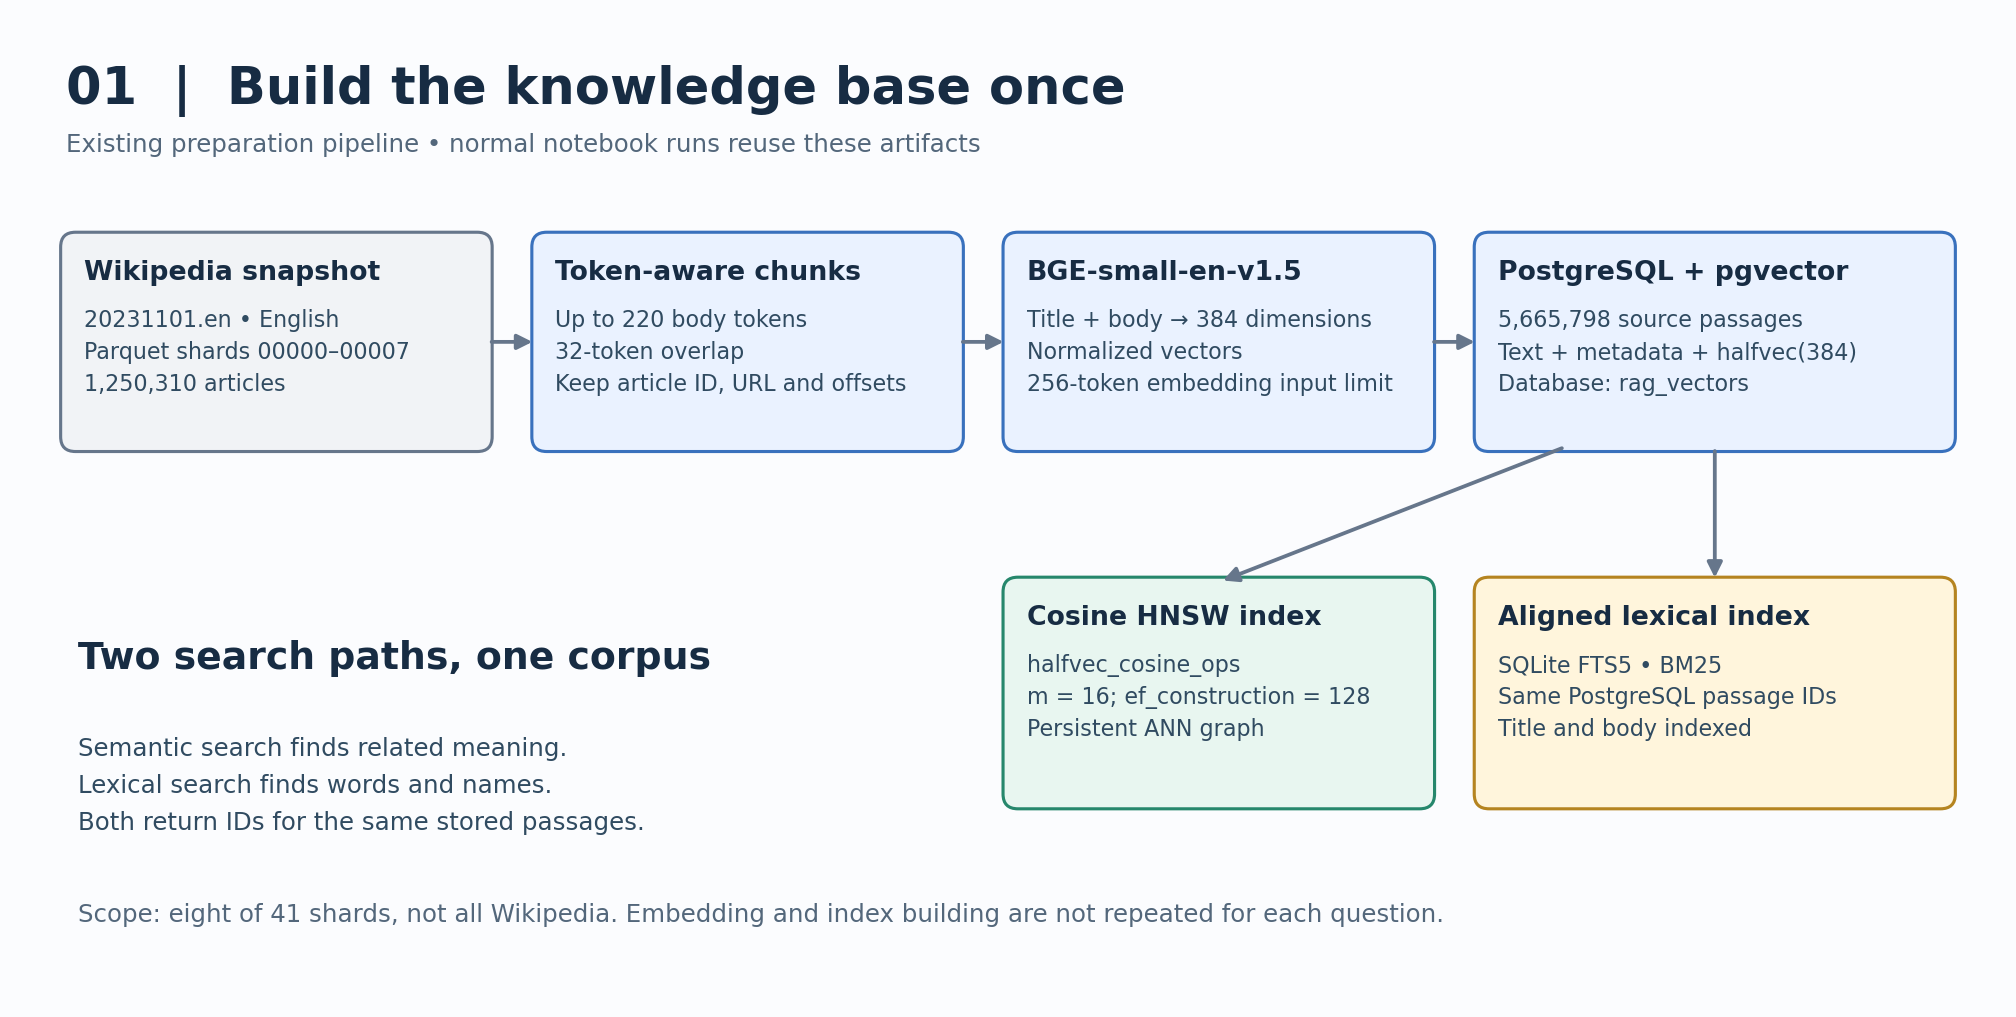

### Chunking: why and how

A Wikipedia article may discuss many subjects and exceed the model input limits. The ingestion chunker creates smaller search units, targeting **up to 220 body tokens**, preferring sentence boundaries and retaining a **32-token overlap**. It includes up to 28 title tokens in the embedding text and reduces the body when needed to keep the total embedding input within **256 tokens**.

Tokens are model-specific text units, not necessarily words. Overlap reduces boundary-related information loss but also creates redundant passages. Original character offsets preserve the exact text and allow source inspection. Passage IDs follow the form `article_id:char_start:char_end`; PostgreSQL also assigns a numeric row ID.

### Embedding: representing meaning numerically

`BAAI/bge-small-en-v1.5` converts each title-plus-body input into a normalized **384-dimensional vector**. One stored chunk has one vector with 384 components; this does not mean the chunk contains 384 words. Related meanings tend to have similar vector directions. The model revision is pinned at `5c38ec7c405ec4b44b94cc5a9bb96e735b38267a`.

The same embedding model is used for queries. Queries receive the model-specific prefix `Represent this sentence for searching relevant passages: ` before encoding. Using a different model for queries would place queries and stored passages in incompatible spaces, even if both models output 384 dimensions.

For vectors a and b, cosine similarity is:

$$\operatorname{cosine}(a,b)=\frac{a\cdot b}{\lVert a\rVert\lVert b\rVert}$$

Normalized vectors have unit length, so cosine similarity equals their dot product before storage rounding. This implementation nevertheless uses the **cosine operator and cosine index**, not a separate inner-product index.

### Storage and indexes: different responsibilities

PostgreSQL stores the canonical passage text, metadata and embedding. The pgvector extension supplies vector types, distance operators and ANN indexes. The vector is stored as **`halfvec(384)`**, using 16-bit floating-point components. This reduces vector storage compared with 32-bit `vector`, but introduces rounding; it does not remove dimensions. Text and database/index overhead still occupy additional space.

The existing **HNSW** index `chunks_half_hnsw` uses `halfvec_cosine_ops`, with **m=16** and **ef_construction=128**. HNSW is an approximate graph search structure: it avoids comparing a query against every stored vector. These settings control graph construction; **ef_search=200** controls query-time exploration. Higher search breadth can improve recall at a latency cost. An embedded row and an HNSW-indexed row are distinct concepts: storing a vector alone does not construct the search graph.

The B-tree index `chunks_article_start_idx` on `(article_id, char_start)` serves a different purpose: efficiently finding the first stored passage of a matched article. It is not the vector index.

### Why BM25 is a separate SQLite file

The lexical index is SQLite **FTS5**, stored in `data/wikipedia_pgvector_8shards_bm25.sqlite`. Its contentless index contains terms from passage titles and bodies, and its row IDs match PostgreSQL passage IDs. Displayed source text is fetched from PostgreSQL. This arrangement avoids using the older full-corpus SQLite index, whose corpus and chunk IDs differ.

BM25 ranks lexical matches using term frequency, inverse document frequency and document-length normalization. Names, identifiers and rare terms often benefit from lexical search; paraphrases may benefit from embeddings. This implementation uses real FTS5 BM25, not PostgreSQL `ts_rank` relabelled as BM25. The trade-off is maintaining two synchronized stores. Corpus fingerprints and counts are checked before querying; any future corpus change requires coordinated index maintenance.


## 4. Architecture B: the question-answering path

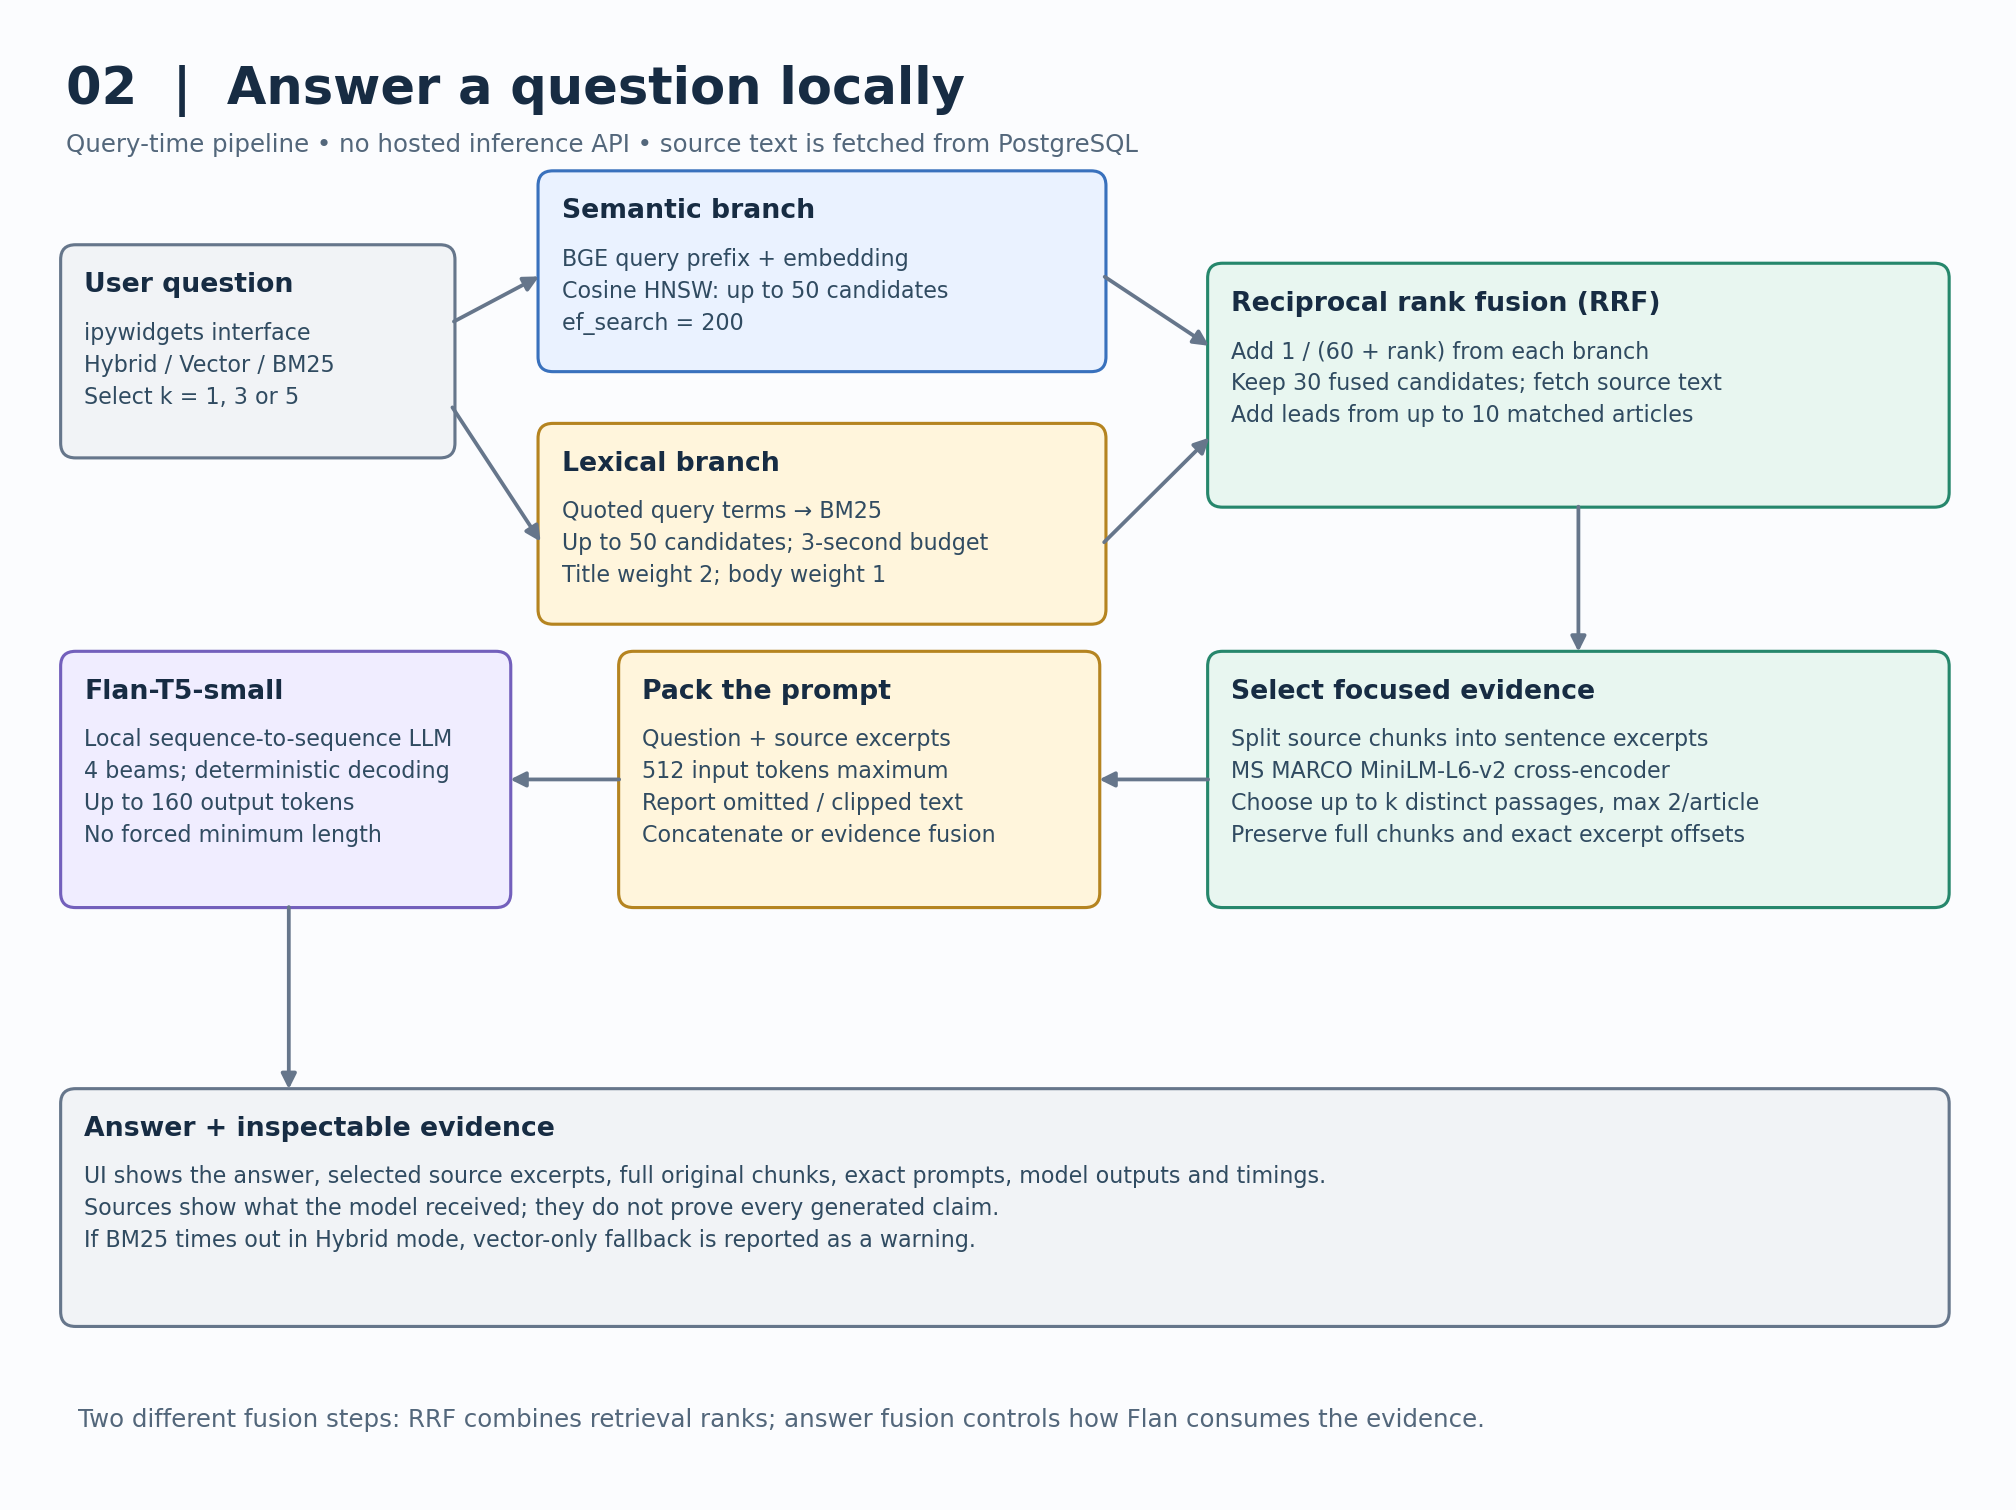

1. **Accept the question.** The widget exposes retrieval mode, passage count and answer-fusion method. Blank inputs and overly long questions are rejected.
2. **Run two retrieval branches in Hybrid mode.** The semantic branch embeds the query and uses PostgreSQL cosine HNSW to request up to 50 candidates. The lexical branch tokenizes the question, removes common question words, quotes remaining terms and combines them using OR. FTS5 BM25 uses title weight 2 and body weight 1 and requests up to 50 candidates.
3. **Fuse rankings.** Reciprocal rank fusion (RRF) combines candidate ranks rather than directly adding incomparable cosine and BM25 scores. A passage present in both branches receives contributions from both.
4. **Expand useful context.** Keep 30 fused candidates and add the introductory stored passage of up to ten matched articles. Definitions and key facts often occur in introductions. These passages still come from the same eight-shard database.
5. **Rerank exact source excerpts.** Split candidate chunks into sentence excerpts. `cross-encoder/ms-marco-MiniLM-L6-v2` scores each question/excerpt pair jointly. Select up to k distinct passages, at most two per article, retaining exact offsets and the full original chunk for inspection. Its pinned revision is `233902d25c440f23af6f7d6e94d2946bac0bee0a`.
6. **Pack evidence and generate.** Supply the question, source titles and selected excerpts to Flan-T5-small using the chosen fusion method. The explicit input budget is 512 tokens.
7. **Display and inspect.** Show the generated answer, evidence, original chunks, prompts, model outputs and stage timings. A displayed source means the model received that text; it is not automatic claim-level verification.

The RRF formula used here is:

$$\operatorname{RRF}(d)=\sum_{r\in\{\text{vector},\text{BM25}\}}\frac{1}{60+\operatorname{rank}_r(d)}$$

An absent passage contributes zero for that branch. For example, ranks 2 and 5 give `1/62 + 1/65 ≈ 0.0315`; a passage ranked first in only one branch receives `1/61 ≈ 0.0164`. These are ranking scores, not probabilities of correctness. FTS5's BM25 values sort in the opposite direction from similarity: lower values are better in this implementation.

### Embedding model versus reranker versus generator

| Component | Input | Output | Purpose |
|---|---|---|---|
| BGE embedding model | One query or passage | 384 numbers | Efficient semantic candidate retrieval |
| MiniLM cross-encoder | Question and source excerpt together | Relevance score | More detailed ranking of a small candidate set |
| Flan-T5-small | Question plus evidence text | Generated answer tokens | Answer synthesis |

The reranker does not create new embeddings for the whole corpus, and it does not answer the question. It is more expensive per candidate than vector comparison, so it operates after initial retrieval.


## 5. Architecture C: answer-fusion ablation

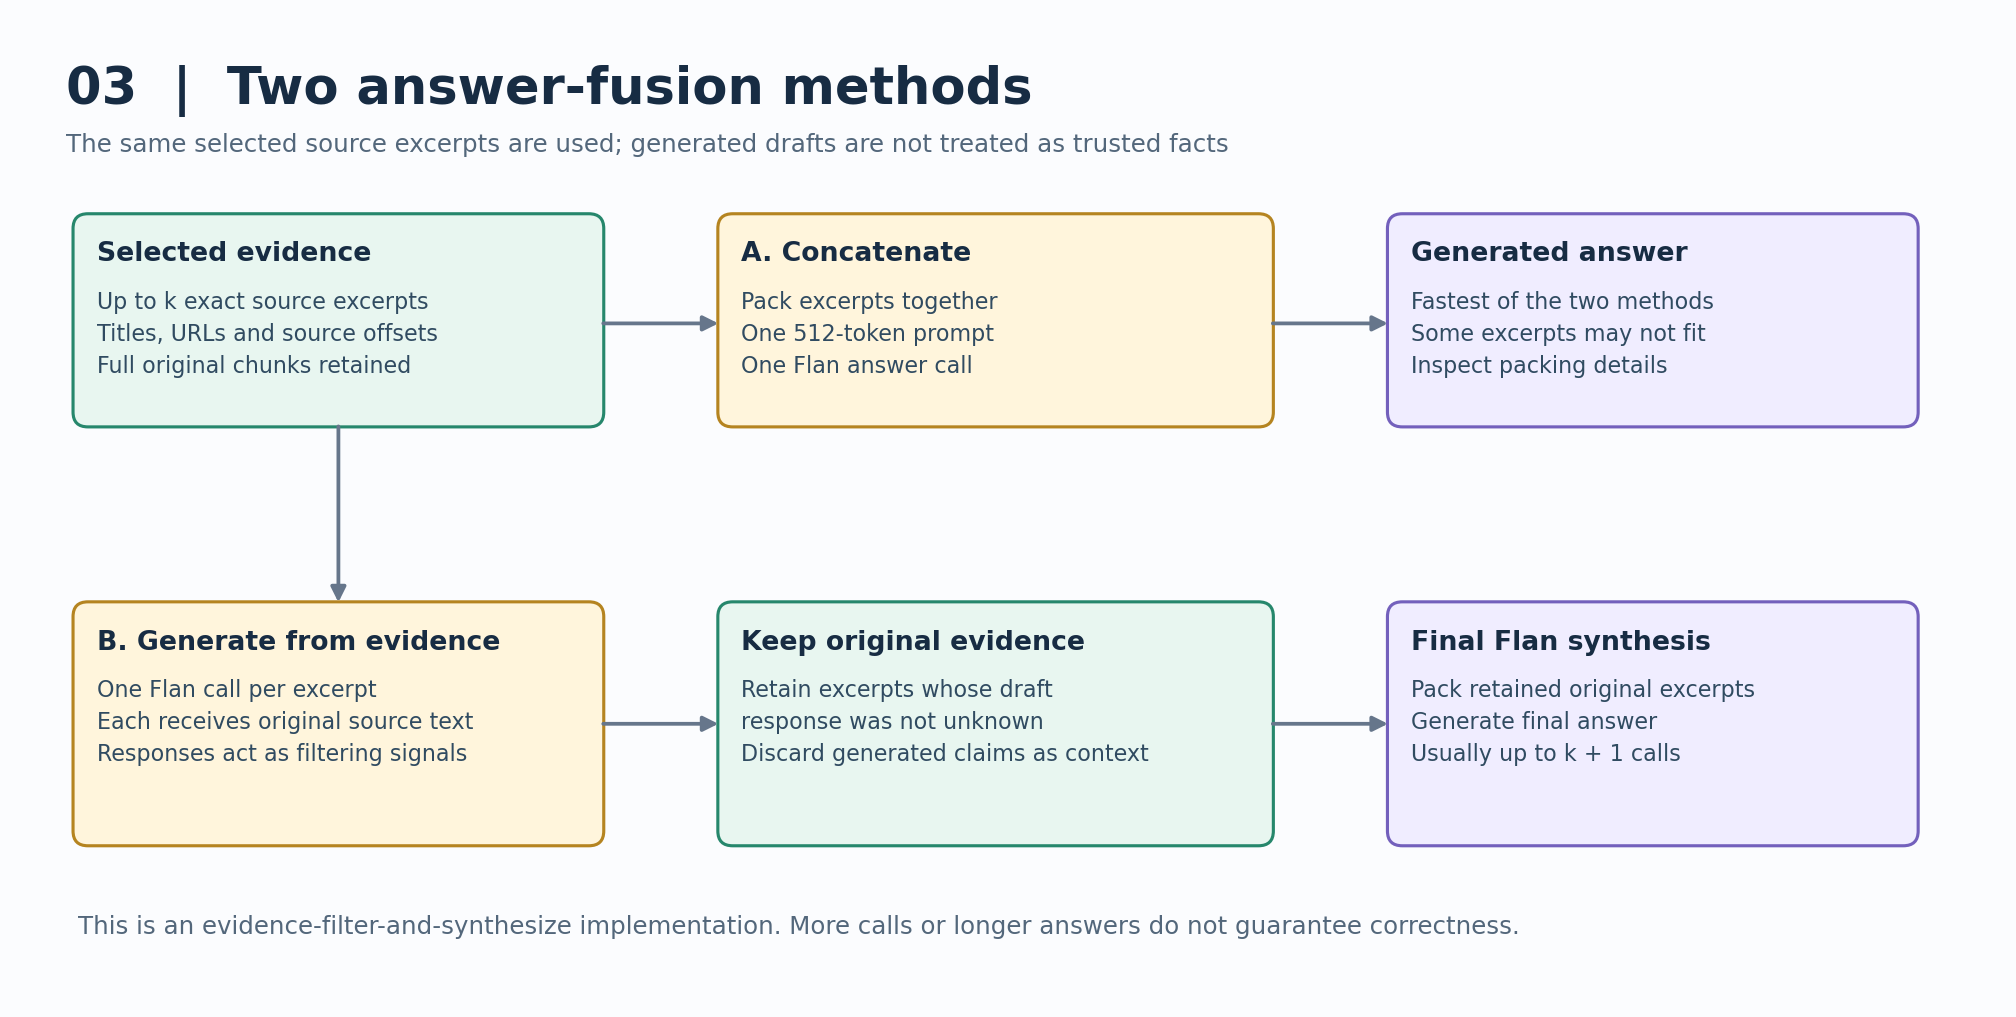

**Concatenate** combines selected excerpts into one prompt and makes one answer-generation call. It is simpler and usually faster, but the model can confuse facts across passages. Later excerpts that do not fit the 512-token budget are omitted. If the first excerpt itself is too long, an exact prefix is used and clipping is reported.

**Generate from evidence** makes a separate Flan call for each selected excerpt. If a response is not recognized as unknown, the corresponding **original excerpt** is retained. A final call synthesizes from retained source text that fits the budget. Generated intermediate claims are not inserted as trusted facts. This is an evidence-filter-and-synthesize method, not a faithful reproduction of the original Fusion-in-Decoder architecture. It normally needs up to k+1 model calls and can still wrongly discard useful evidence or generate an incorrect final answer.

RRF is **retrieval fusion**; these two alternatives are **answer fusion**. Changing one does not automatically change the other. The testable hypothesis is that more passages or more calls might improve coverage but can also increase distraction, latency and context pressure. Results must decide the trade-off.


## 6. Flan-T5-small and grounded generation

Flan-T5-small is the required local sequence-to-sequence generator. Generation uses **four beams**, no sampling, up to **160 new tokens**, and no forced minimum length. A larger output allowance is a ceiling, not a request to always produce that many tokens. Numeric source labels were removed after tests found the model sometimes returning labels instead of answers; label-only output is also rejected.

A short factual answer such as “Alfred Russel Wallace” can be appropriate. The code no longer rejects answers for exceeding 16 words or requires an entire answer to be copied verbatim from a source. Nevertheless, the small model often produces fragments. Experiments demanding prose sometimes yielded fluent factual errors, so the UI keeps concise generation. Grounding here means conditioning generation on retrieved evidence; it does not guarantee entailment, truth or perfect abstention.

**Worked example:** for “With whom did Darwin jointly publish his theory of evolution?”, earlier retrieval found a Darwin-related article but the final prompt lacked the useful sentence. The corrected evidence selector brings forward the source sentence beginning “In a joint publication with Alfred Russel Wallace…”. Flan now returns **Alfred Russel Wallace** in the tested k=1/3/5 configurations for both fusion modes. The answer is generated from retrieved evidence, not looked up from the evaluation answer key.


## 7. Local execution, latency and failure handling

Normal execution loads cached models and connects to local PostgreSQL/SQLite. No hosted model API is called. Initial model/data preparation required downloads, but query-time execution uses local files. Source URLs are references, not live web searches.

BM25 runs concurrently with query encoding/vector retrieval. If its **three-second budget** expires, Hybrid mode returns vector-only retrieval with an explicit warning; BM25-only mode raises a timeout. PostgreSQL statements have a ten-second timeout. A bounded 128-entry application cache avoids repeated work, but cache-hit timings must not be presented as uncached performance. Other errors are not silently treated as successful answers.

Normal flags remain `RUN_INGEST=False`, `BUILD_INDEX=False`, `RUN_EVALUATION=False` and `RUN_ANSWER_ABLATIONS=False`. Restarting the kernel reloads models; it does not require recreating embeddings or indexes. This notebook consumes existing indexes; `04_embed_wikipedia_shards_01_to_08.ipynb` handles ingestion and index preparation separately.


## 8. Test design and measured results

The completed suite contains **500 questions over 400 articles**: 150 curated factual development questions, 175 named-article questions and 175 description lookups. The 350 additional queries cover all eight shards. Source passages were checked against PostgreSQL and local Parquet text. Named-article and verbatim-description queries are easier than independently authored factual questions, and the sampling is not an unbiased topic distribution.

The main run used Hybrid retrieval, k=3, Concatenate and disabled application caches. Branch rankings were captured from each Hybrid request, not timed as separate standalone modes. A separate five-question regression covered both fusion methods and k=1/3/5 (30 combinations). It would be incorrect to claim every fusion/k combination was tested on all 500 questions.

| Question group | Questions | Expected article in final context | Answer-alias matches |
|---|---:|---:|---:|
| Curated factual questions | 150 | 137 | 104 / 150 |
| Named-article descriptions | 175 | 166 | Not scored: no adjudicated answer key |
| Description lookups | 175 | 148 | 93 / 175 |
| Total expected-source coverage | 500 | **451 / 500 (90.2%)** | Do not combine unequal answer tasks into one accuracy claim |

The exact gold passage reached final context for **431/500 (86.2%)**. All 500 completed without runtime errors; **26** used explicit degraded-retrieval warnings. On the original 150 questions, expected-answer matches improved from 87 to 104. This is a lexical diagnostic, not verified factual accuracy: it can miss valid paraphrases or reward a wrong sentence containing the right name. A different passage may also legitimately answer a question.

| Measured stage | Median | p95 |
|---|---:|---:|
| Query embedding | 10.6 ms | 14.3 ms |
| HNSW vector query | 253.4 ms | 394.4 ms |
| BM25 branch | 847.0 ms | 3,001.1 ms |
| Evidence reranking | 605.1 ms | 959.2 ms |
| Generation | 113.1 ms | 345.7 ms |
| End-to-end | **1,609.6 ms** | **3,817.1 ms** |

These measurements are from this Mac and this workload, with uncontrolled OS/database caches. Parallel branch times overlap. They do not establish a sub-10-ms guarantee, a concurrency benchmark, or production capacity.


## 9. Limitations, conclusions and future work

Retrieval and generation are separate failure points. An article can be retrieved while the right sentence is missed; the right sentence can reach the model and still produce a wrong answer. HNSW is approximate, half-precision vectors introduce rounding, heuristic sentence splitting can lose context, and a 512-token prompt restricts evidence coverage. The eight-shard corpus and 2023 snapshot also restrict what can be answered.

The project demonstrates offline semantic and lexical retrieval, rank fusion, focused evidence selection, local Flan generation and reproducible evaluation at a substantial corpus size. It does **not** establish universal accuracy. Multi-user operation would require access control, connection management, corpus-version coordination, monitoring and recovery testing.

Possible future experiments—not implemented by this documentation—include better context selection for multi-sentence facts, calibrated abstention, held-out human-reviewed QA, negative/ambiguous questions, controlled cold/warm latency measurements and generator fine-tuning. Any change should rerun the same regression suite and retain the Flan-T5-small requirement unless the project specification permits alternatives.


## 10. Demonstration and viva checklist

1. Run the existing setup cells with ingestion and building disabled. Confirm coverage reports shards 00000–00007.
2. Ask the Darwin question and inspect the selected excerpt, original source chunk and exact Flan prompt.
3. Compare k=1/3/5 and both answer-fusion modes. Observe which evidence actually fits and how call count affects latency.
4. Explain why embeddings, the HNSW graph, the BM25 index and the language model serve different purposes.
5. Show a failed question as well as a successful one. Identify whether the failure is retrieval, evidence selection, generation or an inadequate answer key.
6. Present the 500-question results with their group-specific limitations, rather than calling a source hit “answer accuracy”.

The reproducible evaluator and detailed logs are in `docs/hybrid_rag/`. Use `RAG_500_VALIDATION.md` for the full test report, `rag_test_questions_500.json` for the question bank and `evaluate_rag_500.py` to rerun evaluation. This chapter follows the teaching sequence of the supplied RAG session notebook, but documents this project's actual components rather than its FAISS/Qwen demonstration setup.
